# **Dataset Abalone: Klasifikasi, Regresi, dan Clustering**

**Data:** dataset Abalone dari UCI (Nash dkk., 1994; 4.177 abalone, Tasmania).

**Tujuan:** memprediksi jenis kelamin (Sex) abalone dari ukuran fisiknya menggunakan SVM  Random Forest, memprediksi jumlah ring abalone sebagai proksi untuk usia dengan model regresi, dan menemukan pola pengelompokan berdasarkan data dengan K-Means, Spectral, dan Hierarchical clustering.

In [ ]:
import warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder, PolynomialFeatures
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             mean_squared_error, mean_absolute_error, r2_score,
                             silhouette_score, calinski_harabasz_score, davies_bouldin_score,
                             adjusted_rand_score, normalized_mutual_info_score,
                             homogeneity_score, completeness_score)
from sklearn.inspection import permutation_importance
from sklearn.decomposition import PCA
from sklearn.neighbors import kneighbors_graph
from sklearn.cluster import KMeans, SpectralClustering, AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet
from scipy.spatial.distance import pdist
from scipy.sparse.csgraph import laplacian
from scipy.linalg import eigh

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 4)
pd.set_option("display.width", 140)
RANDOM_STATE = 42
SEX_COLORS = {"F": "#d1495b", "M": "#00798c", "I": "#edae49"}

## **1. Deskripsi Variabel Dataset Abalone**

Berikut merupakan penjelasan variabel-variabel yang terdapat dalam dataset abalone:

| Variabel | Tipe Data | Satuan | Deskripsi |
| :--- | :--- | :--- | :--- |
| **Sex** | Nominal | - | Jenis kelamin: M (Jantan), F (Betina), atau I (Infant/Belum dewasa). |
| **Length** | Kontinu | mm | Ukuran panjang cangkang maksimum. |
| **Diameter** | Kontinu | mm | Ukuran diameter (tegak lurus terhadap panjang cangkang). |
| **Height** | Kontinu | mm | Tinggi cangkang (termasuk daging di dalamnya). |
| **Whole_weight** | Kontinu | gram | Berat total keseluruhan abalone. |
| **Shucked_weight** | Kontinu | gram | Berat daging abalone (tanpa cangkang dan jeroan). |
| **Viscera_weight** | Kontinu | gram | Berat jeroan (setelah dikeringkan dari darah). |
| **Shell_weight** | Kontinu | gram | Berat cangkang setelah dikeringkan. |
| **Rings** | Integer (Bilangan Bulat)| - | Jumlah cincin pada cangkang. Nilai ini ditambah 1,5 untuk memperkirakan umur abalone dalam satuan tahun. |

In [ ]:
cols = ["Sex", "Length", "Diameter", "Height", "Whole_weight",
        "Shucked_weight", "Viscera_weight", "Shell_weight", "Rings"]
df_raw = pd.read_csv("abalone.data", header=None, names=cols)
print("Ukuran data (baris, kolom):", df_raw.shape)
display(df_raw.head(10))
print()
df_raw.info()

Ukuran data (baris, kolom): (4177, 9)


,Sex,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7
5,I,0.425,0.300,0.095,0.3515,0.1410,0.0775,0.120,8
6,F,0.530,0.415,0.150,0.7775,0.2370,0.1415,0.330,20
7,F,0.545,0.425,0.125,0.7680,0.2940,0.1495,0.260,16
8,M,0.475,0.370,0.125,0.5095,0.2165,0.1125,0.165,9
9,F,0.550,0.440,0.150,0.8945,0.3145,0.1510,0.320,19



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4177 entries, 0 to 4176
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Sex             4177 non-null   object 
 1   Length          4177 non-null   float64
 2   Diameter        4177 non-null   float64
 3   Height          4177 non-null   float64
 4   Whole_weight    4177 non-null   float64
 5   Shucked_weight  4177 non-null   float64
 6   Viscera_weight  4177 non-null   float64
 7   Shell_weight    4177 non-null   float64
 8   Rings           4177 non-null   int64  
dtypes: float64(7), int64(1), object(1)
memory usage: 293.8+ KB


In [ ]:
num_features = [
    "Length",
    "Diameter",
    "Height",
    "Whole_weight",
    "Shucked_weight",
    "Viscera_weight",
    "Shell_weight",
]

print("Informasi missing value per kolom:")
print(df_raw.isna().sum().to_string())

print("\nJumlah baris duplikat:", df_raw.duplicated().sum())

print("\nKategori pada kolom Sex:", sorted(df_raw["Sex"].unique()))

print("\nJumlah nilai nol pada kolom numerik:")
print((df_raw[num_features + ["Rings"]] == 0).sum().to_string())

# Pemeriksaan konsistensi fisik
print("\nValidasi konsistensi fisik:")
parts = df_raw[["Shucked_weight", "Viscera_weight", "Shell_weight"]].sum(axis=1)

invalid_weight = (df_raw["Whole_weight"] < parts).sum()
print(
    f"- Anomali berat: ada {invalid_weight} baris di mana berat total (whole weight) lebih kecil dari jumlah berat bagian-bagiannya (daging + jeroan + cangkang)."
)

invalid_diam = (df_raw["Diameter"] > df_raw["Length"]).sum()
print(
    f"- Anomali dimensi: ada {invalid_diam} baris di mana diameter lebih besar daripada panjang cangkang."
)

invalid_height = (df_raw["Height"] > df_raw["Length"]).sum()
print(
    f"- Anomali dimensi: ada {invalid_height} baris di mana tinggi cangkang lebih besar daripada panjangnya."
)

print("\nBaris dengan tinggi (height) = 0:")
display(df_raw[df_raw["Height"] == 0])

print("Baris dengan tinggi (height) ekstrem (> 0.3):")
display(df_raw[df_raw["Height"] > 0.3])

Informasi missing value per kolom:
Sex               0
Length            0
Diameter          0
Height            0
Whole_weight      0
Shucked_weight    0
Viscera_weight    0
Shell_weight      0
Rings             0

Jumlah baris duplikat: 0

Kategori pada kolom Sex: ['F', 'I', 'M']

Jumlah nilai nol pada kolom numerik:
Length            0
Diameter          0
Height            2
Whole_weight      0
Shucked_weight    0
Viscera_weight    0
Shell_weight      0
Rings             0

Validasi konsistensi fisik:
- Anomali berat: ada 155 baris di mana berat total (whole weight) lebih kecil dari jumlah berat bagian-bagiannya (daging + jeroan + cangkang).
- Anomali dimensi: ada 1 baris di mana diameter lebih besar daripada panjang cangkang.
- Anomali dimensi: ada 1 baris di mana tinggi cangkang lebih besar daripada panjangnya.

Baris dengan tinggi (height) = 0:


,Sex,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings
1257,I,0.430,0.34,0.0,0.428,0.2065,0.0860,0.1150,8
3996,I,0.315,0.23,0.0,0.134,0.0575,0.0285,0.3505,6


Baris dengan tinggi (height) ekstrem (> 0.3):


,Sex,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings
1417,M,0.705,0.565,0.515,2.210,1.1075,0.4865,0.5120,10
2051,F,0.455,0.355,1.130,0.594,0.3320,0.1160,0.1335,8


### Temuan Kualitas Data dan Keputusan Pembersihan

* **Tidak ada missing value dan tidak ada baris duplikat.** Satu-satunya kolom kategorikal hanyalah fitur `Sex` (F, I, M) yang merupakan target dalam klasifikasi bagian pertama.
* **Dua baris memiliki `Height = 0`** dimana secara fisik, cangkang tidak mungkin setebal nol. Salah satunya bahkan memiliki berat cangkang (0,3505) yang lebih besar daripada berat total (0,134) yang mengindikasikan kesalahan pencatatan.
* **Satu baris memiliki `Height = 1,13`** (setara 226 mm) pada cangkang dengan `Length = 0,455` (setara 91 mm) yang artinya nilainya tinggi lebih besar daripada panjangnya. Hal ini dapat dikategorikan sebagai kesalahan dalam imputasi (mungkin seharusnya 0,113). Dimana, kesalahan tunggal ini membuat kurtosis `Height` melonjak hingga sekitar 77 dan menarik sumbu PCA sehingga baris ini diputuskan untuk dibuang.
* **Aturan pembersihan:** Pertahankan baris yang memenuhi kondisi `0 < Height <= Length`. Aturan ini membuang **3 baris**, menyisakan **4.174 baris** data bersih.
* **Terdapat 155 baris** di mana berat total (`Whole_weight`) sedikit lebih kecil daripada jumlah berat bagian (`Shucked` + `Viscera` + `Shell`). Hal ini dapat dianulir secara biologis karena adanya penguapan air dan keluarnya cairan/darah di antara sesi pengukuran sehingga baris-baris ini **dipertahankan**.
* **Hewan berukuran besar atau tua** (dengan nilai `Rings` hingga 29 dan cangkang yang berat) **dipertahankan**. Hal ini dikarekan oleh data tersebut merepresentasikan kondisi biologis yang nyata dan bukan kesalahan data. Dampaknya, dibutuhkan model yang *robust* (seperti SVM-RBF dan Random Forest) mampu menanganinya dengan baik sementara untuk regresi linear pengaruhnya perlu diperiksa melalui analisis plot residual.
* **Fitur tambahan:** Terdapat dua kolom yang dibuat khusus untuk keperluan analisis yaitu `Age_years = Rings + 1.5` serta `Age_group` (kategori *Young* $\le$ 8 cincin, *Middle* 9–10 cincin, dan *Old* $\ge$ 11 cincin) mengikuti standar pengelompokan yang umum digunakan dalam literatur abalone.

In [ ]:
# Aturan pembersihan: Height harus > 0 dan tidak lebih besar daripada Length.
#  - 2 baris punya Height = 0 (mustahil secara fisik)
#  - 1 baris punya Height = 1.13 (226 mm) pada cangkang sepanjang 91 mm -> hampir pasti salah catat
mask_valid = (df_raw["Height"] > 0) & (df_raw["Height"] <= df_raw["Length"])
print("Baris dibuang:", (~mask_valid).sum())
df = df_raw[mask_valid].reset_index(drop=True).copy()

# Kolom bantu hanya untuk analisis (tidak pernah dipakai sebagai prediktor dirinya sendiri)
df["Age_years"] = df["Rings"] + 1.5                      # abalone.names: umur = rings + 1.5
df["Age_group"] = pd.cut(df["Rings"], bins=[0, 8, 10, 100],
                         labels=["Young (<=8)", "Middle (9-10)", "Old (>=11)"])
print("Ukuran data setelah pembersihan:", df.shape)
display(df.describe().T)
print("Catatan: fitur kontinu dibagi 200 pada file UCI asli (lihat abalone.names).")
print("Kalikan 200 untuk mendapat mm (Length, Diameter, Height) atau gram (berat).")

Baris dibuang: 3
Ukuran data setelah pembersihan: (4174, 11)


,count,mean,std,min,25%,50%,75%,max
Length,4174.0,0.5241,0.1201,0.0750,0.4500,0.545,0.6150,0.8150
Diameter,4174.0,0.4080,0.0992,0.0550,0.3500,0.425,0.4800,0.6500
Height,4174.0,0.1393,0.0388,0.0100,0.1150,0.140,0.1650,0.5150
Whole_weight,4174.0,0.8291,0.4904,0.0020,0.4421,0.800,1.1538,2.8255
Shucked_weight,4174.0,0.3595,0.2220,0.0010,0.1861,0.336,0.5020,1.4880
Viscera_weight,4174.0,0.1807,0.1096,0.0005,0.0935,0.171,0.2530,0.7600
Shell_weight,4174.0,0.2389,0.1392,0.0015,0.1300,0.234,0.3289,1.0050
Rings,4174.0,9.9356,3.2245,1.0000,8.0000,9.000,11.0000,29.0000
Age_years,4174.0,11.4356,3.2245,2.5000,9.5000,10.500,12.5000,30.5000


Catatan: fitur kontinu dibagi 200 pada file UCI asli (lihat abalone.names).
Kalikan 200 untuk mendapat mm (Length, Diameter, Height) atau gram (berat).


## **2. Exploratory Data Analysis (EDA)**

Analisis eksplorasi data ini akan dilakukan untuk menjawab beberapa pertanyaan sebagai berikut:

1. Bagaimana distribusi dari tiap variabel?
2. Seberapa seimbang proporsi kelas pada variabel target?
3. Bagaimana karakteristik dan perbedaan fisik antar jenis kelamin (*Sex*)?
4. Bagaimana pola hubungan antar variabel independen serta korelasinya dengan jumlah cincin (`Rings`)?
5. Seperti apa struktur dan sebaran keseluruhan data jika dilihat melalui reduksi dimensi (PCA)?

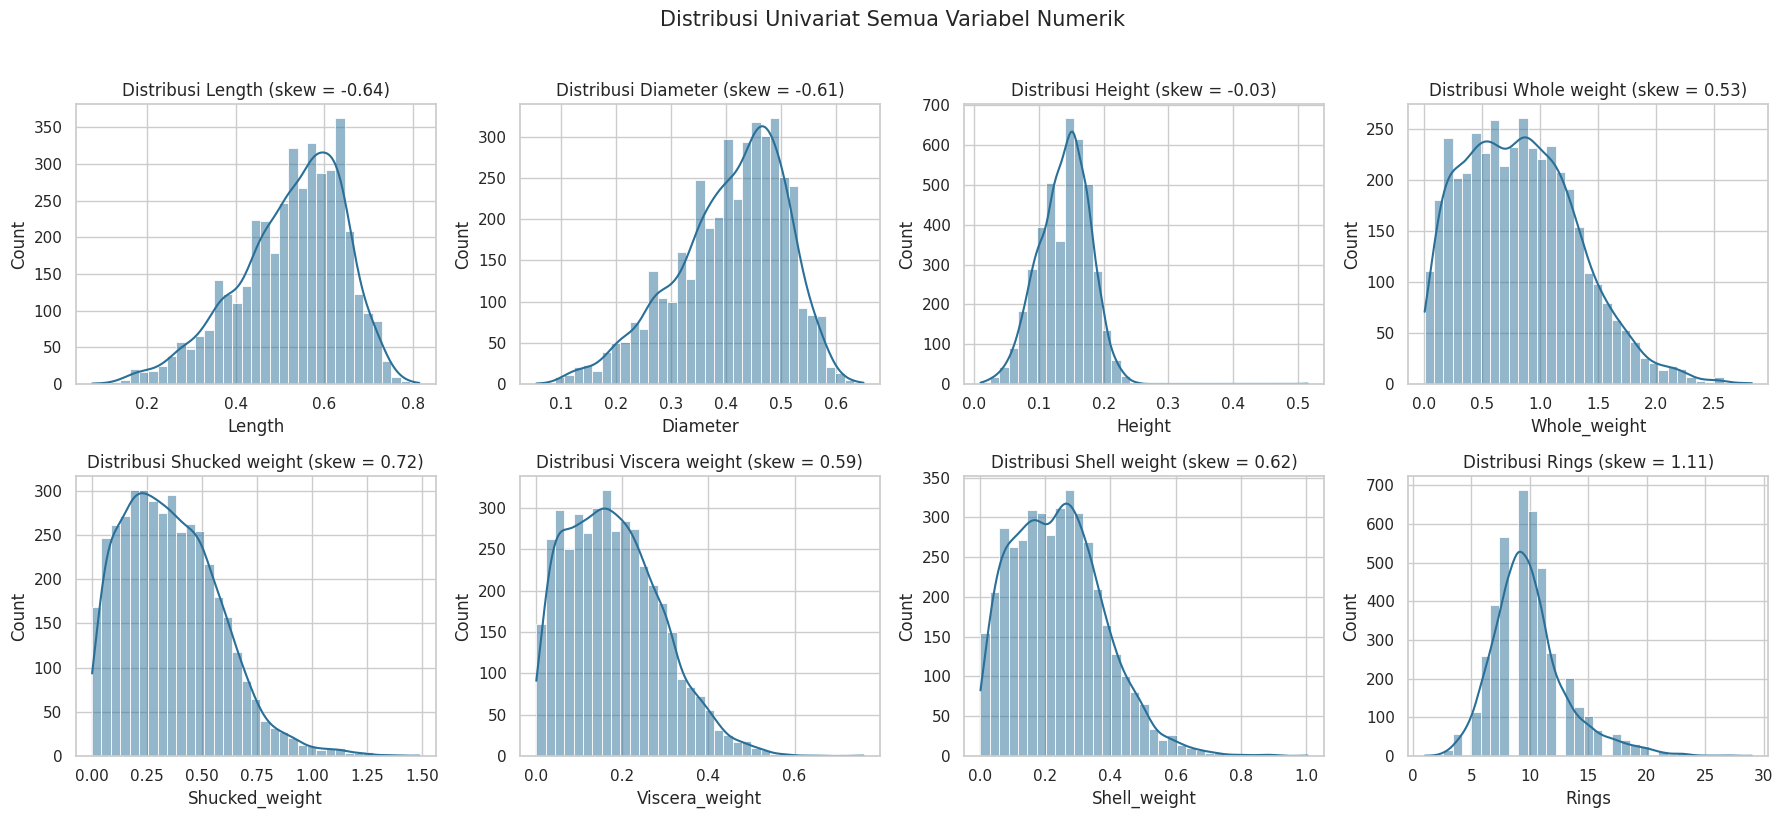

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), num_features + ["Rings"]):
    sns.histplot(df[col], kde=True, ax=ax, color="#2a6f97", bins=35)
    ax.set_title(
        f"Distribusi {col.replace('_', ' ')} (skew = {df[col].skew():.2f})"
    )
plt.suptitle(
    "Distribusi Univariat Semua Variabel Numerik", y=1.02, fontsize=15
)
plt.tight_layout()
plt.show()

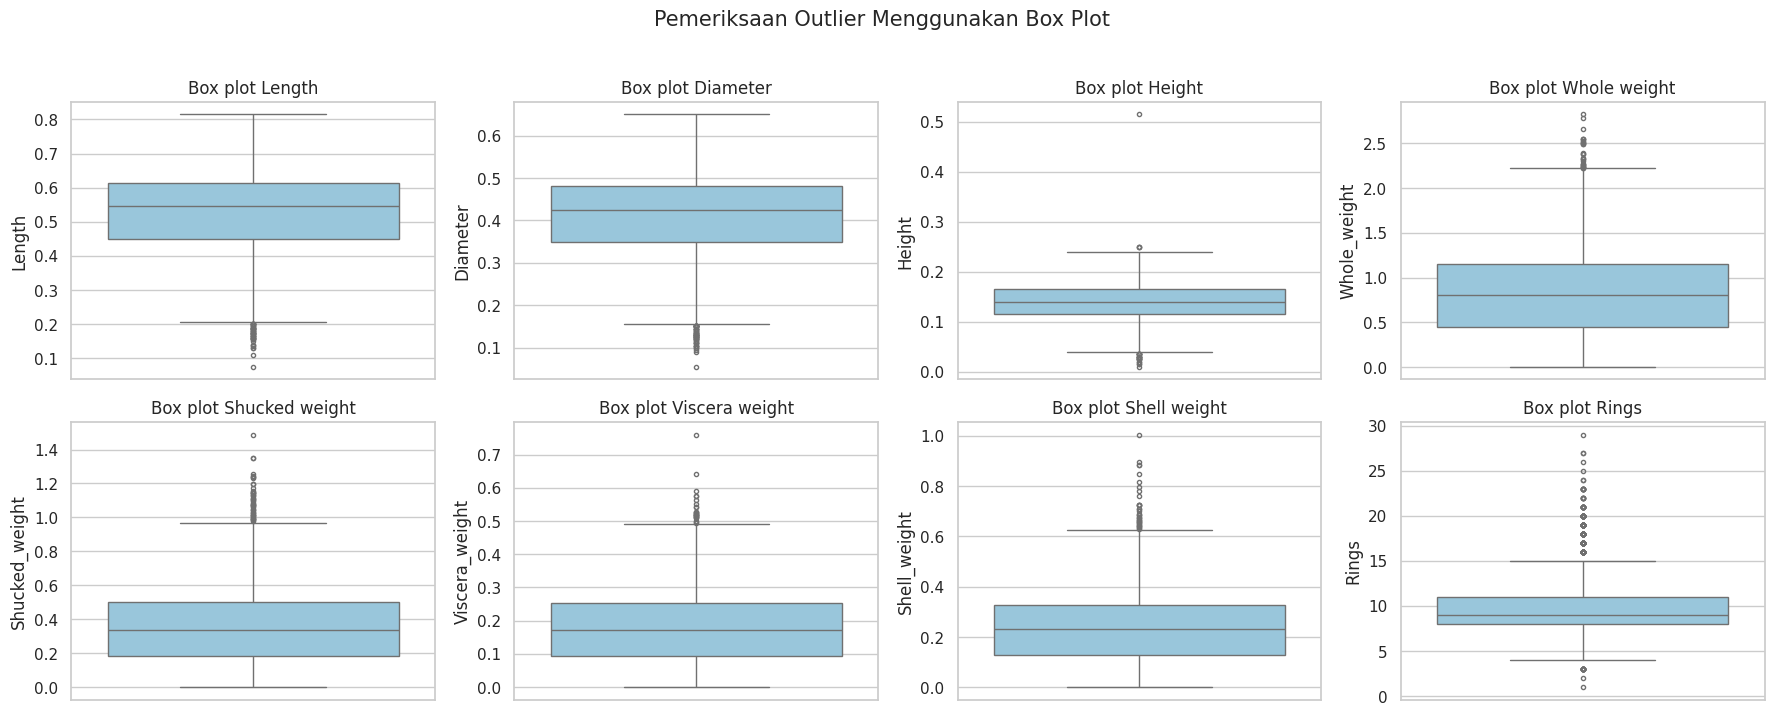

,Variable,Skewness,Excess kurtosis,IQR outliers,% outliers
0,Length,-0.641,0.068,49,1.174
1,Diameter,-0.611,-0.043,59,1.414
2,Height,-0.030,1.802,26,0.623
3,Whole_weight,0.530,-0.024,29,0.695
4,Shucked_weight,0.719,0.594,48,1.150
5,Viscera_weight,0.591,0.084,26,0.623
6,Shell_weight,0.621,0.532,35,0.839
7,Rings,1.113,2.329,278,6.660


In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, col in zip(axes.ravel(), num_features + ["Rings"]):
    sns.boxplot(y=df[col], ax=ax, color="#8ecae6", fliersize=3)
    ax.set_title(f"Box plot {col.replace('_', ' ')}")
plt.suptitle("Pemeriksaan Outlier Menggunakan Box Plot", y=1.02, fontsize=15)
plt.tight_layout()
plt.show()

# Ringkasan kuantitatif: skewness, kurtosis, dan jumlah outlier IQR
rows = []
for col in num_features + ["Rings"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    rows.append([col, df[col].skew(), df[col].kurt(), n_out, (100 * n_out) / len(df)])

shape_tbl = pd.DataFrame(
    rows,
    columns=["Variable", "Skewness", "Excess kurtosis", "IQR outliers", "% outliers"],
)
display(shape_tbl.round(3))

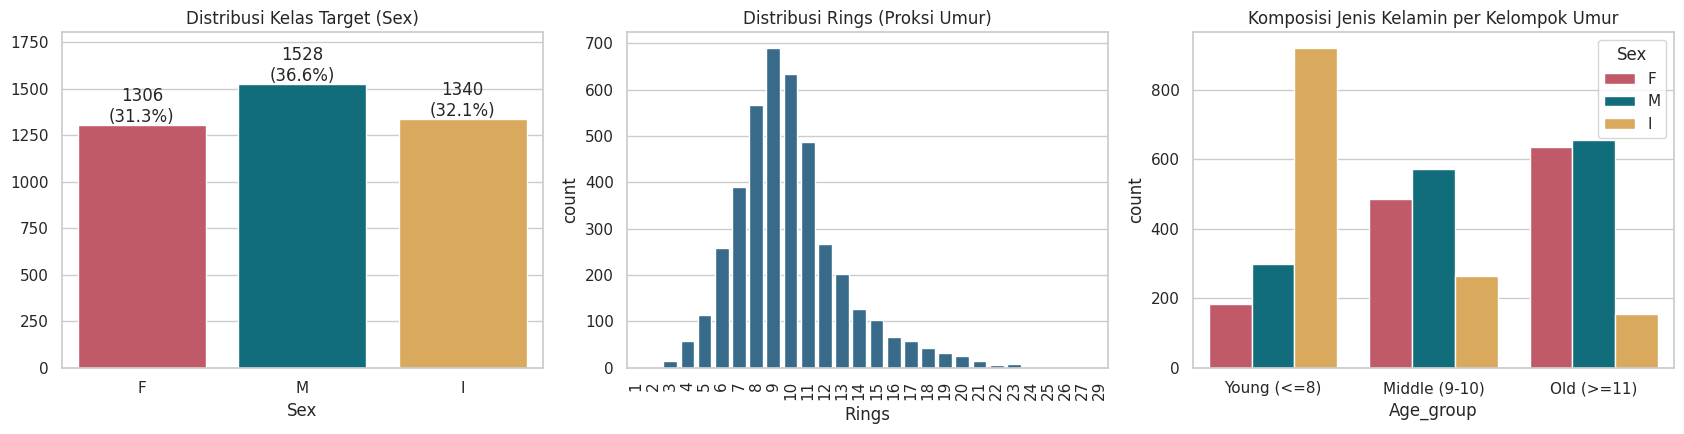

Proporsi Kelas Target (%):
Sex
M    36.61
I    32.10
F    31.29

Distribusi Jenis Kelamin per Kelompok Umur (% Baris):


Age_group,Young (<=8),Middle (9-10),Old (>=11)
Sex,,,
F,14.2,37.2,48.6
I,68.7,19.8,11.6
M,19.6,37.4,43.0


In [ ]:
# eda_sex_counts
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
order = ["F", "M", "I"]
cnt = df["Sex"].value_counts().reindex(order)

# 1. Barplot Keseimbangan Kelas Target
sns.barplot(
    x=cnt.index, y=cnt.values, palette=SEX_COLORS, order=order, ax=axes[0]
)
for i, v in enumerate(cnt.values):
    axes[0].text(i, v + 15, f"{v}\n({100 * v / len(df):.1f}%)", ha="center")
axes[0].set_title("Distribusi Kelas Target (Sex)")
axes[0].set_ylim(0, cnt.max() * 1.18)

# 2. Countplot Distribusi Rings
sns.countplot(x="Rings", data=df, color="#2a6f97", ax=axes[1])
axes[1].set_title("Distribusi Rings (Proksi Umur)")
axes[1].tick_params(axis="x", rotation=90)

# 3. Countplot Komposisi Sex per Kelompok Umur
sns.countplot(
    x="Age_group",
    hue="Sex",
    data=df,
    palette=SEX_COLORS,
    hue_order=order,
    ax=axes[2],
)
axes[2].set_title("Komposisi Jenis Kelamin per Kelompok Umur")

plt.tight_layout()
plt.show()

# Ringkasan Text & Crosstab
print("Proporsi Kelas Target (%):")
print((df["Sex"].value_counts(normalize=True) * 100).round(2).to_string())

print("\nDistribusi Jenis Kelamin per Kelompok Umur (% Baris):")
display((pd.crosstab(df["Sex"], df["Age_group"], normalize="index") * 100).round(1))

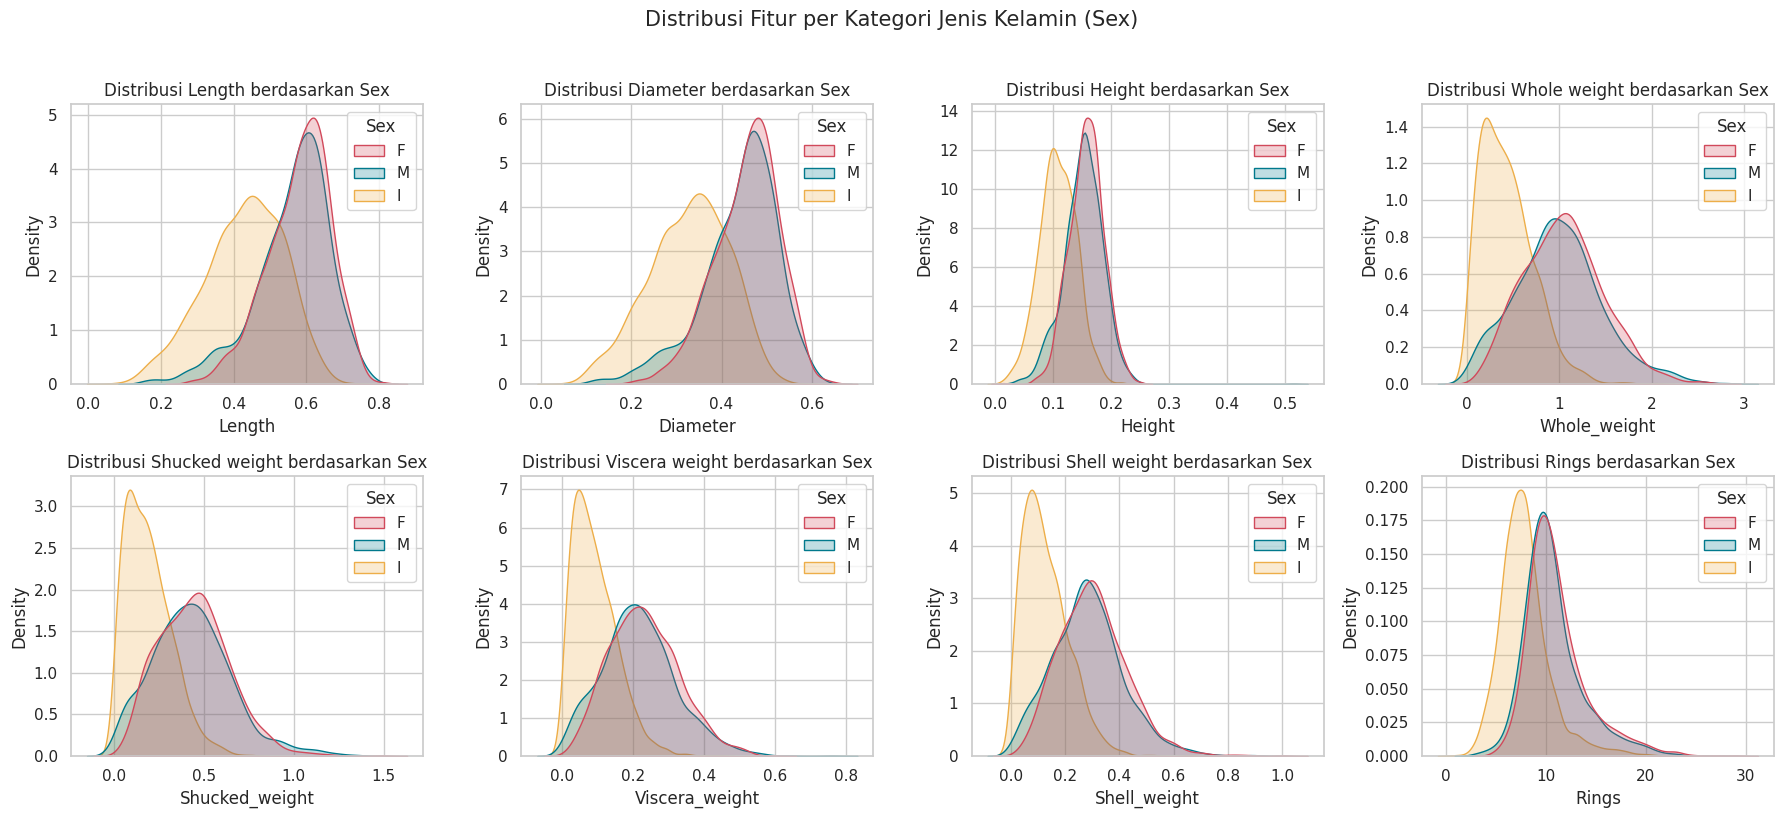

In [ ]:
# eda_by_sex_kde
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), num_features + ["Rings"]):
    sns.kdeplot(
        data=df,
        x=col,
        hue="Sex",
        palette=SEX_COLORS,
        fill=True,
        alpha=0.25,
        common_norm=False,
        ax=ax,
        hue_order=["F", "M", "I"],
    )
    ax.set_title(f"Distribusi {col.replace('_', ' ')} berdasarkan Sex")
plt.suptitle("Distribusi Fitur per Kategori Jenis Kelamin (Sex)", y=1.02, fontsize=15)
plt.tight_layout()
plt.show()

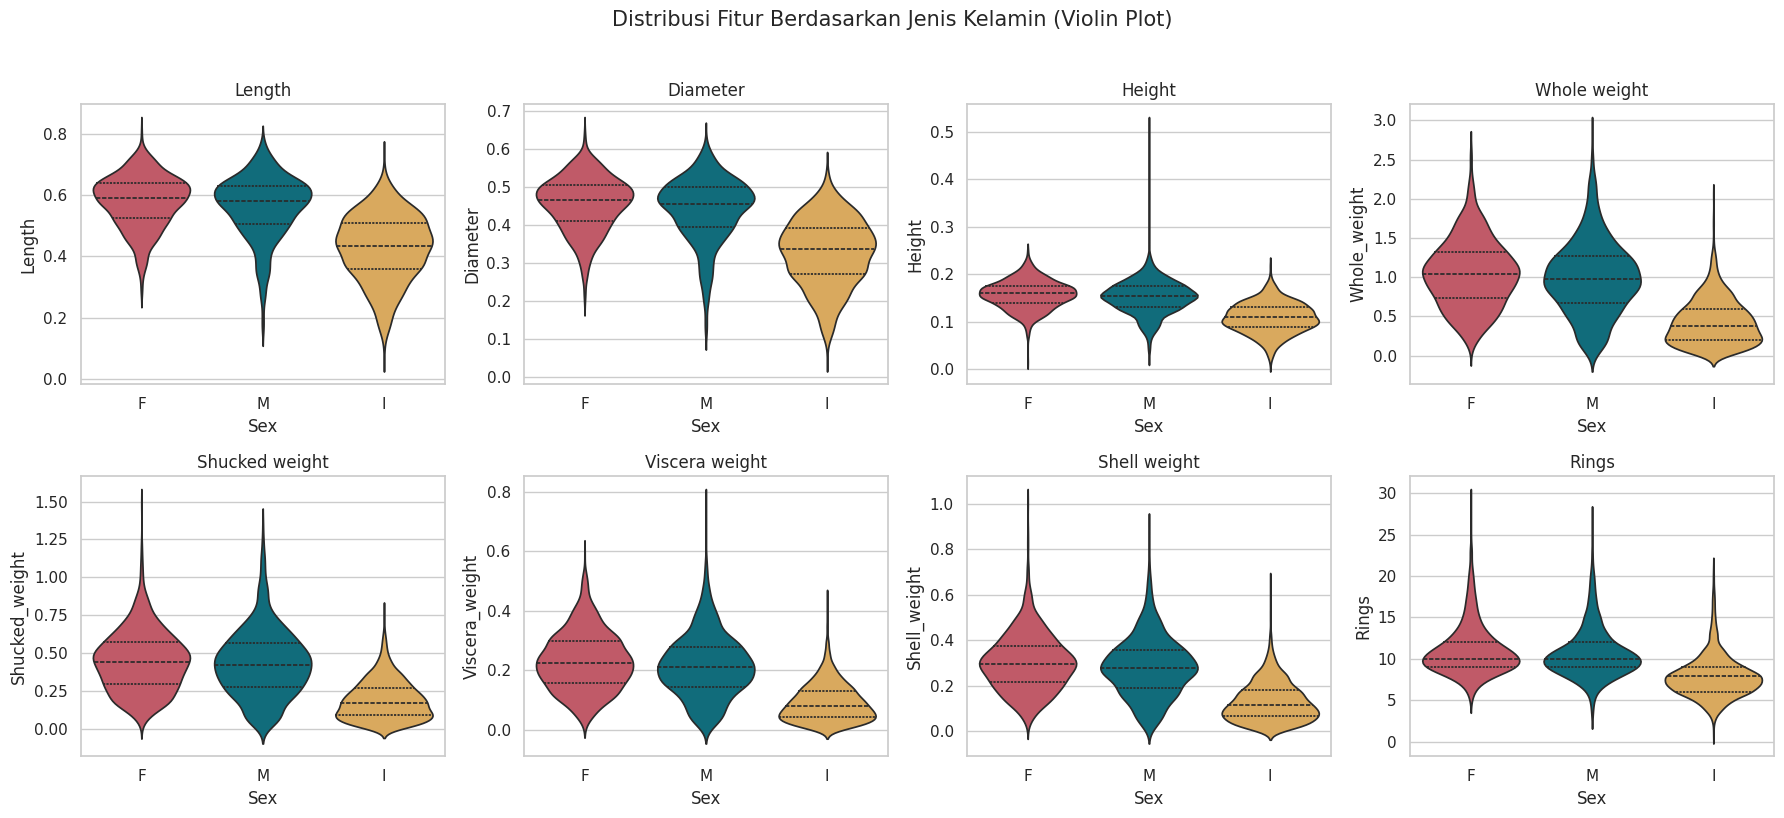

Ringkasan Rata-rata dan Median per Jenis Kelamin (Sex):


Sex                         F      I       M
Length         mean     0.579  0.428   0.561
               median   0.590  0.435   0.580
Diameter       mean     0.455  0.327   0.439
               median   0.465  0.335   0.455
Height         mean     0.157  0.108   0.151
               median   0.160  0.110   0.155
Whole_weight   mean     1.047  0.432   0.991
               median   1.038  0.384   0.976
Shucked_weight mean     0.446  0.191   0.433
               median   0.440  0.170   0.422
Viscera_weight mean     0.231  0.092   0.216
               median   0.224  0.080   0.210
Shell_weight   mean     0.302  0.128   0.282
               median   0.295  0.113   0.276
Rings          mean    11.132  7.892  10.705
               median  10.000  8.000  10.000

In [ ]:
# eda_by_sex_violin
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), num_features + ["Rings"]):
    sns.violinplot(
        data=df,
        x="Sex",
        y=col,
        order=["F", "M", "I"],
        palette=SEX_COLORS,
        ax=ax,
        inner="quartile",
    )
    ax.set_title(col.replace("_", " "))
plt.suptitle(
    "Distribusi Fitur Berdasarkan Jenis Kelamin (Violin Plot)", y=1.02, fontsize=15
)
plt.tight_layout()
plt.show()

print("Ringkasan Rata-rata dan Median per Jenis Kelamin (Sex):")
display(
    df.groupby("Sex")[num_features + ["Rings"]]
    .agg(["mean", "median"])
    .round(3)
    .T
)

In [ ]:
# Uji statistik: seberapa baik tiap fitur memisahkan kategori Sex
rows = []
for col in num_features + ["Rings"]:
    g = {s: df.loc[df["Sex"] == s, col] for s in ["F", "M", "I"]}
    h, p_kw = stats.kruskal(g["F"], g["M"], g["I"])
    _, p_fm = stats.mannwhitneyu(g["F"], g["M"])
    _, p_ia = stats.mannwhitneyu(g["I"], pd.concat([g["F"], g["M"]]))
    # effect size untuk F vs M: Cohen's d
    sp = np.sqrt((g["F"].var() + g["M"].var()) / 2)
    d_fm = (g["F"].mean() - g["M"].mean()) / sp
    sp2 = np.sqrt((g["I"].var() + pd.concat([g["F"], g["M"]]).var()) / 2)
    d_ia = (pd.concat([g["F"], g["M"]]).mean() - g["I"].mean()) / sp2
    rows.append([col, h, p_kw, p_fm, d_fm, p_ia, d_ia])
test_tbl = pd.DataFrame(rows, columns=["Variable", "Kruskal H", "p (3 groups)", "p (F vs M)",
                                       "Cohen d (F-M)", "p (I vs adult)", "Cohen d (adult-I)"])
display(test_tbl.style.format({"Kruskal H": "{:.1f}", "p (3 groups)": "{:.2e}", "p (F vs M)": "{:.2e}",
                               "Cohen d (F-M)": "{:.2f}", "p (I vs adult)": "{:.2e}", "Cohen d (adult-I)": "{:.2f}"}))

,Variable,Kruskal H,p (3 groups),p (F vs M),Cohen d (F-M),p (I vs adult),Cohen d (adult-I)
0,Length,1289.9,7.96e-281,1.08e-04,0.19,2.59e-279,1.38
1,Diameter,1351.1,4.10e-294,6.20e-05,0.20,2.15e-292,1.43
2,Height,1339.5,1.34e-291,1.01e-05,0.18,3.16e-289,1.43
3,Whole_weight,1467.2,0.00e+00,7.03e-04,0.12,0.00e+00,1.54
4,Shucked_weight,1306.7,1.77e-284,3.21e-02,0.06,7.52e-285,1.41
5,Viscera_weight,1484.9,0.00e+00,4.05e-05,0.15,0.00e+00,1.54
6,Shell_weight,1436.8,0.00e+00,6.40e-05,0.16,0.00e+00,1.50
7,Rings,1085.9,1.58e-236,1.20e-04,0.14,2.04e-235,1.07


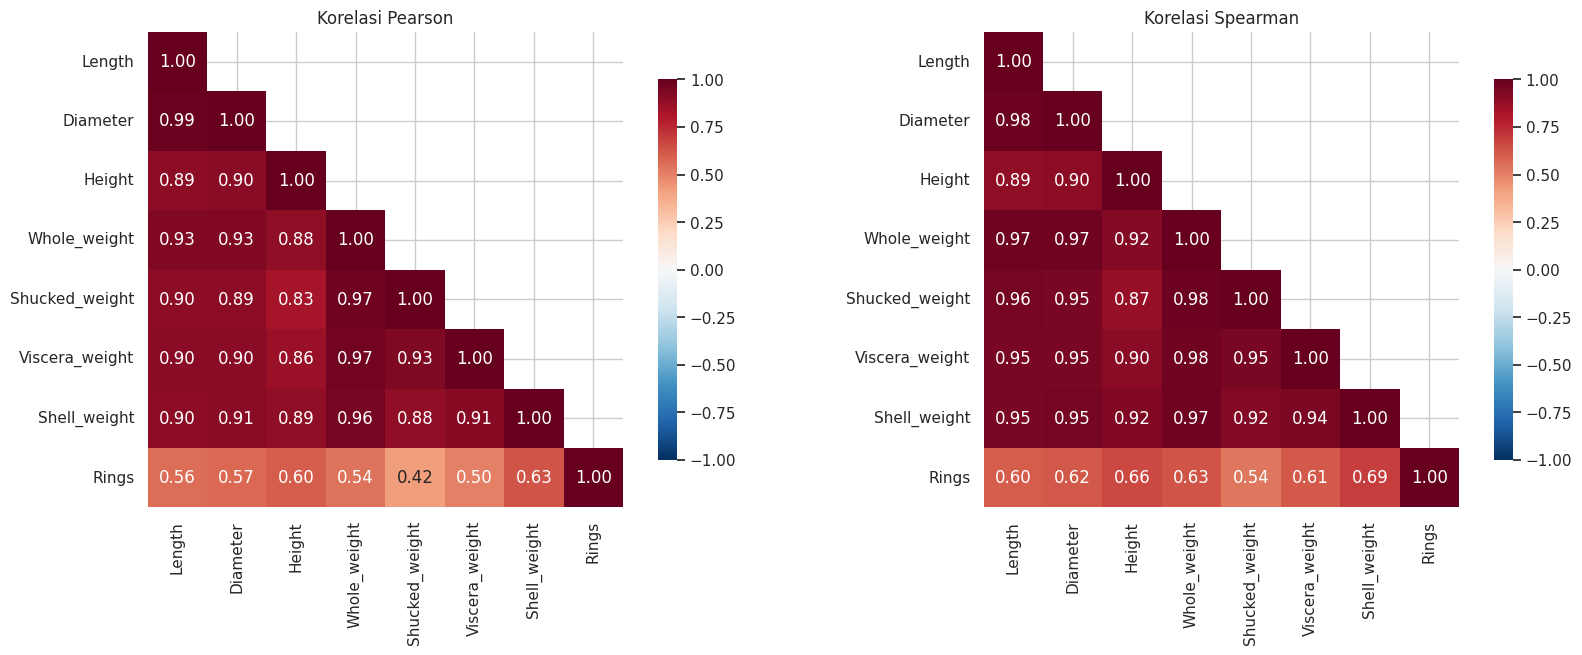

,Feature,VIF
0,Length,40.8
1,Diameter,42.3
2,Height,6.3
3,Whole_weight,111.2
4,Shucked_weight,28.7
5,Viscera_weight,17.5
6,Shell_weight,22.2


In [ ]:
# eda_corr
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
for ax, method in zip(axes, ["pearson", "spearman"]):
    corr = df[num_features + ["Rings"]].corr(method=method)
    sns.heatmap(
        corr,
        annot=True,
        fmt=".2f",
        cmap="RdBu_r",
        vmin=-1,
        vmax=1,
        ax=ax,
        mask=np.triu(np.ones_like(corr, dtype=bool), k=1),
        square=True,
        cbar_kws={"shrink": 0.8},
    )
    ax.set_title(f"Korelasi {method.capitalize()}")
plt.tight_layout()
plt.show()

# Multikolinearitas: Variance Inflation Factor (VIF_j = 1 / (1 - R2_j))
Xv = df[num_features].values
vif = []
for j, col in enumerate(num_features):
    others = np.delete(Xv, j, axis=1)
    r2 = LinearRegression().fit(others, Xv[:, j]).score(others, Xv[:, j])
    vif.append([col, 1 / (1 - r2)])

display(pd.DataFrame(vif, columns=["Feature", "VIF"]).round(1))

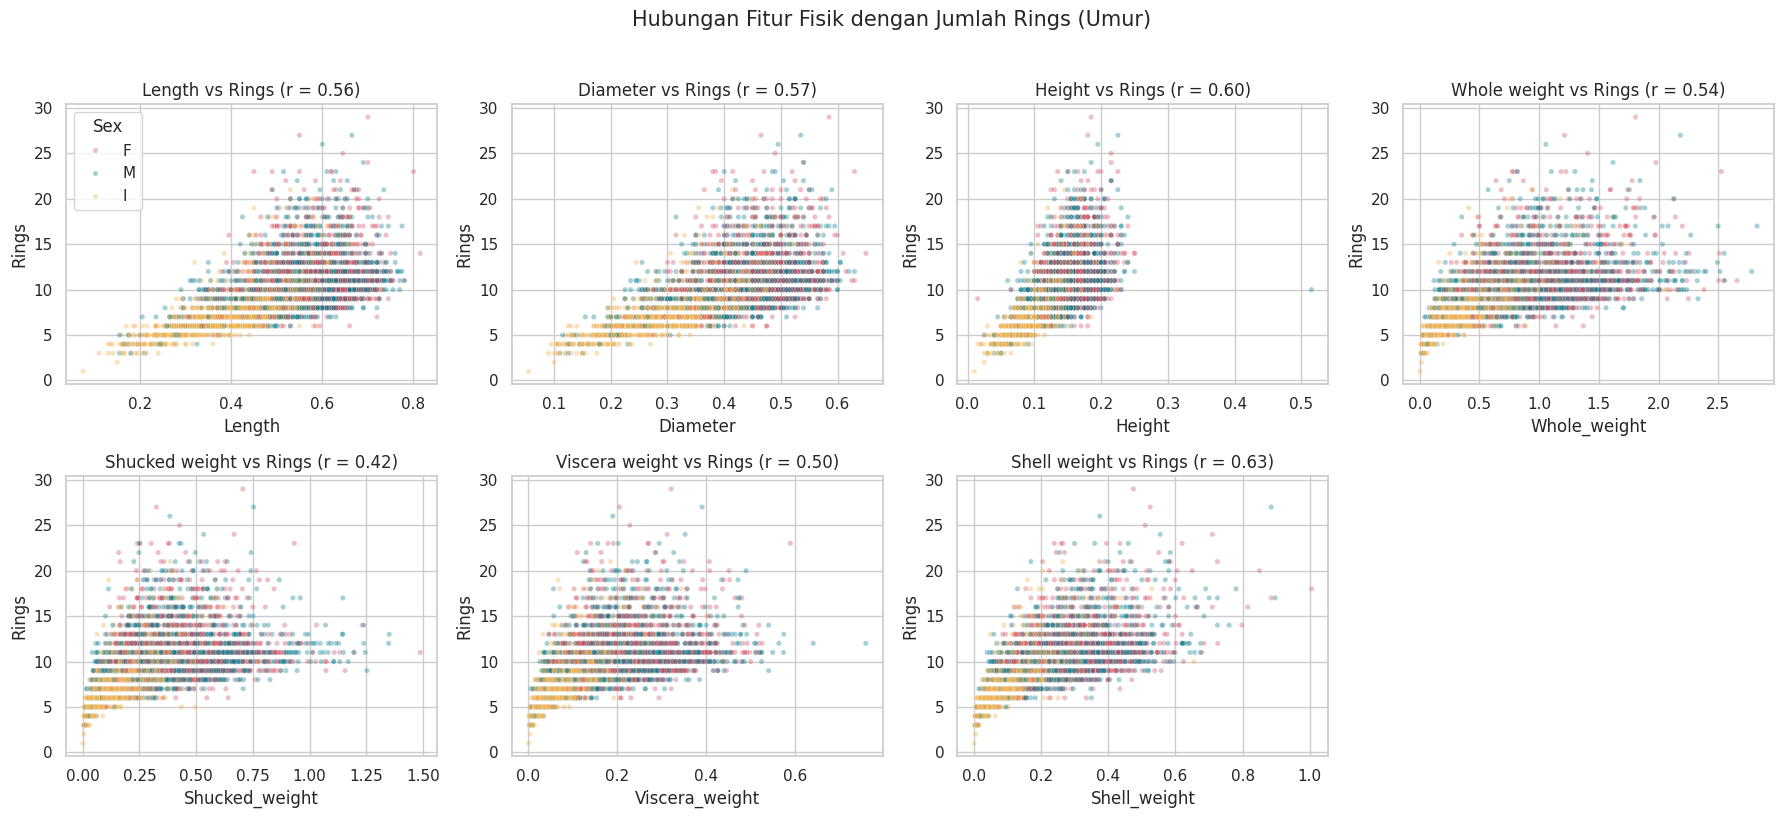

In [ ]:
# eda_scatter_rings
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), num_features):
    sns.scatterplot(
        data=df,
        x=col,
        y="Rings",
        hue="Sex",
        palette=SEX_COLORS,
        alpha=0.35,
        s=14,
        ax=ax,
        hue_order=["F", "M", "I"],
        legend=(col == "Length"),
    )
    corr_val = df[col].corr(df["Rings"])
    ax.set_title(f"{col.replace('_', ' ')} vs Rings (r = {corr_val:.2f})")

# Mematikan axis pada subplot terakhir karena jumlah fitur (7) kurang dari grid (8)
axes.ravel()[-1].axis("off")

plt.suptitle("Hubungan Fitur Fisik dengan Jumlah Rings (Umur)", y=1.02, fontsize=15)
plt.tight_layout()
plt.show()

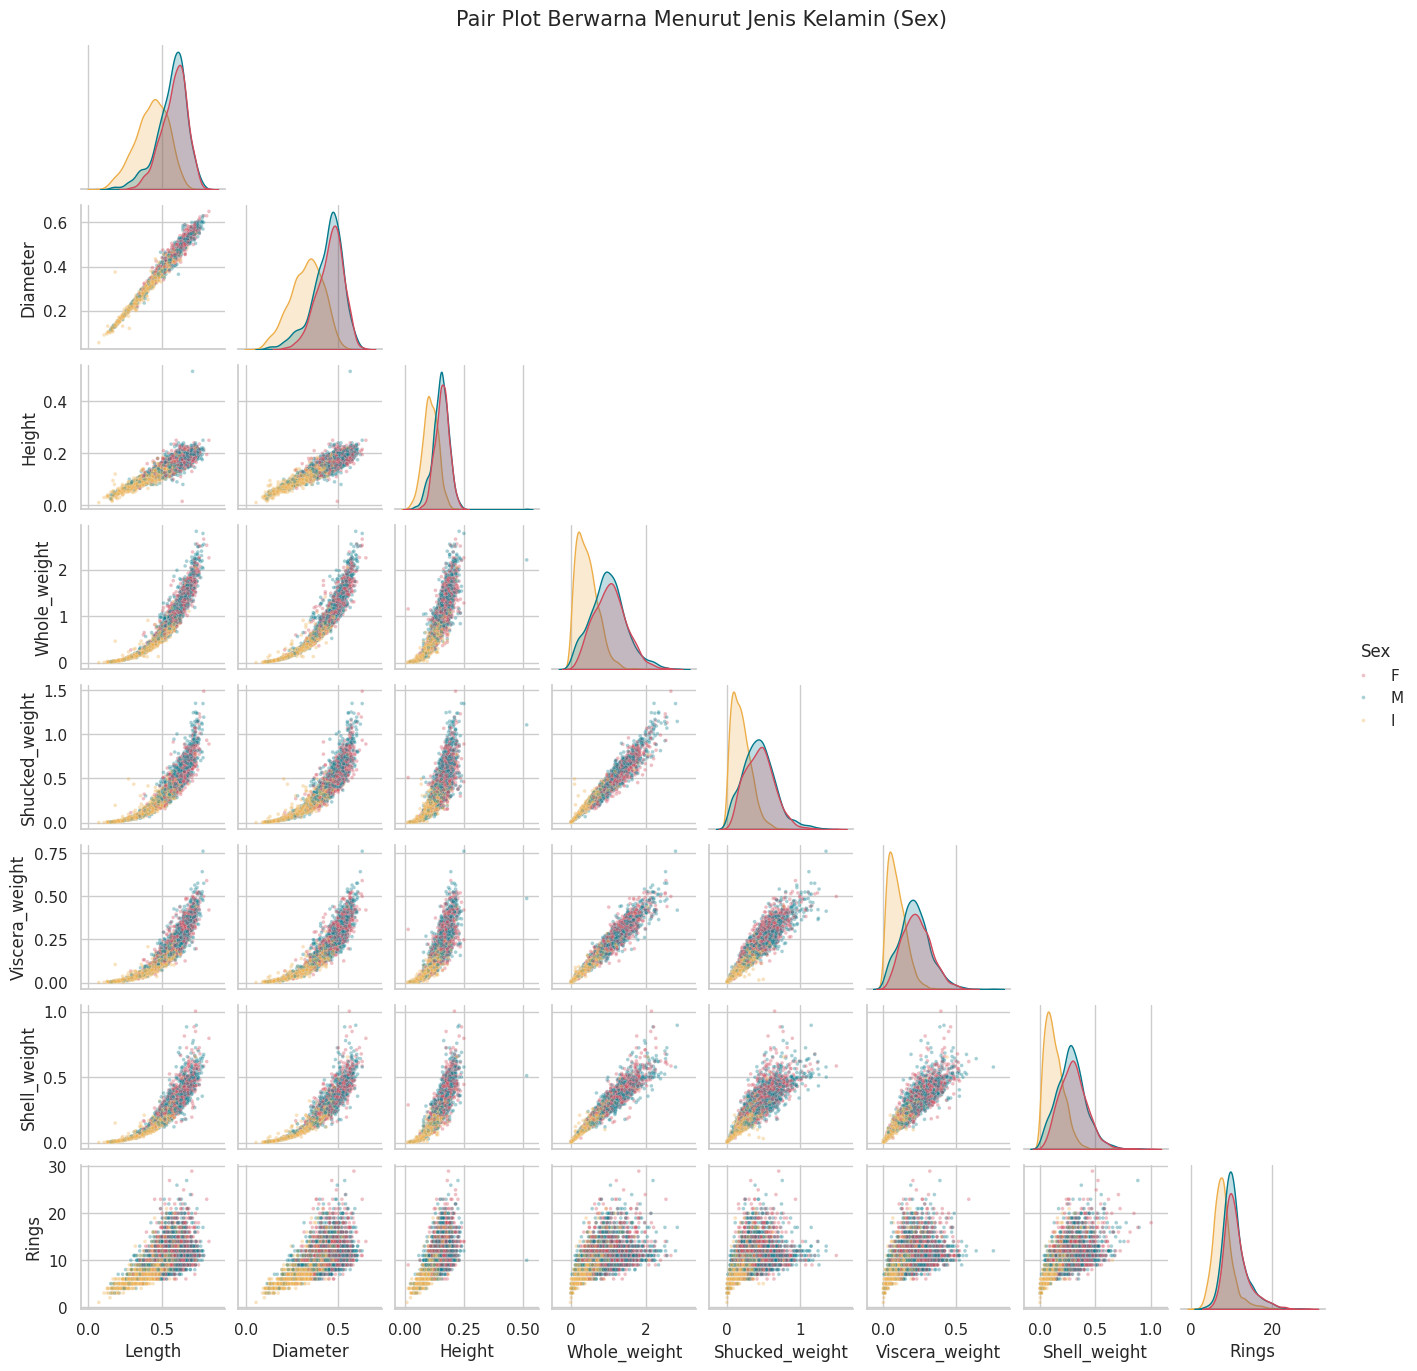

In [ ]:
# eda_pairplot
g = sns.pairplot(
    df[num_features + ["Rings", "Sex"]],
    hue="Sex",
    palette=SEX_COLORS,
    hue_order=["F", "M", "I"],
    corner=True,
    plot_kws=dict(s=7, alpha=0.35),
    diag_kind="kde",
    height=1.7,
)
g.fig.suptitle("Pair Plot Berwarna Menurut Jenis Kelamin (Sex)", y=1.01, fontsize=15)
plt.show()

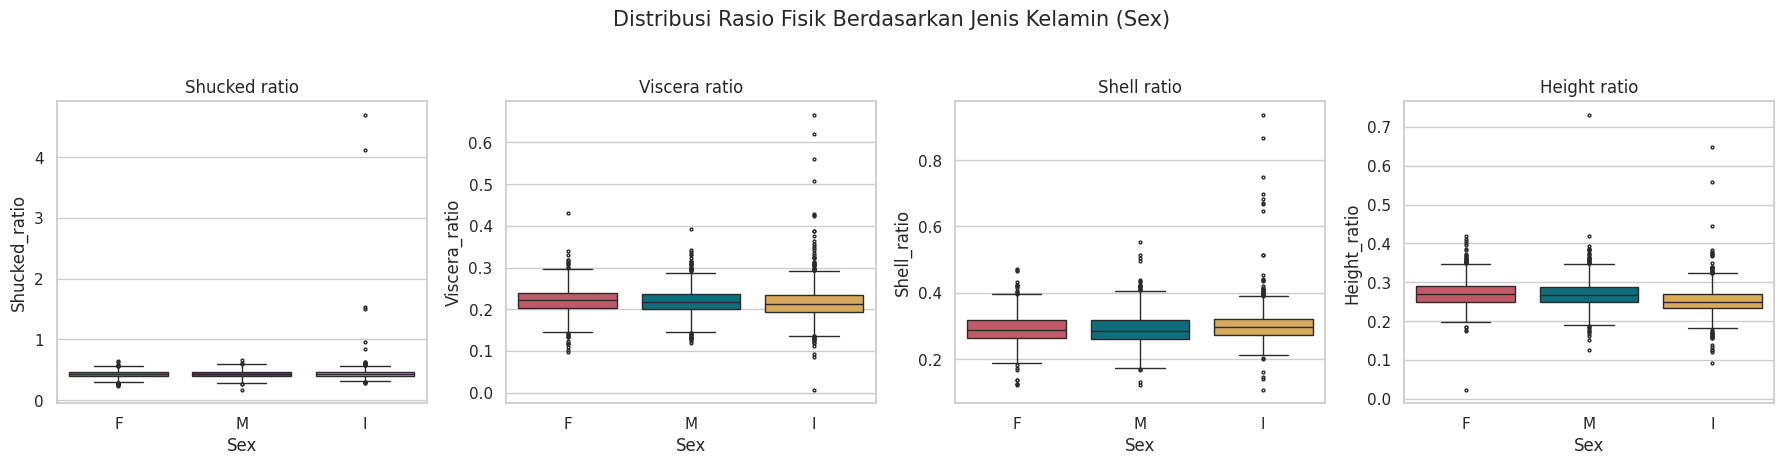

Rata-rata rasio fisik per jenis kelamin:


,Shucked_ratio,Viscera_ratio,Shell_ratio,Height_ratio
Sex,,,,
F,0.4232,0.2214,0.2925,0.2715
I,0.4432,0.2158,0.3017,0.2518
M,0.4307,0.2185,0.2915,0.2691


In [ ]:
# eda_ratios
# Rasio "bentuk / komposisi" buatan (hanya untuk EDA): apakah memisahkan Sex lebih baik daripada ukuran mentah?
eda = df.copy()
eda["Shucked_ratio"] = eda["Shucked_weight"] / eda["Whole_weight"]
eda["Viscera_ratio"] = eda["Viscera_weight"] / eda["Whole_weight"]
eda["Shell_ratio"] = eda["Shell_weight"] / eda["Whole_weight"]
eda["Height_ratio"] = eda["Height"] / eda["Length"]

ratio_cols = ["Shucked_ratio", "Viscera_ratio", "Shell_ratio", "Height_ratio"]

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, col in zip(axes, ratio_cols):
    sns.boxplot(
        data=eda,
        x="Sex",
        y=col,
        order=["F", "M", "I"],
        palette=SEX_COLORS,
        ax=ax,
        fliersize=2,
    )
    ax.set_title(col.replace("_", " "))

plt.suptitle("Distribusi Rasio Fisik Berdasarkan Jenis Kelamin (Sex)", y=1.03, fontsize=15)
plt.tight_layout()
plt.show()

print("Rata-rata rasio fisik per jenis kelamin:")
display(eda.groupby("Sex")[ratio_cols].mean().round(4))

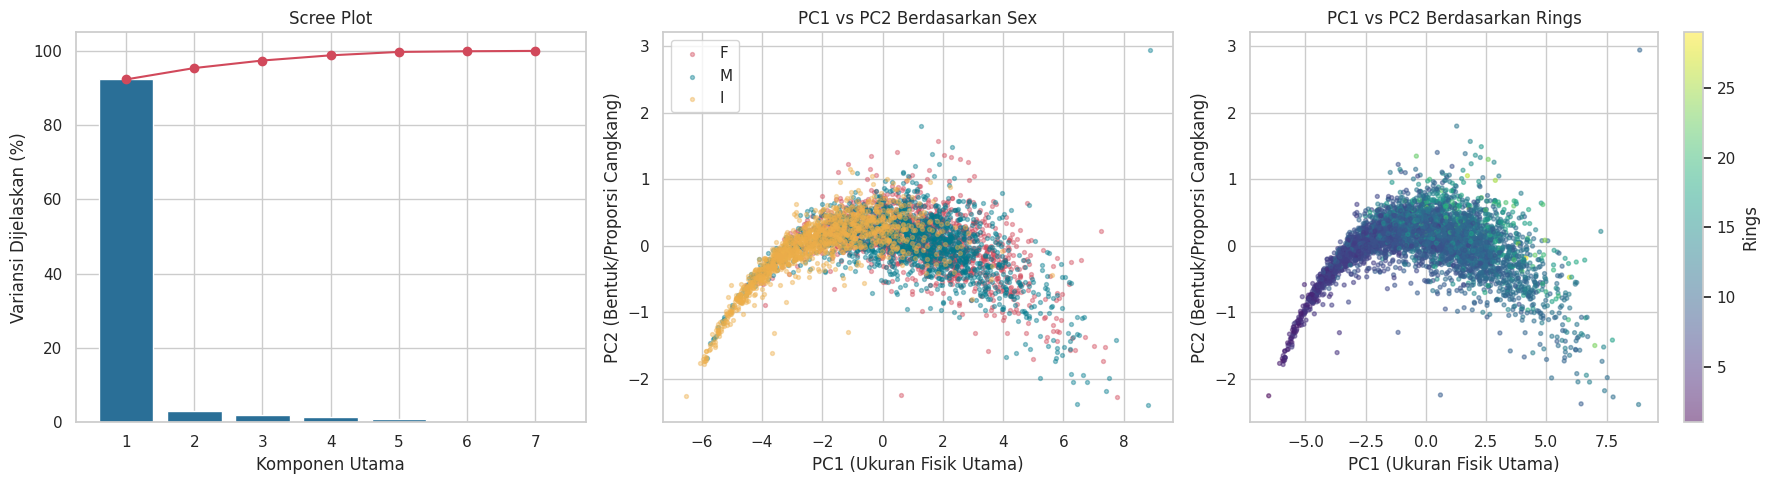

--- KESIMPULAN PCA ---
• Komponen 1 (PC1) merangkum sekitar 92.3% dari total informasi seluruh ukuran fisik (panjang, berat, tinggi, dll.).
• Jika digabung dengan Komponen 2 (PC2), keduanya mewakili 95.4% informasi data secara keseluruhan.
• Artinya, 7 kolom ukuran fisik yang banyak itu sebenarnya bisa diringkas dengan sangat baik menjadi hanya 2 sumbu utama (PC1 & PC2) tanpa kehilangan banyak informasi.


In [ ]:
# eda_pca
# Pratinjau PCA: melihat ringkasan ukuran fisik abalone ke dalam 2 dimensi utama
Xs = StandardScaler().fit_transform(df[num_features])
pca_eda = PCA().fit(Xs)
Z = pca_eda.transform(Xs)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Scree Plot
axes[0].bar(
    range(1, 8), pca_eda.explained_variance_ratio_ * 100, color="#2a6f97"
)
axes[0].plot(
    range(1, 8),
    np.cumsum(pca_eda.explained_variance_ratio_) * 100,
    "o-",
    color="#d1495b",
)
axes[0].set_xlabel("Komponen Utama")
axes[0].set_ylabel("Variansi Dijelaskan (%)")
axes[0].set_title("Scree Plot")

# 2. Scatter Plot PC1 vs PC2 (Berdasarkan Sex)
for s in ["F", "M", "I"]:
    m = df["Sex"] == s
    axes[1].scatter(Z[m, 0], Z[m, 1], s=8, alpha=0.4, c=SEX_COLORS[s], label=s)
axes[1].set_xlabel("PC1 (Ukuran Fisik Utama)")
axes[1].set_ylabel("PC2 (Bentuk/Proporsi Cangkang)")
axes[1].set_title("PC1 vs PC2 Berdasarkan Sex")
axes[1].legend()

# 3. Scatter Plot PC1 vs PC2 (Berdasarkan Rings)
sc = axes[2].scatter(
    Z[:, 0], Z[:, 1], s=8, alpha=0.5, c=df["Rings"], cmap="viridis"
)
plt.colorbar(sc, ax=axes[2], label="Rings")
axes[2].set_xlabel("PC1 (Ukuran Fisik Utama)")
axes[2].set_ylabel("PC2 (Bentuk/Proporsi Cangkang)")
axes[2].set_title("PC1 vs PC2 Berdasarkan Rings")

plt.tight_layout()
plt.show()

# Penjelasan output teks yang lebih manusiawi:
print("--- KESIMPULAN PCA ---")
print(
    f"• Komponen 1 (PC1) merangkum sekitar {pca_eda.explained_variance_ratio_[0]*100:.1f}% dari total informasi seluruh ukuran fisik (panjang, berat, tinggi, dll.)."
)
print(
    f"• Jika digabung dengan Komponen 2 (PC2), keduanya mewakili {sum(pca_eda.explained_variance_ratio_[:2])*100:.1f}% informasi data secara keseluruhan."
)
print(
    "• Artinya, 7 kolom ukuran fisik yang banyak itu sebenarnya bisa diringkas dengan sangat baik menjadi hanya 2 sumbu utama (PC1 & PC2) tanpa kehilangan banyak informasi."
)

### **Ringkasan EDA: Temuan Utama dan Implikasi Pemodelan**

#### **A. Distribusi Variabel**
* **Variabel Panjang:** Agak miring ke kiri (*skew* sekitar -0,6).
* **Variabel Berat:** Miring ke kanan (*skew* +0,5 hingga +0,7).
* **Variabel Tinggi (`Height`):** Hampir simetris karena nilai dari *skew* mendekati 0) setelah pembersihan data.
  > *Catatan:* Hal ini dikarenakan oleh tidak adanya variabel yang memiliki tingkat kemiringan ekstrem sehingga transformasi data tidak wajib dilakukan. Jika dibutuhkan, *Standard Scaling* sudah cukup memadai.
* **Jumlah Cincin (`Rings`):** Miring ke kanan (*skew* 1,1; rentang 1–29; modus 9) dengan ekor panjang yang merepresentasikan abalone tua. Terdapat 278 baris (6,7%) yang terdeteksi sebagai *outlier* IQR dengan kelas di atas 20 cincin masing-masing berisi kurang dari 30 abalone.

#### **B. Keseimbangan Target (`Sex`)**
* **Proporsi Kelas:** Jantan (M) 36,6%, Infant (I) 32,1%, dan Betina (F) 31,3% (hampir seimbang).
* **Implikasi:** *Baseline* akurasi model jika selalu menebak kelas mayoritas ("M") adalah 36,6%. Dimana hal ini dapat dijadikan sebagai acuan (*benchmark*) yang harus dilampaui oleh model.
* **Validasi:** *Train-test split* secara (*stratified split*) agar proporsi ini tetap terjaga di setiap subset data.

#### **C. Perbedaan Antar Jenis Kelamin**
* **Infant dan Dewasa:** Infant berukuran jauh lebih kecil dan muda (rata-rata berat total 0,43 sedangkan untuk betina bernilai, dan 0,99 untuk jantan. untuk rata-rata *rings* berada di 7,9 dengan 11,1 untuk betina dan 10,7 untuk jantan. Dimana untuk ukuran *effect size* cukup signifikan (Cohen’s *d* $\approx$ 1,4–1,5).
* **Betina vs Jantan:** Ukurannya hampir identik. Betina hanya sedikit lebih besar (Cohen’s *d* antara 0,06 dan 0,20 dengan nilai *p* yang kecil pada uji Mann-Whitney karena ukuran sampel yang besar). Distribusinya juga hampir sepenuhnya saling tumpang tindih pada plot KDE dan *violin plot*.
* **Rasio Tubuh:** Rasio komposisi tubuh (`shucked/whole`, `viscera/whole`, `shell/whole`, dan `height/length`) hampir tidak menunjukkan perbedaan antar jenis kelamin sehingga fitur turunan (*engineered features*) sederhana tidak cukup untuk memisahkan M dan F.
* **Struktur Umur:** Sebanyak 68,7% infant berada di kelompok *Young* dan hanya 11,6% di kelompok *Old*. Sebaliknya, 48,6% betina dan 43,0% jantan berada di kelompok *Old*.

#### **D. Hubungan Antar Variabel**
* **Korelasi Tinggi:** Ketujuh ukuran fisik saling berkorelasi dengan nilai yang sangat kuat ($r$ berpasangan mempunyai rentang antara 0,84 dan 0,99 dengan median 0,90) dengan nilai VIF yang sangat tinggi (`Whole weight` 111, `Diameter` 42, `Length` 41, `Shucked` 29, `Shell` 22, `Viscera` 17,5, `Height` 6,3). Dimana artinya semua variabel ini cukup penting atau dibutuhkan dalam mengukur **ukuran tubuh keseluruhan**.
* **Analisis PCA:** Analisis ini menunjukan bahwa abalone-abalone ini pada dasarnya hanya bervariasi dalam ukuran tubuh secara keseluruhan (dijelaskan oleh PC1 dengan nilai sebesar 92,3%), sementara bentuk proporsinya relatif seragam (PC2 hanya 3,1%)."
* **Hubungan dengan `Rings`:** Korelasinya sedang (`Shell weight` tertinggi $\approx$ 0,63, lalu `Height` 0,60, `Diameter` 0,57, dan `Shucked weight` terendah $\approx$ 0,42). Scatter plot ini membantuk pola yang **melengkung** (abalone berukuran besar berhenti bertumbuh meskipun jumlah cincinnya terus bertambah) serta berbentuk **corong** (sebaran varians membesar seiring ukuran, menunjukkan adanya heteroskedastisitas).

#### **E. Konsekuensi dan Implikasi untuk Pemodelan**
1. **Prediksi Jenis Kelamin (`Sex`):** Sinyal pembeda antara Jantan dan Betina sangat kecil sehingga batas atas performa prediksinya rendah. Sementara, jika digunakan untuk memprediksi kategori *infant* ataupun *old*, hasilnya dapat lebih baik dari itu.
2. **Model Regresi:** Model linear akan dibatasi karena adanya kelengkungan data dan varians yang membesar (*heteroskedastisitas*). Selain itu, multikolinearitas tinggi membuat koefisien variabel individual menjadi tidak stabil (meskipun prediksi secara keseluruhan tetap akurat).
3. **Clustering:** Mengingat sebaran data di ruang PCA padat dan hanya dikendalikan oleh satu sumbu ukuran, hasil cluster nantinya kemungkinan besar hanya berupa potongan dari rentang ukuran yang kontinu (menyatu), bukan kelompok-kelompok yang terpisah secara tegas.
4. **Penskalaan Data (*Scaling*):** Langkah scaling perlu dilakukan pada algoritma berbasis jarak (seperti SVM, K-Means, Spectral, dan Hierarchical Clustering). Namun, karena proses ini tidak memberikan dampak negatif pada Random Forest maupun Regresi Linear, maka standarisasi ini dapat menggunakan satu pipeline preprocessing yang sama untuk seluruh model.

## **3. Klasifikasi**

### **a. Klasifikasi: Memprediksi Jenis Kelamin (`Sex`) Abalone**

* **Prediktor:** Menggunakan 7 ukuran fisik utama. Dimana kolom `Rings` sengaja tidak dimasukkan dalam eksperimen karena menghitung cincin memerlukan bantuan mikroskop (tidak praktis untuk identifikasi cepat).Namun, untuk analisis sensitivitas, fitur ini akan disertakan di bagian akhir untuk melihat dampaknya jika `Rings` ikut ditambahkan.
* **Penanganan Variabel Kategorikal:** Target prediksi (`Sex`) diubah menggunakan *Label Encoding* (`F = 0`, `I = 1`, `M = 2`) sementara seluruh prediktor bersifat numerik.
* **Pembagian Data (*Split*):** Menggunakan rasio 80% data latih (*train*) dan 20% data uji (*test*) dengan metode *stratified split* berdasarkan kolom `Sex` (`random_state = 42`) untuk menjaga proporsi kelas tetap seimbang.
* **Penskalaan Data (*Scaling*):** Menggunakan `StandardScaler` ($z = \frac{x - \text{mean}}{\text{std}}$) yang dimasukan di dalam `Pipeline` scikit-learn. Langkah ini digunakan agar parameter rata-rata dan simpangan baku hanya dipelajari dari data latih (mencegah *data leakage*, termasuk selama proses *cross-validation*).
* **Hyperparameter Tuning:** Menggunakan `GridSearchCV` dengan 5-fold *stratified cross-validation* yang hanya dijalankan pada data latih sednagkan data uji disimpan dan hanya digunakan sekali untuk evaluasi akhir.

#### **Metrik Evaluasi (Klasifikasi 3 Kelas menggunakan Macro Average)**
* **Akurasi (*Accuracy*):** Rasio total prediksi yang benar terhadap keseluruhan prediksi.
* **Presisi (*Precision*):** $TP_c / (TP_c + FP_c)$ untuk setiap kelas $c$. Dimana ini digunakan untuk menjawab pertanyaan: *"Ketika model memprediksi kelas $c$, seberapa sering prediksi tersebut benar?"*
* **Recall:** $TP_c / (TP_c + FN_c)$ untuk setiap kelas $c$ yang berfungsi untuk menjawab pertanyaan: *"Dari seluruh total kelas $c$ yang sebenarnya ada di data, berapa persentase yang berhasil ditemukan oleh model?"*
* **Macro Average:** Rata-rata sederhana dari metrik di atas lintas ketiga kelas sehingga setiap kelas memiliki bobot yang sama. **Macro-F1** (rata-rata harmonik antara presisi dan *recall*) digunakan sebagai indikator utama keseimbangan performa model secara keseluruhan.

In [ ]:
# --- Target dan prediktor -------------------------------------------------------------
# Prediktor : 7 ukuran fisik (semuanya numerik).
# Target     : Sex (kategorikal: F, I, M) -> satu-satunya variabel kategorikal, jadi di-label-encode.
feat_cls = num_features
le = LabelEncoder()
y_cls = le.fit_transform(df["Sex"])
class_names = list(le.classes_)
print("Label encoding:", dict(zip(class_names, le.transform(class_names))))

X_cls = df[feat_cls]
X_train, X_test, y_train, y_test = train_test_split(
    X_cls, y_cls, test_size=0.2, stratify=y_cls, random_state=RANDOM_STATE)
print("Latih:", X_train.shape, " Uji:", X_test.shape)
print("Proporsi kelas data latih:", np.round(np.bincount(y_train) / len(y_train), 3),
      "| Proporsi kelas data uji:", np.round(np.bincount(y_test) / len(y_test), 3))

Label encoding: {'F': np.int64(0), 'I': np.int64(1), 'M': np.int64(2)}
Latih: (3339, 7)  Uji: (835, 7)
Proporsi kelas data latih: [0.313 0.321 0.366] | Proporsi kelas data uji: [0.313 0.321 0.366]


**Baseline**
Dummy majority-class menetapkan batas bawah (akurasi sekitar 36,7%). SVM default (RBF, C=1) dan RF default dilatih lebih dulu untuk melihat seberapa besar pengaruh tuning.

In [ ]:
# Pipeline: scaler hanya dilatih pada fold latih -> tanpa data leakage.
svm_pipe = Pipeline([("scaler", StandardScaler()), ("clf", SVC(random_state=RANDOM_STATE))])
rf_pipe  = Pipeline([("scaler", StandardScaler()),
                     ("clf", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))])

def evaluate(model, Xtr, ytr, Xte, yte):
    """Mengembalikan dict metrik uji (rata-rata makro = setiap kelas berbobot sama)."""
    pred = model.predict(Xte)
    return {"Accuracy": accuracy_score(yte, pred),
            "Precision (macro)": precision_score(yte, pred, average="macro", zero_division=0),
            "Recall (macro)": recall_score(yte, pred, average="macro", zero_division=0),
            "F1 (macro)": f1_score(yte, pred, average="macro", zero_division=0),
            "Train accuracy": accuracy_score(ytr, model.predict(Xtr))}

# Acuan: classifier yang selalu memprediksi kelas terbanyak
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
res_base = {"Majority-class baseline": evaluate(dummy, X_train, y_train, X_test, y_test)}

# Hyper-parameter default dulu
svm_pipe.fit(X_train, y_train); rf_pipe.fit(X_train, y_train)
res_base["SVM (default)"] = evaluate(svm_pipe, X_train, y_train, X_test, y_test)
res_base["RF (default)"]  = evaluate(rf_pipe,  X_train, y_train, X_test, y_test)
display(pd.DataFrame(res_base).T.round(4))

,Accuracy,Precision (macro),Recall (macro),F1 (macro),Train accuracy
Majority-class baseline,0.3665,0.1222,0.3333,0.1788,0.3660
SVM (default),0.5617,0.5834,0.5544,0.5177,0.5577
RF (default),0.5593,0.5507,0.5625,0.5549,1.0000


In [ ]:
# Tuning hyper-parameter dengan 5-fold stratified CV hanya pada data LATIH
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

svm_grid = [
    {"clf__kernel": ["rbf"], "clf__C": [0.1, 1, 10, 100], "clf__gamma": ["scale", 0.01, 0.1, 1]},
    {"clf__kernel": ["linear"], "clf__C": [0.1, 1, 10]},
    {"clf__kernel": ["poly"], "clf__degree": [2, 3], "clf__C": [0.1, 1, 10]},
]
rf_grid = {"clf__n_estimators": [200, 500], "clf__max_depth": [None, 5, 10],
           "clf__min_samples_leaf": [1, 5, 10], "clf__max_features": ["sqrt", 0.5]}

t0 = time.time()
gs_svm = GridSearchCV(svm_pipe, svm_grid, cv=cv5, scoring="accuracy", n_jobs=-1).fit(X_train, y_train)
t_svm = time.time() - t0
t0 = time.time()
gs_rf = GridSearchCV(rf_pipe, rf_grid, cv=cv5, scoring="accuracy", n_jobs=-1).fit(X_train, y_train)
t_rf = time.time() - t0

print(f"SVM parameter terbaik: {gs_svm.best_params_}\n  accuracy CV = {gs_svm.best_score_:.4f}  (grid search {t_svm:.0f} dtk)")
print(f"RF  parameter terbaik: {gs_rf.best_params_}\n  accuracy CV = {gs_rf.best_score_:.4f}  (grid search {t_rf:.0f} dtk)")
best_svm, best_rf = gs_svm.best_estimator_, gs_rf.best_estimator_

SVM parameter terbaik: {'clf__C': 100, 'clf__gamma': 0.01, 'clf__kernel': 'rbf'}
  accuracy CV = 0.5517  (grid search 70 dtk)
RF  parameter terbaik: {'clf__max_depth': 10, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 5, 'clf__n_estimators': 200}
  accuracy CV = 0.5541  (grid search 365 dtk)


In [ ]:
# Evaluasi akhir pada data uji untuk model yang sudah di-tuning
res_cls = {"Majority-class baseline": res_base["Majority-class baseline"],
           "SVM (tuned)": evaluate(best_svm, X_train, y_train, X_test, y_test),
           "RF (tuned)":  evaluate(best_rf,  X_train, y_train, X_test, y_test)}
cls_table = pd.DataFrame(res_cls).T
display(cls_table.round(4))

pred_svm, pred_rf = best_svm.predict(X_test), best_rf.predict(X_test)
for name, pred in [("SVM", pred_svm), ("Random Forest", pred_rf)]:
    print(f"\n===== {name}: laporan per kelas =====")
    print(classification_report(y_test, pred, target_names=class_names, digits=3, zero_division=0))

,Accuracy,Precision (macro),Recall (macro),F1 (macro),Train accuracy
Majority-class baseline,0.3665,0.1222,0.3333,0.1788,0.3660
SVM (tuned),0.5653,0.5898,0.5572,0.5153,0.5600
RF (tuned),0.5617,0.5517,0.5627,0.5500,0.7862



===== SVM: laporan per kelas =====
              precision    recall  f1-score   support

           F      0.641     0.157     0.252       261
           I      0.640     0.854     0.732       268
           M      0.489     0.660     0.562       306

    accuracy                          0.565       835
   macro avg      0.590     0.557     0.515       835
weighted avg      0.585     0.565     0.520       835


===== Random Forest: laporan per kelas =====
              precision    recall  f1-score   support

           F      0.505     0.360     0.421       261
           I      0.658     0.825     0.732       268
           M      0.492     0.503     0.498       306

    accuracy                          0.562       835
   macro avg      0.552     0.563     0.550       835
weighted avg      0.549     0.562     0.549       835



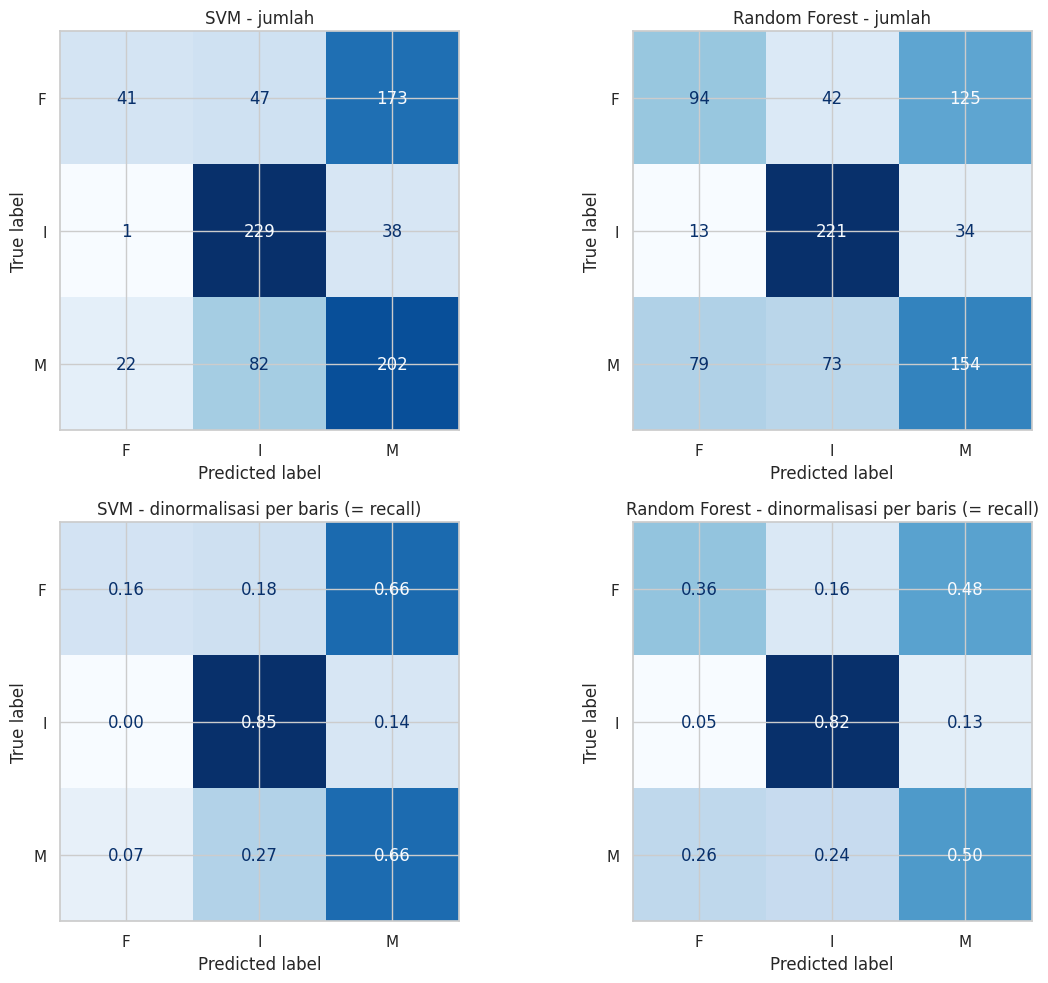

In [ ]:
# cls_confusion
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for j, (name, pred) in enumerate([("SVM", pred_svm), ("Random Forest", pred_rf)]):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=class_names, cmap="Blues",
                                            ax=axes[0, j], colorbar=False)
    axes[0, j].set_title(f"{name} - jumlah")
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=class_names, cmap="Blues",
                                            normalize="true", values_format=".2f", ax=axes[1, j], colorbar=False)
    axes[1, j].set_title(f"{name} - dinormalisasi per baris (= recall)")
plt.tight_layout(); plt.show()

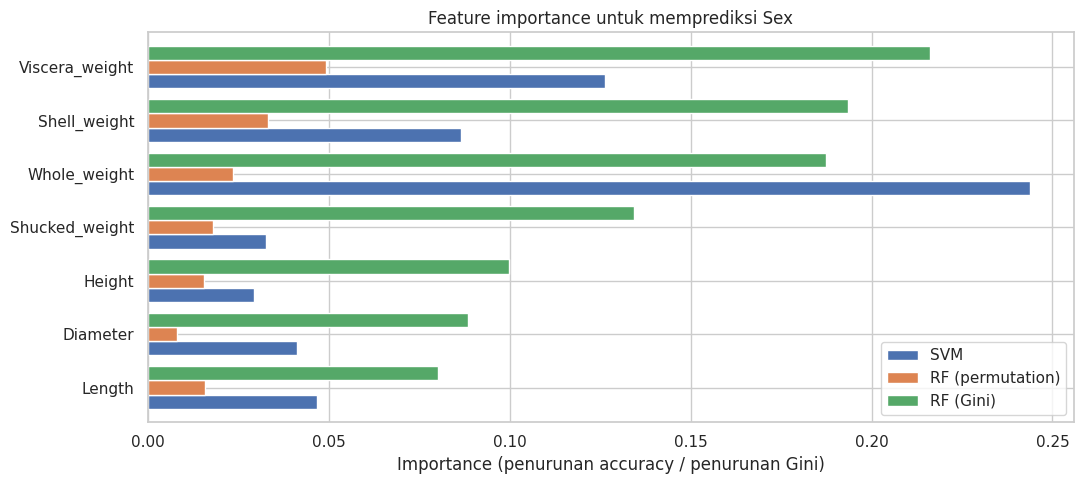

,SVM,RF (permutation),RF (Gini)
Length,0.0468,0.0157,0.0802
Diameter,0.0414,0.0082,0.0885
Height,0.0294,0.0156,0.0998
Whole_weight,0.2438,0.0236,0.1875
Shucked_weight,0.0327,0.0180,0.1343
Viscera_weight,0.1263,0.0494,0.2162
Shell_weight,0.0865,0.0332,0.1934


In [ ]:
# cls_importance
# Fitur Utama yang Diandalkan Tiap Model
# (Berdasarkan Permutation Importance pada data uji dengan 15 kali pengulangan)
pi_svm = permutation_importance(best_svm, X_test, y_test, n_repeats=15, random_state=RANDOM_STATE, n_jobs=-1)
pi_rf  = permutation_importance(best_rf,  X_test, y_test, n_repeats=15, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.DataFrame({"SVM": pi_svm.importances_mean, "RF (permutation)": pi_rf.importances_mean,
                    "RF (Gini)": best_rf.named_steps["clf"].feature_importances_}, index=feat_cls)
fig, ax = plt.subplots(figsize=(11, 5))
imp.sort_values("RF (Gini)").plot.barh(ax=ax, width=0.8)
ax.set_xlabel("Importance (penurunan accuracy / penurunan Gini)"); ax.set_title("Feature importance untuk memprediksi Sex")
plt.tight_layout(); plt.show()
display(imp.round(4))

SVM (tuned): accuracy = 0.5577 +/- 0.0211
RF (tuned): accuracy = 0.5515 +/- 0.0173
Uji-t berpasangan pada 10 fold: t = 0.98, p = 0.351


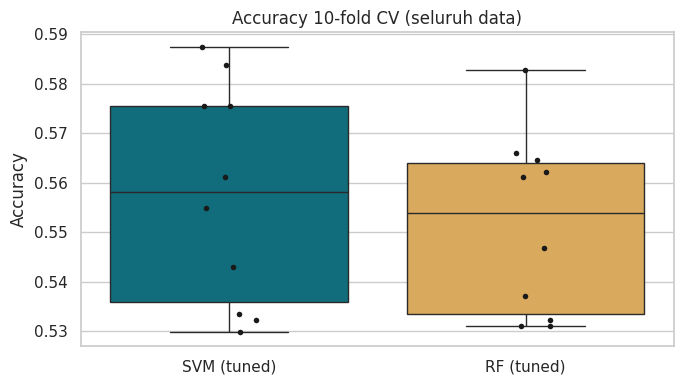

In [ ]:
# Uji Kekokohan Model: 10-Fold Stratified CV pada Seluruh Data
# menggunakan konfigurasi hyperparameter terbaik hasil tuning
cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
cv_rows = {}
for name, mdl in [("SVM (tuned)", best_svm), ("RF (tuned)", best_rf)]:
    sc = cross_val_score(mdl, X_cls, y_cls, cv=cv10, scoring="accuracy", n_jobs=-1)
    cv_rows[name] = sc
    print(f"{name}: accuracy = {sc.mean():.4f} +/- {sc.std():.4f}")
t_stat, p_val = stats.ttest_rel(cv_rows["SVM (tuned)"], cv_rows["RF (tuned)"])
print(f"Uji-t berpasangan pada 10 fold: t = {t_stat:.2f}, p = {p_val:.3f}")
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=pd.DataFrame(cv_rows), palette=["#00798c", "#edae49"], ax=ax); sns.stripplot(data=pd.DataFrame(cv_rows), color="k", size=4, ax=ax)
ax.set_ylabel("Accuracy"); ax.set_title("Accuracy 10-fold CV (seluruh data)")
plt.tight_layout(); plt.show()

In [ ]:
# Analisis sensitivitas: (a) tambah Rings sebagai prediktor, (b) gabung M+F menjadi "Adult" (Infant vs Adult),
# (c) hanya dewasa: Male vs Female.  Hyper-parameter hasil tuning dan logika split yang sama.
def quick_eval(Xdf, ydf, label):
    Xtr, Xte, ytr, yte = train_test_split(Xdf, ydf, test_size=0.2, stratify=ydf, random_state=RANDOM_STATE)
    out = {}
    for name, mdl in [("SVM", best_svm), ("RF", best_rf)]:
        from sklearn.base import clone
        m = clone(mdl).fit(Xtr, ytr); p = m.predict(Xte)
        out[(label, name)] = {"Accuracy": accuracy_score(yte, p),
                              "Precision (macro)": precision_score(yte, p, average="macro", zero_division=0),
                              "Recall (macro)": recall_score(yte, p, average="macro", zero_division=0)}
    return out
sens = {}
sens.update(quick_eval(df[feat_cls], df["Sex"], "3-class, 7 features (main)"))
sens.update(quick_eval(df[feat_cls + ["Rings"]], df["Sex"], "3-class, + Rings"))
sens.update(quick_eval(df[feat_cls], np.where(df["Sex"] == "I", "I", "Adult"), "Infant vs Adult"))
ad = df[df["Sex"] != "I"]
sens.update(quick_eval(ad[feat_cls], ad["Sex"], "Adults only: M vs F"))
sens_tbl = pd.DataFrame(sens).T
display(sens_tbl.round(4))

Accuracy  Precision (macro)  Recall (macro)
3-class, 7 features (main) SVM    0.5653             0.5898          0.5572
                           RF     0.5617             0.5517          0.5627
3-class, + Rings           SVM    0.5701             0.5780          0.5646
                           RF     0.5713             0.5608          0.5711
Infant vs Adult            SVM    0.8359             0.8128          0.8084
                           RF     0.8455             0.8226          0.8233
Adults only: M vs F        SVM    0.5626             0.5638          0.5370
                           RF     0.5608             0.5536          0.5447

#### **Penjelasan**

##### **1. Performa pada Data Uji**

| Model | MSE Uji | RMSE | MAE | $R^2$ |
| :--- | :---: | :---: | :---: | :---: |
| **Baseline (Rata-rata)** | 10,39 | 3,22 | — | 0,00 |
| **Simple Linear Regression (`Shell_weight`)** | 6,51 | 2,55 | 1,84 | 0,373 |
| **Polynomial (Derajat 2, `Shell_weight`)** | 6,34 | 2,52 | 1,82 | 0,389 |
| **Multiple Linear Regression (MLR)** | **5,26** | 2,29 | 1,63 | 0,493 |
| **MLR pada $\log(\text{Rings})$** | 5,53 | 2,35 | 1,64 | 0,467 |
| **Random Forest Regressor** | **4,71** | 2,17 | 1,51 | 0,547 |

##### **2. Performa Model Terbaik**
* **Multiple Linear Regression (MLR)** terlihat lebih unggul di antara model linear lainnya karena nilai MSE turun 19% menjadi 5,26 (dibandingkan 6,51 pada regresi sederhana) dengan $R^2$ meningkat dari 0,37 ke 0,49. MSE data uji dan MSE *cross-validation* data latih (4,68 vs 6,25) saling sejalan sehingga peningkatan ini bukan sekadar kebetulan. Hal ini karena kurva kuadratik hanya memberikan perbaikan yang sangat kecil pada regresi sederhana (6,34).
* **Random Forest** mencatatkan akurasi non-linear terbaik dengan MSE 4,71. Meskipun demikian, MSE latihnya mencapai 2,45 (menunjukkan selisih *overfitting* yang cukup besar) dan model ini tidak dapat direpresentasikan ke dalam bentuk persamaan matematis yang sederhana.

##### **3. Penjelasan Plot**
* **Scatter Plot & Fitted Line***
  Garis regresi linear sederhana (SLR) mampu merepresentasikan tren kenaikan secara keseluruhan. Namun, sebaran data menunjukkan pola yang melebar dan melengkung (*non-linear*): abalone berusia muda dengan berat cangkang di bawah $0,2$ gram memiliki akurasi estimasi yang sangat baik, sedangkan pada kelompok berbobot besar, garis estimasi cenderung terlalu tinggi bagi sebagian spesimen dan terlalu rendah bagi sebagian besar abalone tua.
* **Perbandingan Nilai Aktual dengan Prediksi:**
  Seluruh model regresi menunjukkan kecenderungan kompresi nilai estimasi ke dalam rentang aman antara 5 hingga 15 cincin. Spesimen dengan jumlah cincin $\ge 18$ secara konsisten diprediksi lebih rendah dari nilai sebenarnya (sebagai contoh, abalone berusia 20 cincin diestimasi hanya sekitar 13–15 cincin). Kondisi ini disebabkan oleh karakteristik biologis abalone di mana pertumbuhan ukuran fisik mengalami kejenuhan (*plateau*) setelah mencapai fase dewasa, sementara penambahan lapisan cangkang (*rings*) terus berlanjut. Keterbatasan informasi ini tidak dapat diatasi hanya melalui penambahan prediktor fisik yang tersedia.
* **Analisis Residual dan Evaluasi Variansi:**
  Grafik sebaran residual memperlihatkan pola berbentuk corong seiring dengan meningkatnya nilai prediksi (*fitted values*)  yang mengindikasikan adanya *heteroskedastisitas*. Selain itu, diagram Q-Q menunjukkan ekor kanan yang berat merepresentasikan kelompok abalone berusia lanjut. Meskipun pendekatan transformasi logaritmik pada variabel target berhasil menstabilkan variansi residual, metode tersebut **tidak** memberikan perbaikan nilai MSE pada skala data asli (5,53) karena nilai MSE secara keseluruhan didominasi oleh galat (*error*) dari sedikit spesimen tua yang hasil transformasi baliknya mengalami kompresi.

##### **4. Analisis Koefisien MLR (OLS pada Data Latih)**
* **Interpretasi Pengaruh Variabel Prediktor:**
  Berdasarkan estimasi parameter model, variabel `Height` (+21,6), `Diameter` (+9,4), `Whole weight` (+9,2), dan `Shell weight` (+8,1) menunjukkan hubungan positif terhadap jumlah `Rings`. Sebaliknya, `Shucked weight` (-20,5) dan `Viscera weight` (-11,0) tercatat memiliki koefisien negatif. Untuk variabel biner jenis kelamin, `Sex_I` bernilai -0,77 ($p < 1 \times 10^{-10}$ mengindikasikan bahwa kelompok *infant* memiliki jumlah cincin yang secara signifikan lebih sedikit dibandingkan betina pada ukuran fisik yang setara) sementara `Sex_M` ($p = 0,32$) dan `Length` ($p = 0,68$) tidak menunjukkan signifikansi statistik.
* **Dampak dan Gejala Multikolinearitas:**
  Munculnya tanda negatif pada koefisien `Shucked weight`meskipun korelasi bivariat terhadap `Rings` bernilai positif (+0,42) merupakan dampak dari **multikolinearitas** tinggi (dengan nilai VIF mencapai 111). Proporsi berat daging yang raltif lebih besar terhadap berat keseluruhan umumnya merepresentasikan karakteristik biologis abalone muda yang berada dalam fase pertumbuhan cepat. Oleh karena itu, koefisien ini wajib diinterpretasikan sebagai *"pengaruh suatu prediktor ketika variabel lainnya dikontrol (dianggap tetap)"* bukan sebagai efek independen meskipun tingkat akurasi prediksi secara keseluruhannya tetap stabil.

##### **5. Evaluasi Tingkat Ketepatan Prediksi**
Transformasi nilai estimasi kontinu menjadi bilangan bulat diskrit melalui pembulatan anya menghasilkan tingkat ketepatan pada kisaran **20% hingga 22%** spesimen (mengingat umur biologis abalone secara alami memiliki variasi stokastik yang tinggi). Meskipun demikian, model menunjukkan tingkat reliabilitas yang baik pada batas toleransi galat tertentu:
* **Toleransi $\pm 1$ Cincin:** Mencapai tingkat akurasi sebesar **52%** (SLR), **60%** (MLR), dan **65%** (Random Forest).
* **Toleransi $\pm 2$ Cincin:** Meningkat secara signifikan menjadi **77%** (SLR), **81%** (MLR), dan **85%** (Random Forest).

##### **6. Evaluasi Kelebihan dan Kekurangan Model**
###### **Simple Linear Regression (SLR)**
* **Kelebihan (+):**
  * Mudah dipahami dan dibaca (setiap penambahan $0,1$ gram berat cangkang memperkirakan penambahan sekitar $1,5$ cincin).
  * Dapat divisualisasikan grafiknya.
  * Aman dari *overfitting* (performa data latih dan uji seimbang: MSE 6,24 vs. 6,51) serta kebal terhadap multikolinearitas karena hanya memakai satu variabel.
* **Kelemahan (-):**
  * Hanya menggunakan 1 dari 8 informasi yang ada di dataset.
  * Memakai asumsi garis linear padahal pertumbuhan asli abalone melengkung dan mendatar (*jenuh*).
  * Mengabaikan faktor jenis kelamin (*Sex*).
  * Memiliki tingkat kesalahan (*error*) paling tinggi dibandingkan model lainnya.

###### **Multiple Linear Regression (MLR)**
* **Kelebihan (+):**
  * Mampu menggabungkan semua informasi mengenai ukuran fisik beserta bobotnya sekaligus.
  * Menurunkan nilai *error* (MSE) hingga 19% serta bisa melihat arah pengaruh dan signifikansi statistik tiap variabel.
  * Stabil meskipun fiturnya saling berkaitan erat (VIF tinggi), prosesnya sangat cepat, dan perbandingan hasil latih serta uji sangat konsisten.
* **Kelemahan (-):**
  * Masih terbatas pada asumsi hubungan garis linear.
  * Nilai koefisiennya dapat berubah atau tidak stabil akibat fitur yang saling mirip (bisa diatasi dengan *Ridge Regression* atau *PCA*).
  * Sensitif terhadap data ekstrem (*outlier*) dan tidak mampu membaca kurva pertumbuhan yang mendatar sehingga abalone tua sering diprediksi terlalu rendah.

###### **Random Forest Regressor (Model Pembanding Non-Linear)**
* **Kelebihan (+):**
  * Sangat fleksibel dalam membaca hubungan yang rumit (*non-linear*) dan interaksi antar fitur secara otomatis.
  * Menghasilkan nilai *error* (MSE) paling kecil di pengujian serta akurasi toleransi $\pm 1$ cincin paling tinggi.
* **Kelemahan (-):**
  * Bersifat seperti black-box sehingga sulit melihat rumus atau koefisien pastinya.
  * Buruk dalam menebak data di luar rentang latihan (cenderung memberi hasil yang terkesan arata atau sama besarnya untuk abalone yang berukuran sangat besar).
  * Cenderung *overfitting* (MSE latih 2,45 jauh lebih kecil dari MSE uji 4,71) dan tetap terbatas oleh informasi fitur yang tersedia.

##### **7. Kesimpulan Akhir**
Secara keseluruhan, ukuran fisik tubuh abalone hanya mampu menjelaskan sekitar setengah dari variasi jumlah cincin ($R^2 \approx 0,5$). Sisa variasi lainnya berasal dari faktor lingkungan dan biologi alami (seperti makanan, habitat, dan laju metabolisme) yang tidak tercatat dalam dataset. Dimana keterbatasan mendasar ini juga sudah disebutkan dalam dokumentasi berkas data (`abalone.names`).

### **b. Klasifikasi Infant vs Adult (Gabungan Jantan & Betina)**

#### **Latar Belakang & Alasan Penambahan**
Sebelumnya, performa klasifikasi 3 kelas tertahan di kisaran 56% karena abalone jantan dan betina memiliki ukuran fisik yang hampir identik (seperti yang telah dibuktikan dalam EDA dan analisis sensitivitas).

Oleh karena itu, bagian ini dibuat untuk menguji masalah yang ukurannya *memang* dapat dibedakan secara biologis yaitu membedakan antara **Infant** (belum dewasa) dan **Adult** (dewasa, dengan menggabungkan kelas M dan F). Pertanyaan utama yang ingin dijawab adalah: *"Apakah abalone ini sudah dewasa atau belum?"*

#### **Catatan**
* **Bukan Pengganti 3 Kelas:** Bagian ini **bukan** pengganti eksperimen 3 kelas sebelumnya. Akurasi 3 kelas yang tertahan di angka ~56% . Eksperimen ini menyelesaikan masalah klasifikasi biner yang lebih sederhana sehingga performanya **tidak boleh dibandingkan secara langsung** dengan hasil klasifikasi 3 kelas.
* **Baseline yang Berbeda:** Karena proporsi data berubah, *baseline* minimum juga berubah. Asal menebak "Adult" saja sudah menghasilkan akurasi 67,9%, sehingga keberhasilan model diukur dari seberapa besar peningkatannya melampaui angka *baseline* tersebut.


Latih: (3339, 7)  Uji: (835, 7)
Proporsi Adult / Infant: [0.679 0.321]
SVM parameter terbaik: {'clf__C': 100, 'clf__gamma': 'scale', 'clf__kernel': 'rbf'} | accuracy CV = 0.8197
RF  parameter terbaik: {'clf__max_depth': 10, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 1, 'clf__n_estimators': 200} | accuracy CV = 0.8221


,Accuracy,Precision (macro),Recall (macro),F1 (macro),Precision (Infant),Recall (Infant)
Baseline majority-class,0.6790,0.3395,0.5000,0.4044,0.0000,0.0000
SVM (tuned),0.8575,0.8387,0.8311,0.8347,0.7899,0.7575
RF (tuned),0.8479,0.8263,0.8231,0.8247,0.7681,0.7537



===== SVM: laporan per kelas =====
              precision    recall  f1-score   support

       Adult      0.888     0.905     0.896       567
      Infant      0.790     0.757     0.773       268

    accuracy                          0.857       835
   macro avg      0.839     0.831     0.835       835
weighted avg      0.856     0.857     0.857       835


===== Random Forest: laporan per kelas =====
              precision    recall  f1-score   support

       Adult      0.885     0.892     0.888       567
      Infant      0.768     0.754     0.761       268

    accuracy                          0.848       835
   macro avg      0.826     0.823     0.825       835
weighted avg      0.847     0.848     0.848       835



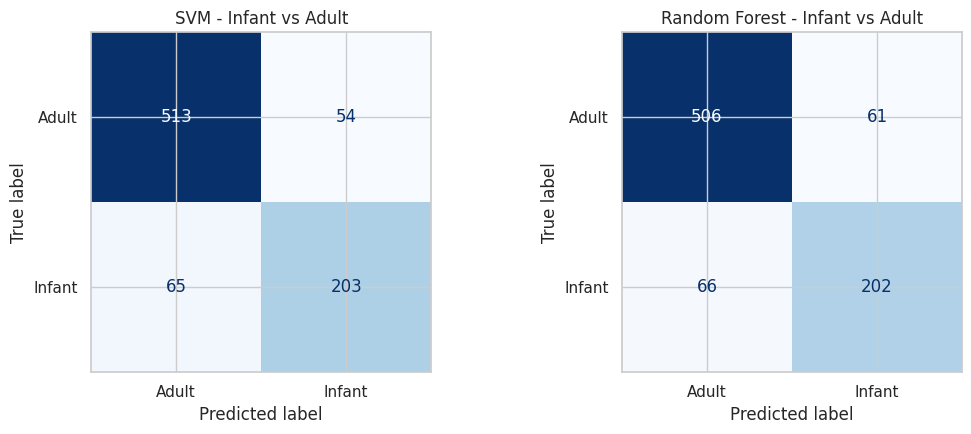

In [ ]:
# bin_confusion
# Target biner: Infant (I) vs Adult (M + F digabung). Prediktor, scaling, dan rasio split sama seperti Part 1.
y_bin_raw = np.where(df["Sex"] == "I", "Infant", "Adult")
le_b = LabelEncoder()
y_bin = le_b.fit_transform(y_bin_raw)          # Adult = 0, Infant = 1
bin_names = list(le_b.classes_)
Xb_train, Xb_test, yb_train, yb_test = train_test_split(
    df[feat_cls], y_bin, test_size=0.2, stratify=y_bin, random_state=RANDOM_STATE)
print("Latih:", Xb_train.shape, " Uji:", Xb_test.shape)
print("Proporsi Adult / Infant:", np.round(np.bincount(y_bin) / len(y_bin), 3))

svm_b = Pipeline([("scaler", StandardScaler()), ("clf", SVC(random_state=RANDOM_STATE))])
rf_b = Pipeline([("scaler", StandardScaler()), ("clf", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))])
svm_grid_b = {"clf__kernel": ["rbf"], "clf__C": [0.1, 1, 10, 100], "clf__gamma": ["scale", 0.01, 0.1]}
rf_grid_b = {"clf__n_estimators": [200], "clf__max_depth": [None, 6, 10],
             "clf__min_samples_leaf": [1, 5, 10], "clf__max_features": ["sqrt"]}
cv5b = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
gs_svm_b = GridSearchCV(svm_b, svm_grid_b, cv=cv5b, scoring="accuracy", n_jobs=-1).fit(Xb_train, yb_train)
gs_rf_b = GridSearchCV(rf_b, rf_grid_b, cv=cv5b, scoring="accuracy", n_jobs=-1).fit(Xb_train, yb_train)
print("SVM parameter terbaik:", gs_svm_b.best_params_, "| accuracy CV =", round(gs_svm_b.best_score_, 4))
print("RF  parameter terbaik:", gs_rf_b.best_params_, "| accuracy CV =", round(gs_rf_b.best_score_, 4))
best_svm_b, best_rf_b = gs_svm_b.best_estimator_, gs_rf_b.best_estimator_

def evaluate_bin(model):
    p = model.predict(Xb_test)
    return {"Accuracy": accuracy_score(yb_test, p),
            "Precision (macro)": precision_score(yb_test, p, average="macro"),
            "Recall (macro)": recall_score(yb_test, p, average="macro"),
            "F1 (macro)": f1_score(yb_test, p, average="macro"),
            "Precision (Infant)": precision_score(yb_test, p, pos_label=1),
            "Recall (Infant)": recall_score(yb_test, p, pos_label=1)}
dummy_b = DummyClassifier(strategy="most_frequent").fit(Xb_train, yb_train)
bin_table = pd.DataFrame({"Baseline majority-class": evaluate_bin(dummy_b),
                          "SVM (tuned)": evaluate_bin(best_svm_b),
                          "RF (tuned)": evaluate_bin(best_rf_b)}).T
display(bin_table.round(4))
for name, mdl in [("SVM", best_svm_b), ("Random Forest", best_rf_b)]:
    print(f"\n===== {name}: laporan per kelas =====")
    print(classification_report(yb_test, mdl.predict(Xb_test), target_names=bin_names, digits=3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, mdl) in zip(axes, [("SVM", best_svm_b), ("Random Forest", best_rf_b)]):
    ConfusionMatrixDisplay.from_predictions(yb_test, mdl.predict(Xb_test), display_labels=bin_names,
                                            cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(f"{name} - Infant vs Adult")
plt.tight_layout(); plt.show()

In [ ]:
# Robustness: 10-fold stratified CV pada SELURUH data (Infant vs Adult)
cv10b = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
cv_bin = {}
for name, mdl in [("SVM (tuned)", best_svm_b), ("RF (tuned)", best_rf_b)]:
    sc = cross_val_score(mdl, df[feat_cls], y_bin, cv=cv10b, scoring="accuracy", n_jobs=-1)
    cv_bin[name] = sc
    print(f"{name}: accuracy = {sc.mean():.4f} +/- {sc.std():.4f}")
t_b, p_b = stats.ttest_rel(cv_bin["SVM (tuned)"], cv_bin["RF (tuned)"])
print(f"Uji-t berpasangan pada 10 fold: t = {t_b:.2f}, p = {p_b:.3f}")
print("Baseline selalu menjawab Adult:", round(1 - y_bin.mean(), 4))

SVM (tuned): accuracy = 0.8282 +/- 0.0218
RF (tuned): accuracy = 0.8244 +/- 0.0230
Uji-t berpasangan pada 10 fold: t = 0.96, p = 0.364
Baseline selalu menjawab Adult: 0.679


#### **Penjelasan**

##### **1. Hasil pada Data Uji (835 Abalone)**

| Model | Akurasi | Precision (Macro) | Recall (Macro) | Precision (Infant) | Recall (Infant) |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **Baseline (Selalu "Adult")** | 0,679 | 0,340 | 0,500 | 0,000 | 0,000 |
| **SVM (RBF, $C=100, \gamma=\text{scale}$)** | **0,858** | **0,839** | **0,831** | **0,790** | **0,757** |
| **Random Forest (200 pohon, $\text{max\_depth}=10$)** | 0,848 | 0,826 | 0,823 | 0,768 | 0,754 |

##### **2. Analisis Performa Model**
* **Peningkatan Signifikan:** Akurasi mencapai **85,8% (SVM)** dan **84,8% (RF)**. Dimana ini menandakan terjadinya lonjakan sekitar 17–18 poin dari nilai *baseline* (67,9%). Hal ini sesuai dengan target performa yang diharapkan, khusus untuk menyelesaikan masalah biner *Infant vs. Adult*.
* **Validasi Menyeluruh (*10-Fold CV*):** Agar hasilnya lebih objektif, model dapat diuji menggunakan metode *10-fold CV* (diuji bergantian ke seluruh bagian data). Hasilnya adalah **82,8% $\pm$ 2,2%** untuk SVM dan **82,4% $\pm$ 2,3%** untuk Random Forest. Angka di data uji sebelumnya memang sedikit lebih tinggi karena faktor kebetulan saat membagi data (*split*). Jadi, rentang performa yang paling stabil dan realistis untuk model ini berada di kisaran **82% hingga 86%**.
* **SVM vs. Random Forest:** Kedua model menunjukkan performa yang **seri**. Selisih skor *CV* keduanya hanya 0,4 poin dan uji-t berpasangan menghasilkan nilai *p* = 0,36 (tidak signifikan secara statistik), meskipun SVM sedikit unggul di seluruh metrik pada data uji.

##### **3. Tantangan Klasifikasi: Kelas *Infant* Lebih Sulit**
* *Recall* untuk kelas *Infant* berada di angka $\approx$ 0,75 (artinya sekitar 1 dari 4 abalone *infant* salah diklasifikasikan sebagai *adult*) dengan tingkat *precision* di kisaran 0,77–0,79. Sebaliknya, kelas *Adult* jauh lebih mudah dikenali dengan skor *F1* mencapai $\approx$ 0,89.
* Hal ini terjadi karena misklasifikasi umumnya terjadi pada abalone transisional yaitu abalone muda yang ukurannya sudah telanjur besar tetapi status biologisnya masih *infant* atau sebaliknya yaout abalone dewasa yang ukurannya masih relatif kecil.

##### **4. Kesimpulan Akhir untuk Part 1 Secara Keseluruhan**
1. **Prediksi 3 Kelas (`Sex`):** Performa tertahan di kisaran **~56%**. Batas atas ini ditentukan murni oleh karakteristik data (abalone jantan dan betina memiliki ukuran fisik yang saling tumpang tindih secara penuh).
2. **Prediksi Biner (`Infant vs. Adult`):** Performa melesat ke kisaran **~82%–86%** (jauh melampaui *baseline* 67,9%). Eksperimen inilah yang merupakan bentuk klasifikasi *Sex/Kematangan* yang cukup akurat karena dapat dilakukan hanya dengan mengandalkan ukuran fisik abalone.

### **c. Perbandingan klasifikasi 3 kelas (F/I/M) dengan 2 kelas (Infant/Adult)**

Sel kode di bawah ini menyandingkan dua pendekatan pemodelan menggunakan **SVM** dan **Random Forest**:
1. **Klasifikasi 3 Kelas (Part 1):** Membedakan jenis kelamin *Female*, *Infant*, dan *Male*.
2. **Klasifikasi 2 Kelas (Part 1B):** Membedakan status kedewasaan *Infant* vs. *Adult* (penggabungan kelas *Female* & *Male*).

Dimana ini disajikan dalam satu tabel ringkas dan dua grafik visual utama:
* **Grafik Akurasi:** Membandingkan performa model terhadap *baseline* dari masing-masing skenario.
* **Grafik *Effect Size*:** Melihat seberapa jauh kelompok kategori terpisah pada setiap fitur fisik (berdasarkan nilai absolut Cohen's $d$ dari hasil uji statistik di EDA).

Hal ini dilakukan dengan **tujuan** untuk membuktikan **mengapa akurasi klasifikasi 3 kelas tidak bisa tinggi** sekaligus menjelaskan **mengapa metode dan fitur yang sama justru mampu bekerja dengan sangat baik** pada klasifikasi *Infant vs. Adult*.

,Skenario,Model,Baseline acc.,Accuracy (uji),Accuracy (CV),Precision (macro),Recall (macro),F1 (macro),Selisih thd baseline (poin)
0,3 kelas (F/I/M),SVM,0.3665,0.5653,0.5577,0.5898,0.5572,0.5153,19.8802
1,3 kelas (F/I/M),RF,0.3665,0.5617,0.5515,0.5517,0.5627,0.5500,19.5210
2,2 kelas (Infant/Adult),SVM,0.6790,0.8575,0.8282,0.8387,0.8311,0.8347,17.8443
3,2 kelas (Infant/Adult),RF,0.6790,0.8479,0.8244,0.8263,0.8231,0.8247,16.8862


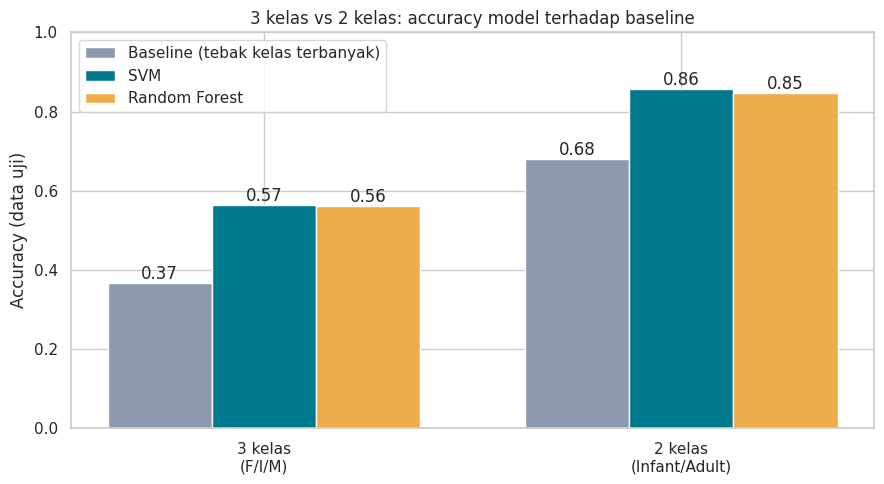

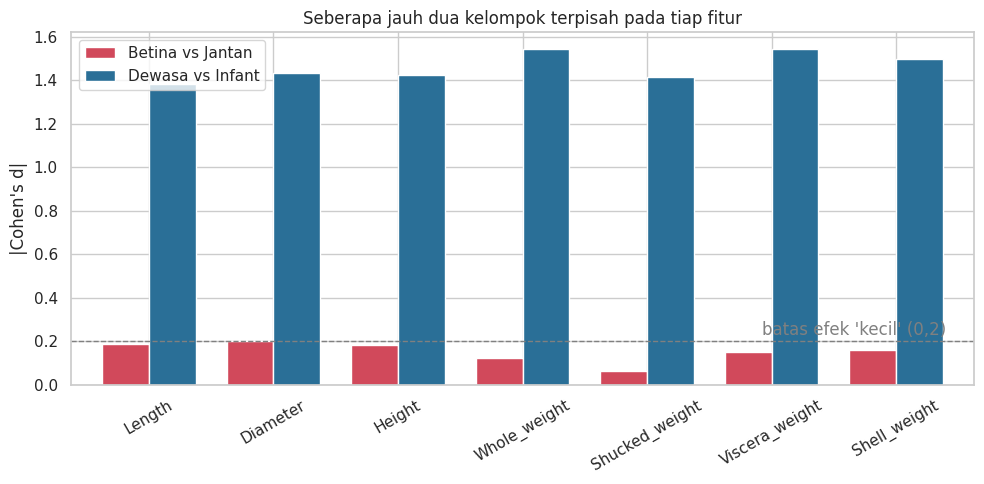

,Betina vs Jantan,Dewasa vs Infant
Variable,,
Length,0.188,1.382
Diameter,0.199,1.434
Height,0.182,1.427
Whole_weight,0.123,1.544
Shucked_weight,0.063,1.414
Viscera_weight,0.150,1.544
Shell_weight,0.157,1.497


In [ ]:
# cmp_scenario, cmp_effect
# Perbandingan berdampingan: klasifikasi 3 kelas (F/I/M) vs 2 kelas (Infant/Adult), SVM dan RF
rows = []
for scen, tbl, base_name, cvd in [("3 kelas (F/I/M)", cls_table, "Majority-class baseline", cv_rows),
                                  ("2 kelas (Infant/Adult)", bin_table, "Baseline majority-class", cv_bin)]:
    base_acc = tbl.loc[base_name, "Accuracy"]
    for mdl, key in [("SVM", "SVM (tuned)"), ("RF", "RF (tuned)")]:
        rows.append([scen, mdl, base_acc, tbl.loc[key, "Accuracy"], cvd[key].mean(),
                     tbl.loc[key, "Precision (macro)"], tbl.loc[key, "Recall (macro)"], tbl.loc[key, "F1 (macro)"]])
cmp_table = pd.DataFrame(rows, columns=["Skenario", "Model", "Baseline acc.", "Accuracy (uji)", "Accuracy (CV)",
                                        "Precision (macro)", "Recall (macro)", "F1 (macro)"])
cmp_table["Selisih thd baseline (poin)"] = (cmp_table["Accuracy (uji)"] - cmp_table["Baseline acc."]) * 100
display(cmp_table.round(4))

# Grafik 1: accuracy tiap skenario terhadap baseline-nya
fig, ax = plt.subplots(figsize=(9, 5))
labels = ["3 kelas\n(F/I/M)", "2 kelas\n(Infant/Adult)"]
xpos = np.arange(2); w = 0.25
base_v = [cmp_table[cmp_table["Skenario"] == sc]["Baseline acc."].iloc[0] for sc in cmp_table["Skenario"].unique()]
svm_v = cmp_table[cmp_table["Model"] == "SVM"]["Accuracy (uji)"].values
rf_v = cmp_table[cmp_table["Model"] == "RF"]["Accuracy (uji)"].values
for off, vals, lab, c in [(-w, base_v, "Baseline (tebak kelas terbanyak)", "#8d99ae"), (0, svm_v, "SVM", "#00798c"), (w, rf_v, "Random Forest", "#edae49")]:
    bars = ax.bar(xpos + off, vals, w, label=lab, color=c)
    for b_, v_ in zip(bars, vals): ax.text(b_.get_x() + b_.get_width() / 2, v_ + 0.01, f"{v_:.2f}", ha="center")
ax.set_xticks(xpos); ax.set_xticklabels(labels); ax.set_ylim(0, 1); ax.set_ylabel("Accuracy (data uji)")
ax.set_title("3 kelas vs 2 kelas: accuracy model terhadap baseline"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

# Grafik 2: MENGAPA? seberapa jauh dua kelompok terpisah pada tiap fitur (|Cohen's d|; makin besar makin mudah dipisahkan)
eff = test_tbl.set_index("Variable")[["Cohen d (F-M)", "Cohen d (adult-I)"]].drop("Rings").abs()
eff.columns = ["Betina vs Jantan", "Dewasa vs Infant"]
fig, ax = plt.subplots(figsize=(10, 5))
eff.plot.bar(ax=ax, color=["#d1495b", "#2a6f97"], width=0.75)
ax.set_ylabel("|Cohen's d|"); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=30)
ax.set_title("Seberapa jauh dua kelompok terpisah pada tiap fitur"); ax.axhline(0.2, ls="--", c="gray", lw=1)
ax.text(6.4, 0.23, "batas efek 'kecil' (0,2)", ha="right", color="gray")
plt.tight_layout(); plt.show()
display(eff.round(3))

#### **Penjelasan**

| Skenario | Baseline (tebak kelas terbanyak) | SVM | Random Forest |
|---|---|---|---|
| 3 kelas (F/I/M) | 0,367 | 0,565 (CV 0,558) | 0,562 (CV 0,552) |
| 2 kelas (Infant/Adult) | 0,679 | 0,858 (CV 0,828) | 0,848 (CV 0,824) |

Terlihat bahwa terdapat perbedaan akurasi klasifikasi F/I/M dengan Infant/Adult dengan angka yang cukup besar. Dimana hal ini dikarenakan oleh:
1. **Jantan dan betina hampir tidak berbeda pada ukuran tubuh.** Effect size betina dan jantan hanya |d| = 0,06-0,20 pada ketujuh fitur (paling besar Diameter 0,20, paling kecil Shucked weight 0,06) yaitu "sangat kecil" menurut kriteria umum. Distribusi kedua kelompok hampir sepenuhnya tumpang tindih (plot KDE dan violin di EDA), sehingga model apa pun tidak punya sinyal untuk memisahkannya.
2. **Kesalahan model terkonsentrasi pada F vs M.** Infant dikenali dengan baik (recall 0,83-0,85) tetapi betina hanya ditemukan 16% (SVM) dan 36% (RF) karena sebagian besar dikira jantan. Di antara abalone dewasa saja, M vs F hanya mencapai 56% dibandingkan 54% bila menebak "M" terus (analisis sensitivitas Part 1) dan model dua tahap (Infant vs Adult lalu M vs F) tetap menghasilkan sekitar 56% untuk 3 kelas.
3. **Keterbatasan data, bukan algoritma.** Memperbaiki tuning, memakai fitur rasio atau log-transform, class weight, bahkan model yang lebih kompleks (gradient boosting, extra trees, logistic regression) semuanya tetap berada di 54-56% pada cross-validation. Jenis kelamin abalone tidak tercermin pada ukuran cangkang atau berat, pembeda biologisnya (misalnya gonad) tidak ada dalam dataset.
4. **Perlu dibaca relatif terhadap baseline.** Dengan 3 kelas hampir seimbang, menebak kelas terbanyak hanya 36,7% sehingga 56% berarti model sudah +19-20 poin di atas baseline. Peningkatannya hampir seluruhnya berasal dari pengenalan Infant, bukan dari pemisahan M vs F.

**Meskipun demikian, SVM dan RF cukup baik untuk mengklasifikasi Infant dan Adult karena:**
1. **Kedua kelompok terpisah sangat jauh pada setiap fitur.** Effect size dewasa vs infant |d| = 1,38-1,54 pada ketujuh fitur, sekitar 7-20 kali lebih besar daripada betina dengan jantan dan jauh di atas kriteria efek "besar" (0,8). Ketujuh fitur juga berkorelasi tinggi, sehingga saling menguatkan sinyal "ukuran" yang sama.
2. **Ada dasar biologisnya.** Abalone mencapai kematangan seksual pada ukuran tertentu, jadi infant memang cenderung lebih kecil, lebih ringan, dan lebih muda (rata-rata 7,9 rings vs sekitar 11 pada dewasa). Pola ini bisa dipelajari dari ukuran tubuh.
3. **Hasilnya jauh di atas baseline.** Accuracy 85,8% (SVM) dan 84,8% (RF) pada data uji (CV 82-83%) dibandingkan 67,9% bila selalu menjawab "Adult" yaitu +17-18 poin, dengan precision dan recall makro sekitar 0,82-0,84.
4. **Kesalahan yang tersisa dapat dianulir.** Recall Infant sekitar 0,75 dengan kesalahan terutama pada abalone yang hampir dewasa (sudah besar tetapi masih infant) dan dewasa muda yang masih kecil sehingga kasus di dekat ambang kedewasaan bukan kesalahan acak.

**Kesimpulan perbandingan.**

Selisih performa antara kedua skenario bukan karena SVM atau RF bekerja lebih baik pada satu skenario, tetapi karena **apa yang diminta dibedakan**: infant vs dewasa punya perbedaan besar pada ukuran tubuh, jantan vs betina tidak. Maka, dari ukuran fisik abalone, metode ini layak dipakai untuk menentukan **kedewasaan** (Infant vs Adult), tetapi tidak untuk menentukan **jenis kelamin** (M vs F). SVM dan RF konsisten seri di kedua skenario (uji-t berpasangan tidak signifikan: p = 0,35 untuk 3 kelas dan p = 0,36 untuk 2 kelas).

## **4. Regresi: Memprediksi Jumlah Cincin (`Rings`)**

Bagian ini berfungsi untuk memprediksi jumlah `Rings` (di mana perkiraan umur aktual adalah $\text{Rings} + 1,5$ tahun) menggunakan minimal dua model regresi. Dimana untuk evaluasi performanya akan dilakukan dengan membuat *scatter plot* beserta garis regresinya serta membandingkan nilai *Mean Squared Error* (MSE):

$$\text{MSE} = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$

* $y_i$ sebagai jumlah cincin sebenarnya sedangkan $\hat{y}_i$ adalah jumlah cincin hasil prediksi dan $n$ adalah jumlah abalone di data uji.
* **Metrik pendukung:**
  * **RMSE** ($\sqrt{\text{MSE}}$) dalam satuan asli "cincin".
  * **MAE** (rata-rata kesalahan absolut: $\frac{1}{n}\sum |y_i - \hat{y}_i|$).
  * **$R^2$** ($1 - \frac{\text{SS}_{\text{res}}}{\text{SS}_{\text{tot}}}$) untuk melihat proporsi variansi yang dapat dijelaskan model.

Adapun beberapa model yang diuji untuk memprediksi hal tersebut sebagai berikut:
* **Simple Linear Regression (SLR):**
   * Model linear sederhana: $\text{Rings} = \beta_0 + \beta_1 x$ dengan satu prediktor tunggal.
   * Prediktor dipilih menggunakan *5-fold CV* (untuk mencari MSE terendah) dari data latih.
* **Regresi Polinomial (Derajat 2):** Menggunakan prediktor tunggal yang sama $\text{Rings} = \beta_0 + \beta_1 x + \beta_2 x^2$. Dimana ini sengaja dipilih untuk menangani pola kelengkungan data yang terlihat pada EDA.
* **Multiple Linear Regression (MLR):**
   * Menggunakan 7 ukuran fisik yang telah distandardisasi ditambah variabel jenis kelamin (*Sex* yang di-*one-hot encode* dengan *Female* sebagai kategori acuan, sehingga menghasilkan kolom `Sex_I` dan `Sex_M`).
* **MLR pada Transformasi Logaritma ($\log(\text{Rings})$):** Menggunakan spesifikasi fitur yang sama dengan MLR, namun dilatih menggunakan target $\log(\text{Rings})$ lalu ditransformasi balik ke skala asli untuk menguji apakah pola sebaran berbentuk corong (*heteroskedastisitas*) dapat diperbaiki.
* **Random Forest Regressor:** Digunakan sebagai pembanding non-linear (*ensemble*) yang disetel (*tuned*) menggunakan *cross-validation* pada data latih.

Dimana untuk pegaturan pengujian, akan dilakukan dengan:
* **Pembagian Data:** Menggunakan rasio 80% latih / 20% uji yang konsisten dan sama (*stratified* berdasarkan `Sex`, dengan `random_state = 42`).

In [ ]:
target = "Rings"
X_reg = df[num_features + ["Sex"]]
y_reg = df[target]
Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_reg, y_reg, test_size=0.2, stratify=df["Sex"], random_state=RANDOM_STATE)
print("Train:", Xr_train.shape, " Test:", Xr_test.shape)

# Pemilihan Prediktor Terbaik untuk Regresi Sederhana
# Berdasarkan evaluasi nilai MSE menggunakan 5-Fold Cross-Validation khusus pada Data Latih
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
single_rows = []
for col in num_features:
    mse_cv = -cross_val_score(LinearRegression(), Xr_train[[col]], yr_train, cv=kf, scoring="neg_mean_squared_error").mean()
    single_rows.append([col, mse_cv, np.corrcoef(Xr_train[col], yr_train)[0, 1]])
single_tbl = pd.DataFrame(single_rows, columns=["Feature", "CV MSE (train)", "Pearson r"]).sort_values("CV MSE (train)")
display(single_tbl.round(4))
best_single = single_tbl.iloc[0, 0]
print("Fitur yang dipilih untuk model sederhana:", best_single)

Train: (3339, 8)  Test: (835, 8)


,Feature,CV MSE (train),Pearson r
6,Shell_weight,6.2482,0.6320
2,Height,6.5851,0.6062
1,Diameter,6.9847,0.5733
0,Length,7.1946,0.5555
3,Whole_weight,7.3804,0.5392
5,Viscera_weight,7.7780,0.5023
4,Shucked_weight,8.5895,0.4178


Fitur yang dipilih untuk model sederhana: Shell_weight


In [ ]:
# ---------- Definisi model ----------
pre_full = ColumnTransformer([("num", StandardScaler(), num_features),
                              ("sex", OneHotEncoder(drop="first"), ["Sex"])])   # Sex -> 2 variabel dummy

models = {
    "Simple Linear Regression": Pipeline([("sel", ColumnTransformer([("x", "passthrough", [best_single])])),
                                          ("lr", LinearRegression())]),
    "Polynomial Regression (deg 2)": Pipeline([("sel", ColumnTransformer([("x", StandardScaler(), [best_single])])),
                                               ("poly", PolynomialFeatures(2, include_bias=False)),
                                               ("lr", LinearRegression())]),
    "Multiple Linear Regression": Pipeline([("pre", pre_full), ("lr", LinearRegression())]),
    "MLR on log(Rings)": TransformedTargetRegressor(
        regressor=Pipeline([("pre", pre_full), ("lr", LinearRegression())]), func=np.log, inverse_func=np.exp),
}
# Model Pembanding Non-Linear: Random Forest Regressor
# Di-tuning menggunakan Cross-Validation khusus pada data latih
rf_reg_grid = {"rf__n_estimators": [300], "rf__max_depth": [None, 8, 12], "rf__min_samples_leaf": [3, 5, 10],
               "rf__max_features": ["sqrt", 0.5, 1.0]}
gs_rfr = GridSearchCV(Pipeline([("pre", pre_full), ("rf", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1))]),
                      rf_reg_grid, cv=kf, scoring="neg_mean_squared_error", n_jobs=-1).fit(Xr_train, yr_train)
print("RF regressor parameter terbaik:", gs_rfr.best_params_)
models["Random Forest Regressor"] = gs_rfr.best_estimator_

for name, m in models.items():
    if name != "Random Forest Regressor":
        m.fit(Xr_train, yr_train)

reg_rows, preds_te, preds_tr = [], {}, {}
for name, m in models.items():
    p_tr, p_te = m.predict(Xr_train), m.predict(Xr_test)
    preds_tr[name], preds_te[name] = p_tr, p_te
    cv_mse = -cross_val_score(m, Xr_train, yr_train, cv=kf, scoring="neg_mean_squared_error", n_jobs=-1).mean()
    reg_rows.append([name, mean_squared_error(yr_train, p_tr), mean_squared_error(yr_test, p_te), cv_mse,
                     np.sqrt(mean_squared_error(yr_test, p_te)), mean_absolute_error(yr_test, p_te), r2_score(yr_test, p_te)])
reg_table = pd.DataFrame(reg_rows, columns=["Model", "Train MSE", "Test MSE", "CV MSE (train)", "Test RMSE", "Test MAE", "Test R2"]).set_index("Model")
display(reg_table.round(4))
print("Baseline (selalu prediksi rata-rata data latih): MSE uji =",
      round(mean_squared_error(yr_test, np.full(len(yr_test), yr_train.mean())), 4))

RF regressor parameter terbaik: {'rf__max_depth': None, 'rf__max_features': 0.5, 'rf__min_samples_leaf': 5, 'rf__n_estimators': 300}


,Train MSE,Test MSE,CV MSE (train),Test RMSE,Test MAE,Test R2
Model,,,,,,
Simple Linear Regression,6.2436,6.5098,6.2482,2.5514,1.8361,0.3729
Polynomial Regression (deg 2),6.0973,6.3378,6.1086,2.5175,1.8154,0.3895
Multiple Linear Regression,4.6295,5.2585,4.6816,2.2931,1.6292,0.4935
MLR on log(Rings),4.9134,5.5286,4.9526,2.3513,1.6389,0.4675
Random Forest Regressor,2.4463,4.7053,4.4998,2.1692,1.5104,0.5468


Baseline (selalu prediksi rata-rata data latih): MSE uji = 10.3895


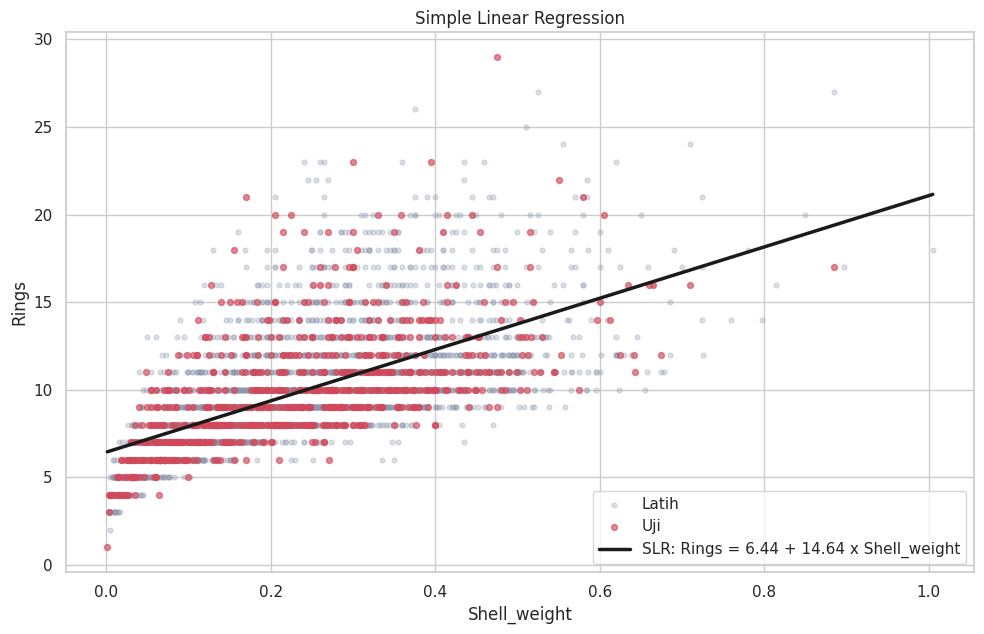

Persamaan hasil fit: Rings = 6.4387 + 14.6388 * Shell_weight


In [ ]:
# reg_slr
# Simple Linear Regression: scatter + garis hasil fit
slr = models["Simple Linear Regression"]
b0, b1 = slr.named_steps["lr"].intercept_, slr.named_steps["lr"].coef_[0]
xs = np.linspace(df[best_single].min(), df[best_single].max(), 300)
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.scatter(Xr_train[best_single], yr_train, s=12, alpha=0.30, c="#8d99ae", label="Latih")
ax.scatter(Xr_test[best_single], yr_test, s=18, alpha=0.65, c="#d1495b", label="Uji")
ax.plot(xs, b0 + b1 * xs, c="k", lw=2.5, label=f"SLR: Rings = {b0:.2f} + {b1:.2f} x {best_single}")
ax.set_xlabel(best_single); ax.set_ylabel("Rings"); ax.set_title("Simple Linear Regression")
ax.legend(); plt.tight_layout(); plt.show()
print(f"Persamaan hasil fit: Rings = {b0:.4f} + {b1:.4f} * {best_single}")

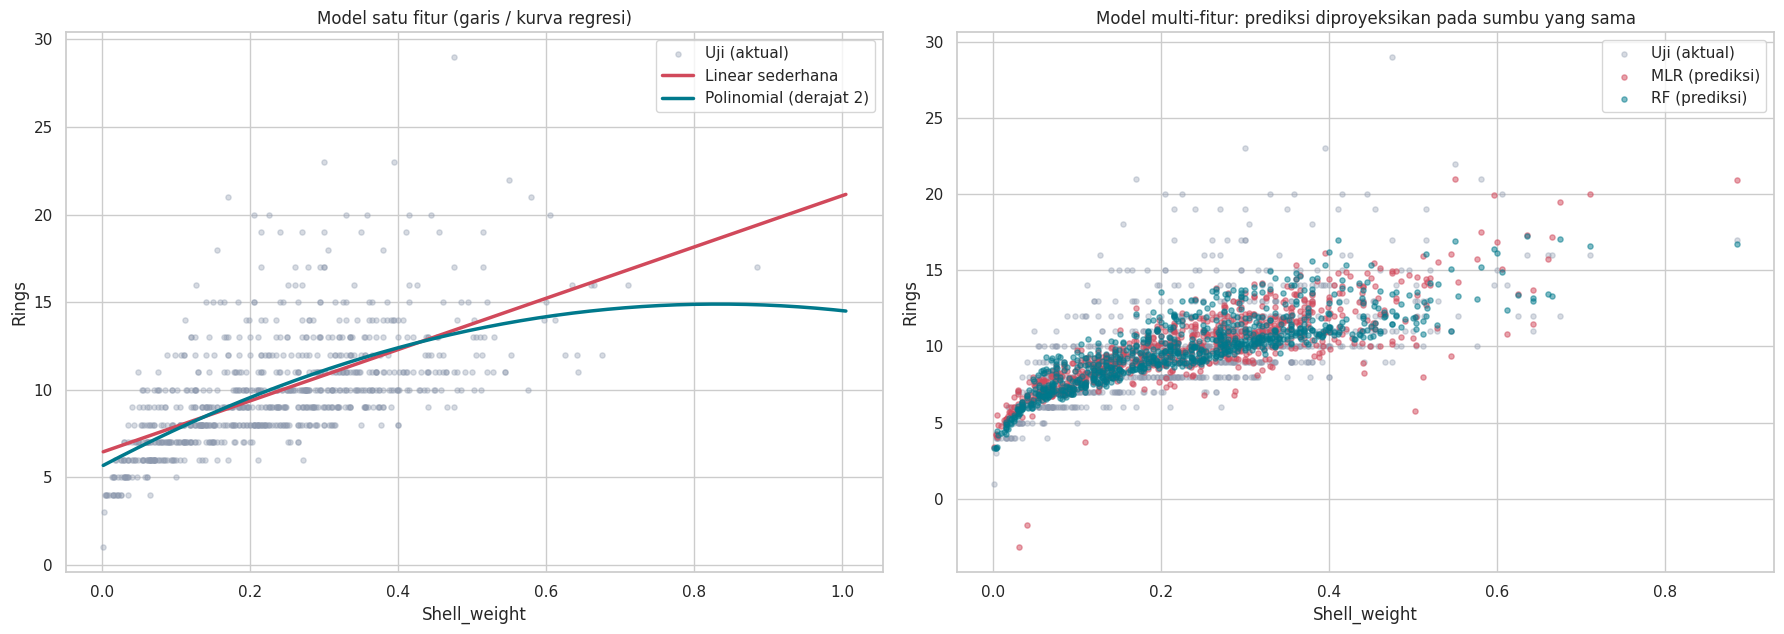

In [ ]:
# reg_curves
# Semua fit satu fitur (garis SLR, kurva polinomial) dan model multi-fitur diproyeksikan pada sumbu yang sama
poly = models["Polynomial Regression (deg 2)"]
xs_df = pd.DataFrame({c: np.repeat(Xr_train[c].median(), 300) for c in num_features}); xs_df[best_single] = xs
xs_df["Sex"] = "M"
fig, axes = plt.subplots(1, 2, figsize=(18, 6.5))
for ax in axes:
    ax.scatter(Xr_test[best_single], yr_test, s=14, alpha=0.35, c="#8d99ae", label="Uji (aktual)")
    ax.set_xlabel(best_single); ax.set_ylabel("Rings")
axes[0].plot(xs, slr.predict(xs_df), c="#d1495b", lw=2.5, label="Linear sederhana")
axes[0].plot(xs, poly.predict(xs_df), c="#00798c", lw=2.5, label="Polinomial (derajat 2)")
axes[0].set_title("Model satu fitur (garis / kurva regresi)"); axes[0].legend()
axes[1].scatter(Xr_test[best_single], preds_te["Multiple Linear Regression"], s=14, alpha=0.5, c="#d1495b", label="MLR (prediksi)")
axes[1].scatter(Xr_test[best_single], preds_te["Random Forest Regressor"], s=14, alpha=0.5, c="#00798c", label="RF (prediksi)")
axes[1].set_title("Model multi-fitur: prediksi diproyeksikan pada sumbu yang sama"); axes[1].legend()
plt.tight_layout(); plt.show()

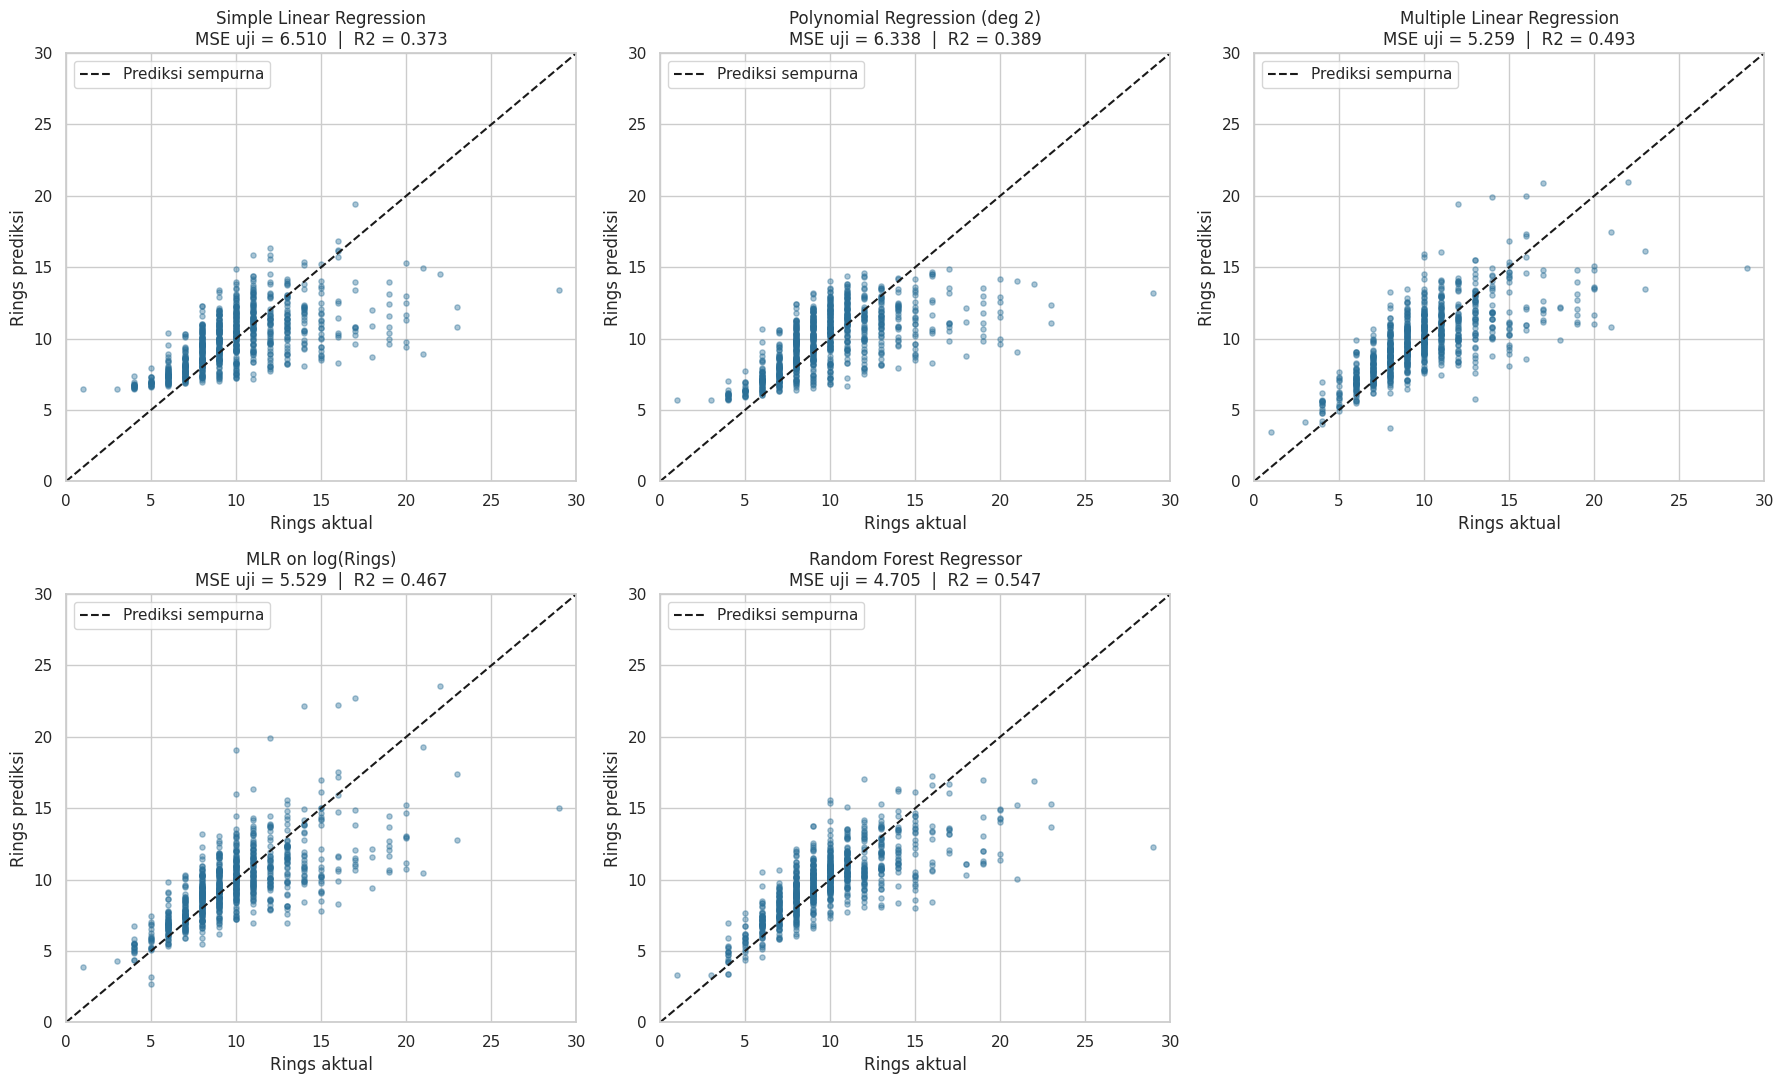

In [ ]:
# reg_actual_pred
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
for ax, (name, p) in zip(axes.ravel(), preds_te.items()):
    ax.scatter(yr_test, p, s=14, alpha=0.4, c="#2a6f97")
    lim = [0, 30]; ax.plot(lim, lim, "k--", lw=1.5, label="Prediksi sempurna")
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel("Rings aktual"); ax.set_ylabel("Rings prediksi")
    ax.set_title(f"{name}\nMSE uji = {mean_squared_error(yr_test, p):.3f}  |  R2 = {r2_score(yr_test, p):.3f}"); ax.legend()
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

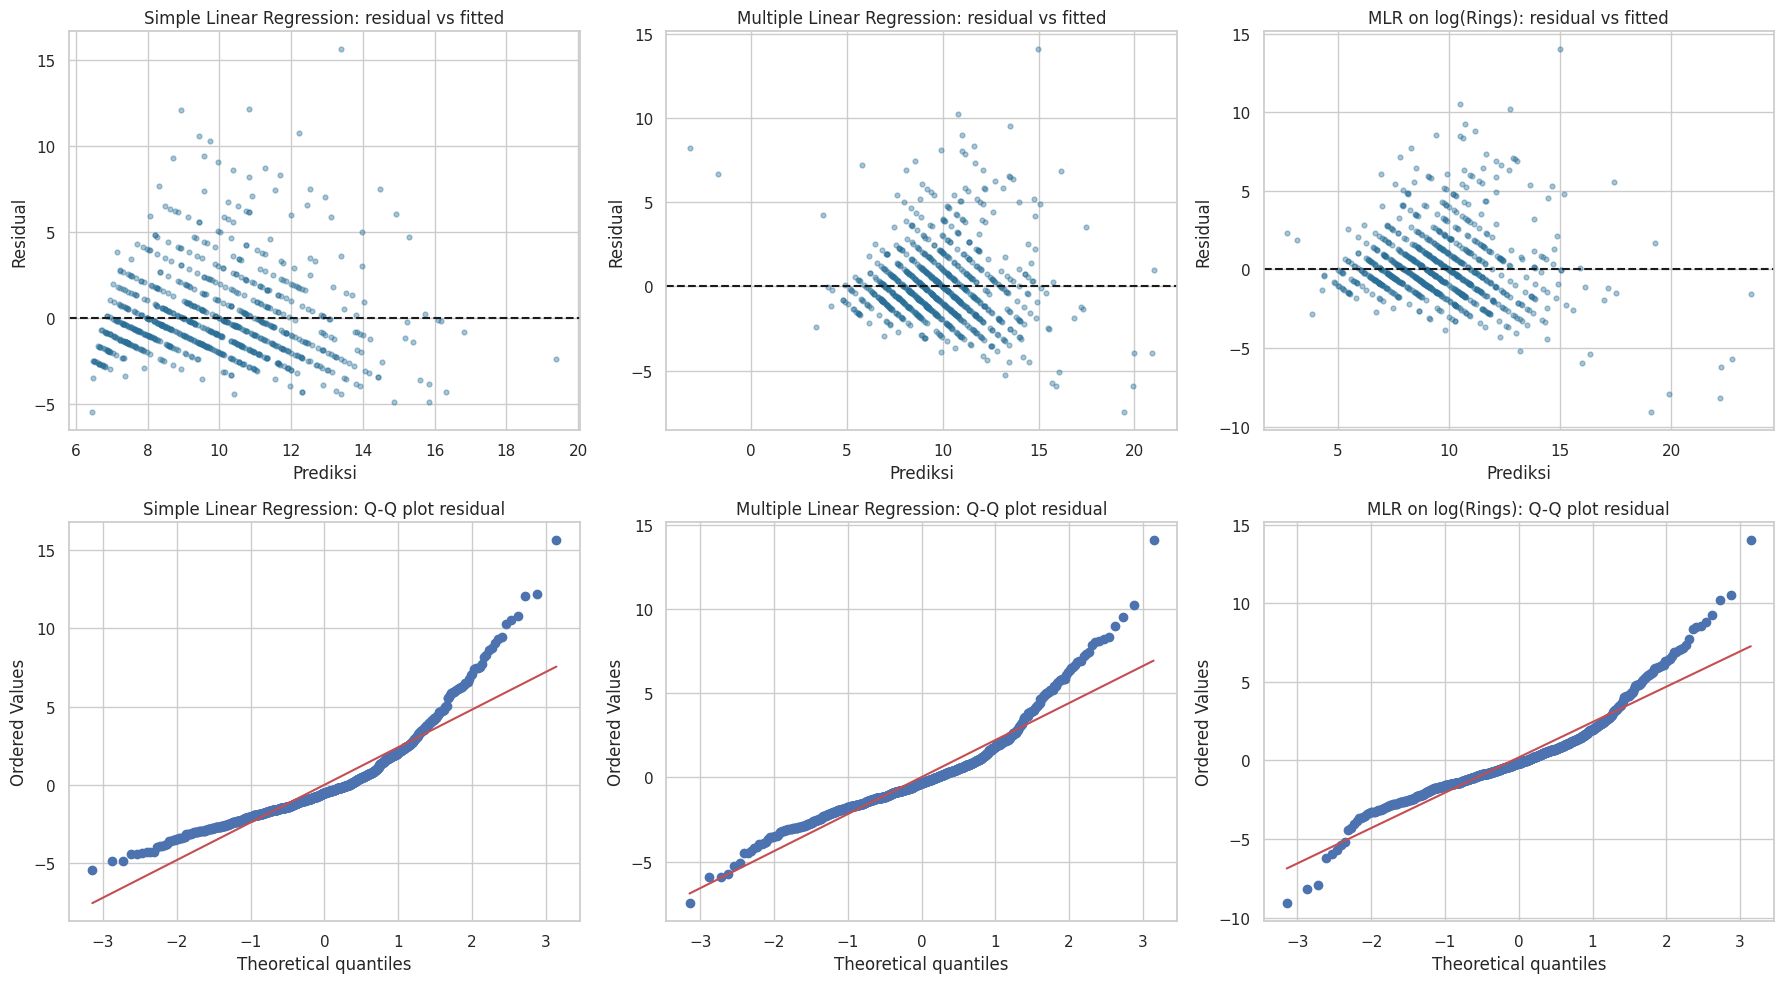

In [ ]:
# reg_residuals
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for j, name in enumerate(["Simple Linear Regression", "Multiple Linear Regression", "MLR on log(Rings)"]):
    p = preds_te[name]; r = yr_test.values - p
    axes[0, j].scatter(p, r, s=12, alpha=0.4, c="#2a6f97"); axes[0, j].axhline(0, c="k", ls="--")
    axes[0, j].set_xlabel("Prediksi"); axes[0, j].set_ylabel("Residual"); axes[0, j].set_title(f"{name}: residual vs fitted")
    stats.probplot(r, dist="norm", plot=axes[1, j]); axes[1, j].set_title(f"{name}: Q-Q plot residual")
plt.tight_layout(); plt.show()

In [ ]:
# Ringkasan OLS untuk Multiple Linear Regression
# Menghitung koefisien, standard error, nilai t, dan nilai p secara manual menggunakan NumPy
Xd = pd.get_dummies(Xr_train, columns=["Sex"], drop_first=True).astype(float)
Xm = np.column_stack([np.ones(len(Xd)), Xd.values]); yv = yr_train.values
beta = np.linalg.solve(Xm.T @ Xm, Xm.T @ yv)
resid = yv - Xm @ beta
dof = len(yv) - Xm.shape[1]
sigma2 = resid @ resid / dof
se = np.sqrt(np.diag(sigma2 * np.linalg.inv(Xm.T @ Xm)))
tvals = beta / se
pvals = 2 * (1 - stats.t.cdf(np.abs(tvals), dof))
ols = pd.DataFrame({"coef": beta, "std err": se, "t": tvals, "p-value": pvals}, index=["Intercept"] + list(Xd.columns))
display(ols.style.format({"coef": "{:.3f}", "std err": "{:.3f}", "t": "{:.2f}", "p-value": "{:.2e}"}))
print(f"R2 data latih = {1 - resid @ resid / ((yv - yv.mean()) @ (yv - yv.mean())):.4f}")

,coef,std err,t,p-value
Intercept,3.510,0.327,10.74,0.00e+00
Length,-0.810,1.993,-0.41,6.84e-01
Diameter,9.356,2.471,3.79,1.55e-04
Height,21.610,2.563,8.43,0.00e+00
Whole_weight,9.228,0.816,11.31,0.00e+00
Shucked_weight,-20.534,0.927,-22.14,0.00e+00
Viscera_weight,-10.953,1.423,-7.69,1.87e-14
Shell_weight,8.124,1.261,6.44,1.36e-10
Sex_I,-0.768,0.112,-6.84,9.30e-12
Sex_M,0.091,0.091,0.99,3.21e-01


R2 data latih = 0.5547


In [ ]:
# Memprediksi jumlah rings (dibulatkan ke bilangan bulat) dan mengukur akurasi praktis
cmp = pd.DataFrame({"Actual": yr_test.values,
                    "SLR": preds_te["Simple Linear Regression"],
                    "MLR": preds_te["Multiple Linear Regression"],
                    "RF": preds_te["Random Forest Regressor"]}, index=yr_test.index)
print("Sepuluh abalone uji acak (prediksi kontinu -> dibulatkan):")
display(cmp.sample(10, random_state=1).round(2).assign(
    SLR_rounded=lambda d: d["SLR"].round().astype(int), MLR_rounded=lambda d: d["MLR"].round().astype(int),
    RF_rounded=lambda d: d["RF"].round().astype(int)))

rows = {}
for m in ["SLR", "MLR", "RF"]:
    err = np.abs(np.round(cmp[m]) - cmp["Actual"])
    rows[m] = {"Exact ring count": (err == 0).mean(), "Within +/-1 ring": (err <= 1).mean(), "Within +/-2 rings": (err <= 2).mean()}
display((pd.DataFrame(rows).T * 100).round(1).rename_axis("Model").add_suffix(" (%)"))

Sepuluh abalone uji acak (prediksi kontinu -> dibulatkan):


,Actual,SLR,MLR,RF,SLR_rounded,MLR_rounded,RF_rounded
349,14,10.54,10.00,9.52,11,10,10
2203,6,7.05,6.44,5.94,7,6,6
2273,20,12.95,14.79,14.24,13,15,14
3795,13,14.19,15.52,14.10,14,16,14
4034,10,9.22,9.12,9.85,9,9,10
3186,16,16.17,17.21,13.30,16,17,13
2255,13,10.61,12.98,13.72,11,13,14
3556,10,9.99,9.14,9.26,10,9,9
2605,9,11.10,11.76,10.64,11,12,11
2435,9,7.24,7.08,6.87,7,7,7


,Exact ring count (%),Within +/-1 ring (%),Within +/-2 rings (%)
Model,,,
SLR,19.6,51.6,77.2
MLR,22.4,59.5,80.8
RF,22.5,65.1,85.0


#### **Penjelasan**

##### **1. Performa pada Data Uji**

| Model | MSE Uji | RMSE | MAE | $R^2$ |
| :--- | :---: | :---: | :---: | :---: |
| **Baseline (Nilai Rata-rata)** | 10,39 | 3,22 | — | 0,00 |
| **Simple Linear Regression** (*Shell_weight*) | 6,51 | 2,55 | 1,84 | 0,373 |
| **Regresi Polinomial** (Derajat 2, *Shell_weight*) | 6,34 | 2,52 | 1,82 | 0,389 |
| **Multiple Linear Regression** | **5,26** | 2,29 | 1,63 | 0,493 |
| **MLR dengan Transformasi Logaritma** ($\log(\text{Rings})$) | 5,53 | 2,35 | 1,64 | 0,467 |
| **Random Forest Regressor** | **4,71** | 2,17 | 1,51 | 0,547 |

##### **2. Perbandingan Kinerja Model Regresi**
* **Multiple Linear Regression** terlihat lebih unggul daripada model linear dengan penurunan nilai MSE sebesar 19% (dari 6,51 menjadi 5,26) serta peningkatan $R^2$ dari 0,37 menjadi 0,49. Konsistensi antara MSE data uji dan MSE *cross-validation* pada data latih (4,68 berbanding 6,25) mengonfirmasi bahwa performa ini valid dan bukan sekadar kebetulan.
* **Regresi Polinomial** berderajat dua hanya memberikan sedikit perbaikan/perubahan terhadap *Simple Linear Regression* (menghasilkan MSE 6,34).
* **Random Forest Regressor** mempunyai tingkat keakuratan tertinggi dengan MSE 4,71. Meskipun demikian, model ini mengalami gejala *overfitting* yang cukup signifikan (MSE data latih mencapai 2,45) serta kehilangan kemampuan untuk direpresentasikan sebagai persamaan matematis.

##### **3. Analisis Pola Sebaran Visual**
* **Scatter Plot dan Garis Regresi:** Garis regresi tunggal mampu menggambarkan tren kenaikan secara umum, namun sebaran data membentuk pita lebar yang melengkung. Spesimen berukuran muda terprediksi dengan baik, sementara garis regresi cenderung terlalu tinggi untuk sebagian abalone serta terlalu rendah bagi sebagian abalone berusia lanjut.
* **Nilai Aktual dan Prediksi:** Seluruh model cenderung membatasi rentang estimasi pada kisaran 5 hingga 15 cincin. Spesimen yang memiliki jumlah cincin $\ge 18$ selalu mengalami estimasi yang terlalu rendah (*underestimated*). Sebagai contoh, abalone dengan 20 cincin hanya diprediksi pada kisaran 13 hingga 15 cincin. Hal ini terjadi karena pertumbuhan ukuran fisik mencapai titik jenuh setelah dewasa, sementara cangkang terus memproduksi cincin baru. Dimana keterbatasan struktural ini tidak dapat diselesaikan hanya melalui optimasi prediktor yang terdapat pada data ini.
* **Analisis Residual:** Sebaran residual membentuk pola menyerupai corong seiring dengan meningkatnya nilai prediksi (*heteroskedastisitas*) dan grafik Q-Q menunjukkan ekor kanan pada kurva yang menumpuk akibat keberadaan spesimen tua. Penggunaan target berformat logaritmik berhasil menstabilkan variansi, namun gagal memperbaiki nilai MSE pada skala aslinya (5,53) karena besaran MSE didominasi oleh sejumlah kecil spesimen tua yang hasil transformasi baliknya terkompresi.

##### **4. Interpretasi Koefisien Multiple Linear Regression**
Berdasarkan estimasi OLS pada data latih:
* Variabel *Height* (+21,6), *Diameter* (+9,4), *Whole weight* (+9,2), dan *Shell weight* (+8,1) memiliki hubungan searah dan positif terhadap jumlah cincin.
* Variabel *Shucked weight* (–20,5) dan *Viscera weight* (–11,0) menunjukkan koefisien negatif.
* Variabel kategori jenis kelamin *Sex_I* bernilai –0,77 cincin (menandakan kelompok *infant* memiliki jumlah cincin yang lebih sedikit dibandingkan betina pada ukuran fisik yang setara dengan $p < 10^{-10}$), sementara *Sex_M* dan *Length* tidak signifikan secara statistik ($p = 0,32$ dan $p = 0,68$).

Tanda negatif pada *Shucked weight* menandakan bahwa meskipun korelasi bivariat mentahnya bernilai positif (+0,42), ini merupakan hasil dari **multikolinearitas ekstrem** dengan nilai VIF yang mencapai 111. Bobot daging yang relatif lebih besar terhadap berat total merupakan indikator spesimen muda yang sedang mengalami pertumbuhan pesat. Oleh sebab itu, koefisien independen wajib dibaca sebagai pengaruh parsial dengan asumsi keenam ukuran lainnya dikontrol tetap, di mana kestabilan prediksi keseluruhan tetap terjaga.

##### **5. Evaluasi Ketepatan Prediksi Diskrit**
Transformasi hasil estimasi kontinu menjadi bilangan bulat diskrit menunjukkan bahwa ketepatan absolut yang tepat hanya tercapai pada kisaran 20% hingga 22% spesimen. Kendati demikian, tingkat reliabilitas meningkat secara signifikan pada batas toleransi tertentu:
* **Toleransi $\pm 1$ Cincin:** Tercapai sebesar 52% (*Simple Linear Regression*), 60% (*Multiple Linear Regression*), dan 65% (*Random Forest*).
* **Toleransi $\pm 2$ Cincin:** Meningkat menjadi 77% (*Simple Linear Regression*), 81% (*Multiple Linear Regression*), dan 85% (*Random Forest*).

##### **6. Kekuatan dan Kelemahan Model Regresi**

###### **Simple Linear Regression (Regresi Linear Sederhana)**
* **Kelebihan (+):** Sangat mudah dipahami dan dijelaskan, mudah digambarkan dalam grafik, tidak mengalami masalah *overfitting* (hasil latih dan uji hampir sama, yaitu 6,24 berbanding 6,51), serta bebas dari masalah kolinearitas karena hanya menggunakan satu variabel saja.
* **Kelemahan (-):** Hanya memakai satu dari delapan informasi yang tersedia, menganggap pertumbuhan berjalan lurus padahal kurvanya melengkung, mengabaikan faktor jenis kelamin, serta memiliki tingkat kesalahan yang paling tinggi di antara model lainnya.

###### **Multiple Linear Regression (Regresi Linear Berganda)**
* **Kelebihan (+):** Mampu menggabungkan informasi ukuran dan berat secara bersamaan, menurunkan kesalahan prediksi (MSE) hingga 19%, bisa digunakan untuk menguji signifikansi statistik, serta tetap stabil dan cepat meskipun antar variabel saling berkaitan erat.
* **Kelemahan (-):** Masih berasumsi bahwa hubungannya berbentuk garis lurus, nilai koefisiennya bisa menjadi tidak stabil jika variabelnya saling mirip (multikolinearitas tinggi), sensitif terhadap data yang terlalu ekstrem (*outlier*), dan gagal memprediksi abalone usia lanjut karena bentuk pertumbuhan aslinya melambat/jenuh.

###### **Random Forest Regressor (Model Pembanding)**
* **Kelebihan (+):** Mampu menangani hubungan yang rumit dan tidak lurus secara otomatis, serta memberikan tingkat kesalahan (MSE) paling kecil dan akurasi terbaik dalam toleransi $\pm 1$ cincin pada data uji.
* **Kelemahan (-):** Cara pengerjaanya tertutup seperti kotak hitam sehingga rumusnya tidak bisa dilihat, buruk dalam menebak data di luar kisaran pelatihan (cenderung datar untuk abalone yang sangat besar), mudah mengalami *overfitting* (kesalahan di data latih sangat kecil, yaitu 2,45, tetapi membengkak jadi 4,71 saat diuji), dan tetap terbatas oleh informasi yang ada pada fitur data.

##### **7. Kesimpulan Regresi**
Ukuran fisik tubuh abalone hanya mampu menjelaskan sekitar setengah dari total variasi jumlah cincin ($R^2 \approx 0,5$). Sisa keberagaman yang ada ini berasal dari faktor luar dan lingkungan (seperti ketersediaan makanan, kondisi mikro-habitat, serta laju metabolisme) yang memang tidak dicatat di dalam dataset. Keterbatasan mendasar ini juga telah disebutkan secara resmi dalam dokumentasi berkas acuan data (`abalone.names`).

## **5. Clustering: Pola Berdasarkan Ukuran Fisik Pada Data**

Bagian ini berfungsi untuk mengelompokan data tanpa variabel target (`Sex` dan `Rings`) untuk menemukan struktur kelompok alami di dalam data menggunakan tiga algoritma utama: **K-Means, Spectral Clustering, dan Hierarchical Clustering**. Selanjutnya, akan menentukan jumlah klaster optimal (*k*), memvisualisasikannya, serta membandingkan hasil klaster tersebut dengan label faktual (*Sex* dan kelompok umur).

Adapun metodologi yang sudah disusun untuk menganalisis hal tersebut sebagai berikut:
* **Input Fitur:** Menggunakan 7 ukuran fisik yang telah distandardisasi (mengingat algoritma berbasis jarak sangat sensitif terhadap perbedaan skala fitur). Variabel `Sex` dan `Rings` **hanya digunakan pada tahap akhir** untuk keperluan validasi eksternal.
* **Visualisasi Proyeksi:** Menggunakan proyeksi *Principal Component Analysis* (PCA) 2D (di mana PC1 dan PC2 secara kumulatif menjelaskan 95,4% total variansi data). Visualisasi ini hanya berfungsi sebagai media plot, sementara proses *clustering* tetap dijalankan secara penuh di ruang multidimensi (7-D).
* **Pemilihan Jumlah Klaster ($k$ dari rentang 2 hingga 10):**
  * Menggunakan *Elbow Method* (Inertia/WCSS), *Silhouette Score* (semakin tinggi semakin baik), *Calinski-Harabasz Index*, dan *Davies-Bouldin Index* (semakin rendah semakin baik).
  * Menggunakan *Ward dendrogram* serta profil jarak penggabungan untuk *Hierarchical Clustering*.
  * Menggunakan *Silhouette* dan *Eigengap* untuk *Spectral Clustering*.
* **Algoritma yang Diuji:**
  * **K-Means:** Dijalankan dengan parameter `n_init=20`.
  * **Spectral Clustering:** Memanfaatkan graf kedekatan (*k-nearest-neighbour*) dengan 15 tetangga (kernel RBF memerlukan penyetelan *bandwidth* khusus).
  * **Agglomerative Clustering:** Menggunakan *Ward linkage* (sementara metode *average* dan *single linkage* turut diuji sebagai pembanding).
* **Validasi Eksternal:**
  * Mengukur tingkat kesesuaian menggunakan *Adjusted Rand Index* (ARI dengan skala 0 untuk acak total dan 1 untuk identik) serta *Normalized Mutual Information* (NMI) antara hasil klaster dengan: (a) Kategori jenis kelamin (`Sex`), dan (b) Kelompok usia (*Young* $\le 8$, *Middle* $9-10$, dan *Old* $\ge 11$ cincin).

In [ ]:
# Input clustering: HANYA 7 ukuran fisik (Sex dan Rings disembunyikan dari algoritma).
Xc = StandardScaler().fit_transform(df[num_features])
sex_true = df["Sex"].values
age_true = df["Age_group"].astype(str).values
print("Matriks clustering:", Xc.shape, "| mean ~", Xc.mean().round(3), "| std ~", Xc.std().round(3))

pca2 = PCA(n_components=2, random_state=RANDOM_STATE).fit(Xc)
Z2 = pca2.transform(Xc)
print("PCA (hanya untuk visualisasi): variansi dijelaskan oleh PC1, PC2 =", np.round(pca2.explained_variance_ratio_, 4))

Matriks clustering: (4174, 7) | mean ~ -0.0 | std ~ 1.0
PCA (hanya untuk visualisasi): variansi dijelaskan oleh PC1, PC2 = [0.9232 0.0306]


,Inertia (WCSS),Silhouette,Calinski-Harabasz,Davies-Bouldin
k,,,,
2,11127.593,0.513,6782.530,0.669
3,6638.815,0.442,7093.094,0.725
4,4663.367,0.416,7318.995,0.761
5,3634.219,0.386,7337.132,0.815
6,3119.583,0.358,6973.899,0.830
7,2728.733,0.337,6741.881,0.909
8,2472.675,0.313,6437.279,0.953
9,2285.948,0.294,6133.790,1.045
10,2174.086,0.265,5755.235,1.144


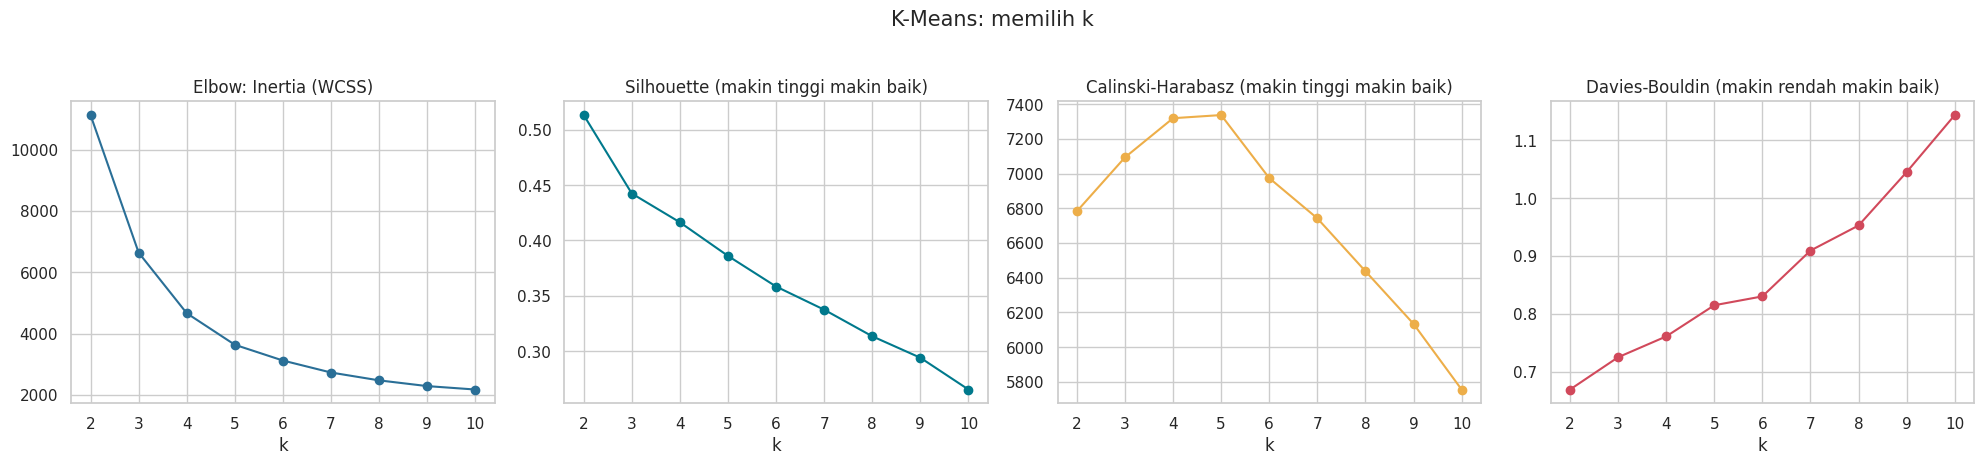

In [ ]:
# clu_kmeans_k
ks = list(range(2, 11))
km_rows = []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(Xc)
    km_rows.append([k, km.inertia_, silhouette_score(Xc, km.labels_), calinski_harabasz_score(Xc, km.labels_),
                    davies_bouldin_score(Xc, km.labels_)])
km_tbl = pd.DataFrame(km_rows, columns=["k", "Inertia (WCSS)", "Silhouette", "Calinski-Harabasz", "Davies-Bouldin"]).set_index("k")
display(km_tbl.round(3))
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, col, c in zip(axes, km_tbl.columns, ["#2a6f97", "#00798c", "#edae49", "#d1495b"]):
    ax.plot(km_tbl.index, km_tbl[col], "o-", c=c); ax.set_xlabel("k"); ax.set_title(col)
axes[0].set_title("Elbow: Inertia (WCSS)"); axes[1].set_title("Silhouette (makin tinggi makin baik)")
axes[2].set_title("Calinski-Harabasz (makin tinggi makin baik)"); axes[3].set_title("Davies-Bouldin (makin rendah makin baik)")
plt.suptitle("K-Means: memilih k", y=1.03, fontsize=15); plt.tight_layout(); plt.show()

,Linkage,Cophenetic corr.,Silhouette (k=3),Cluster sizes (k=3)
0,ward,0.620,0.437,"[1924, 1835, 415]"
1,complete,0.686,0.390,"[264, 2844, 1066]"
2,average,0.704,0.634,"[4172, 1, 1]"
3,single,0.337,0.634,"[4172, 1, 1]"


,Silhouette,Calinski-Harabasz,Davies-Bouldin
k,,,
2,0.504,6596.178,0.677
3,0.437,5502.625,0.739
4,0.386,6489.103,0.731
5,0.333,6460.798,0.902
6,0.319,6182.520,0.854
7,0.308,5798.836,0.905
8,0.274,5505.962,1.107
9,0.231,5365.484,1.127
10,0.221,5086.068,1.124


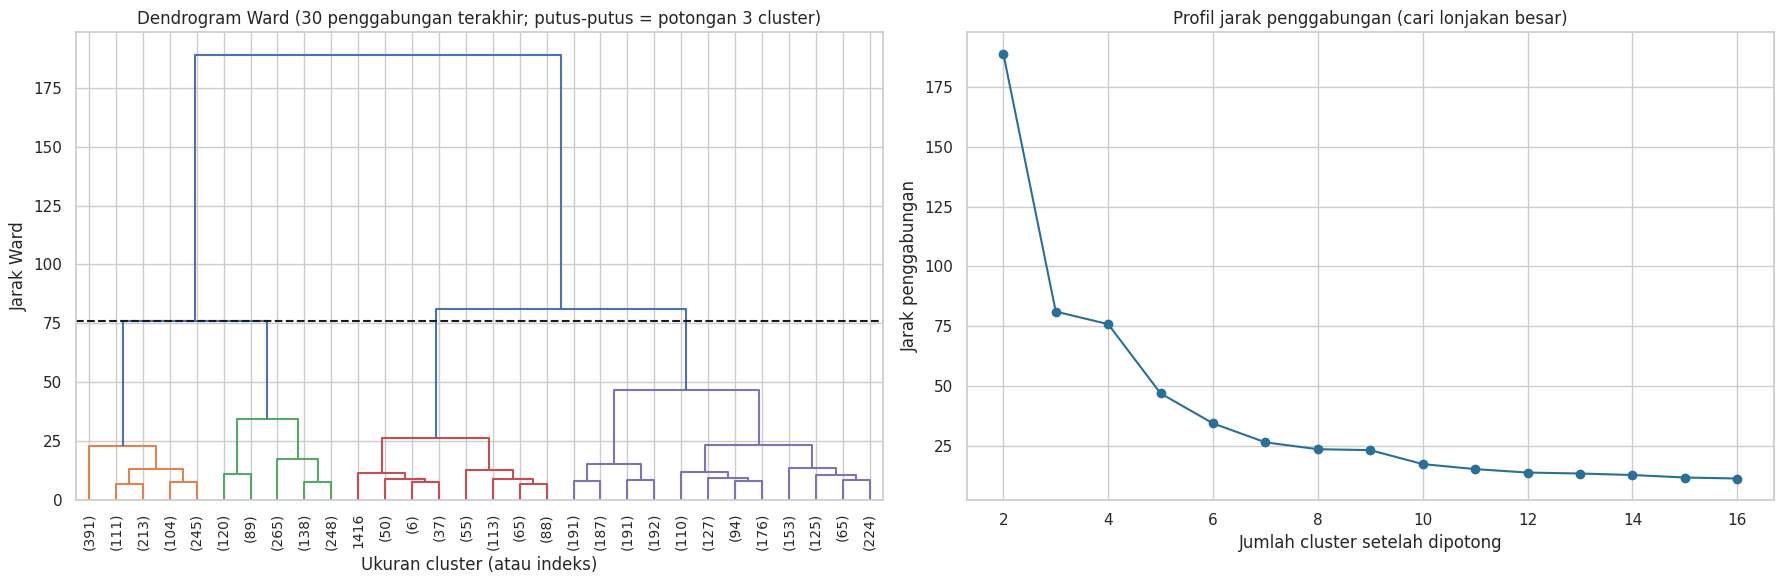

In [ ]:
# clu_hier_k
# Hierarchical (agglomerative) clustering: dendrogram + perbandingan linkage + silhouette per k
Z_ward = linkage(Xc, method="ward")
link_rows = []
d_orig = pdist(Xc)
for method in ["ward", "complete", "average", "single"]:
    Zl = linkage(Xc, method=method)
    coph, _ = cophenet(Zl, d_orig)
    lab3 = AgglomerativeClustering(n_clusters=3, linkage=method).fit_predict(Xc)
    link_rows.append([method, coph, silhouette_score(Xc, lab3), np.bincount(lab3).tolist()])
display(pd.DataFrame(link_rows, columns=["Linkage", "Cophenetic corr.", "Silhouette (k=3)", "Cluster sizes (k=3)"]).round(3))

hc_rows = []
for k in ks:
    lab = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(Xc)
    hc_rows.append([k, silhouette_score(Xc, lab), calinski_harabasz_score(Xc, lab), davies_bouldin_score(Xc, lab)])
hc_tbl = pd.DataFrame(hc_rows, columns=["k", "Silhouette", "Calinski-Harabasz", "Davies-Bouldin"]).set_index("k")
display(hc_tbl.round(3))

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
dendrogram(Z_ward, truncate_mode="lastp", p=30, ax=axes[0], leaf_rotation=90, color_threshold=Z_ward[-3, 2])
axes[0].axhline(Z_ward[-3, 2], c="k", ls="--"); axes[0].set_title("Dendrogram Ward (30 penggabungan terakhir; putus-putus = potongan 3 cluster)")
axes[0].set_xlabel("Ukuran cluster (atau indeks)"); axes[0].set_ylabel("Jarak Ward")
last = Z_ward[-15:, 2][::-1]
axes[1].plot(range(2, 17), last, "o-", c="#2a6f97"); axes[1].set_xlabel("Jumlah cluster setelah dipotong")
axes[1].set_ylabel("Jarak penggabungan"); axes[1].set_title("Profil jarak penggabungan (cari lonjakan besar)")
plt.tight_layout(); plt.show()

,Silhouette,Calinski-Harabasz,Davies-Bouldin
k,,,
2,0.448,3716.228,0.594
3,0.427,4715.670,0.632
4,0.401,5068.668,0.665
5,0.386,5653.518,0.701
6,0.367,5232.917,0.721
7,0.355,5636.706,0.764
8,0.330,5469.299,0.813
9,0.307,5004.024,0.854
10,0.295,5098.769,0.898


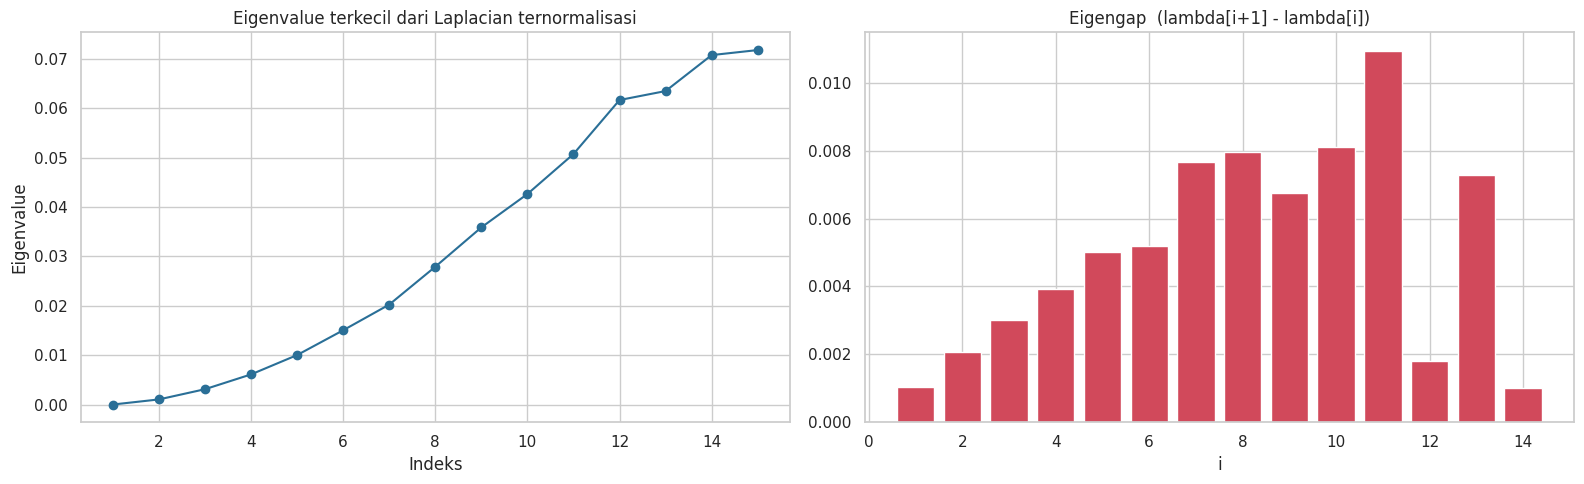

Eigenvalue: [0.     0.001  0.0031 0.0061 0.01   0.015  0.0203 0.0279 0.0359 0.0427
 0.0508 0.0617 0.0635 0.0708 0.0718]
Eigengap terbesar setelah eigenvalue ke- 11 -> menyarankan k = 11


In [ ]:
# clu_spectral_k
# Spectral clustering: graf afinitas k-nearest-neighbour (n_neighbors = 15) + silhouette per k + eigengap
N_NEIGH = 15
sp_rows = []
for k in ks:
    sp = SpectralClustering(n_clusters=k, affinity="nearest_neighbors", n_neighbors=N_NEIGH,
                            assign_labels="kmeans", random_state=RANDOM_STATE, n_jobs=-1)
    lab = sp.fit_predict(Xc)
    sp_rows.append([k, silhouette_score(Xc, lab), calinski_harabasz_score(Xc, lab), davies_bouldin_score(Xc, lab)])
sp_tbl = pd.DataFrame(sp_rows, columns=["k", "Silhouette", "Calinski-Harabasz", "Davies-Bouldin"]).set_index("k")
display(sp_tbl.round(3))

# Heuristik eigen gap pada Laplacian ternormalisasi dari graf kNN yang sama
A = kneighbors_graph(Xc, N_NEIGH, include_self=False); A = 0.5 * (A + A.T)
L = laplacian(A, normed=True).toarray()
eigvals = eigh(L, eigvals_only=True, subset_by_index=[0, 14])
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].plot(range(1, 16), eigvals, "o-", c="#2a6f97"); axes[0].set_xlabel("Indeks"); axes[0].set_ylabel("Eigenvalue")
axes[0].set_title("Eigenvalue terkecil dari Laplacian ternormalisasi")
axes[1].bar(range(1, 15), np.diff(eigvals), color="#d1495b"); axes[1].set_xlabel("i"); axes[1].set_title("Eigengap  (lambda[i+1] - lambda[i])")
plt.tight_layout(); plt.show()
print("Eigenvalue:", np.round(eigvals, 4))
print("Eigengap terbesar setelah eigenvalue ke-", int(np.argmax(np.diff(eigvals))) + 1, "-> menyarankan k =", int(np.argmax(np.diff(eigvals))) + 1)

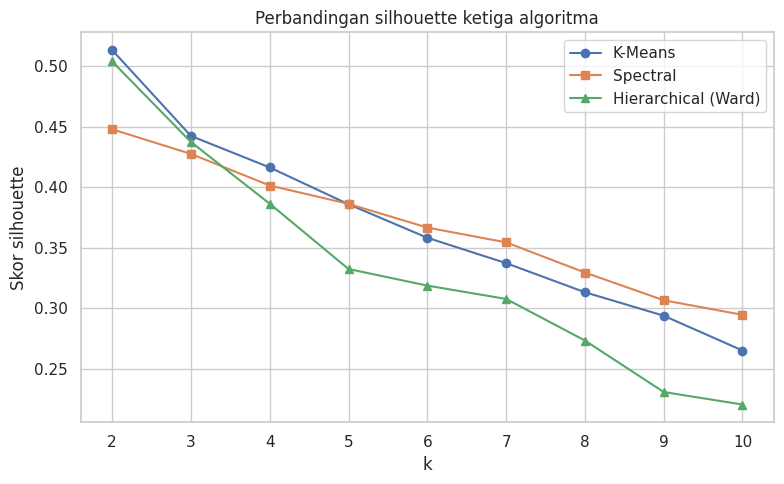

k dengan silhouette tertinggi: {'K-Means': 2, 'Spectral': 2, 'Hierarchical': 2}


In [ ]:
# clu_k_compare
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(ks, km_tbl["Silhouette"], "o-", label="K-Means")
ax.plot(ks, sp_tbl["Silhouette"], "s-", label="Spectral")
ax.plot(ks, hc_tbl["Silhouette"], "^-", label="Hierarchical (Ward)")
ax.set_xlabel("k"); ax.set_ylabel("Skor silhouette"); ax.set_title("Perbandingan silhouette ketiga algoritma"); ax.legend()
plt.tight_layout(); plt.show()

best_k = {"K-Means": int(km_tbl["Silhouette"].idxmax()), "Spectral": int(sp_tbl["Silhouette"].idxmax()),
          "Hierarchical": int(hc_tbl["Silhouette"].idxmax())}
print("k dengan silhouette tertinggi:", best_k)

#### **Penentuan Jumlah Klaster Optimal ($k$)**

* **K-Means:** Kurva *elbow* (penurunan nilai *inertia* dari 11.128 $\rightarrow$ 6.639 $\rightarrow$ 4.663) menunjukkan pola penurunan yang baik **tanpa titik siku (*elbow*) yang tajam**. Skor *silhouette* tertinggi tercapai pada **$k = 2$ (0,513)** dan mengalami penurunan secara monoton (menjadi 0,442 pada $k = 3$). Indeks *Davies-Bouldin* juga memberikan performa terbaik pada $k = 2$ (0,669) sementara *Calinski-Harabasz Index* relatif datar pada kisaran $k = 3$ hingga $6$ ($\approx 7.100 - 7.300$) sehingga kurang diskriminatif.

* **Hierarchical Clustering (Metode Ward):** Nilai *silhouette* optimal diperoleh pada $k = 2$ (0,504). Berdasarkan analisis *dendrogram*, pemisahan ini menunjukkan jarak yang paling signifikan (jarak Ward $\approx 189$, diikuti oleh 81 dan 76 pada tingkat berikutnya, serta di bawah 50 untuk $k > 5$). Hal ini mengindikasikan bahwa **pembelahan dua kelompok (*bipartisi*) merupakan struktur yang paling dominan**, sementara struktur di dalam klaster terbentuk secara bertahap tanpa celah pemisah yang tegas. Sebaliknya, metode *average* dan *single linkage* menghasilkan partisi yang *degenerate* (membentuk kelompok ekstrem seperti $4.172 + 1 + 1$ titik) dengan skor *silhouette* (0,63) yang menyesatkan karena hanya mengisolasi *outlier* semata—sehingga **keduanya tidak layak digunakan**. Adapun *complete linkage* dan *Ward* menghasilkan pembagian klaster yang jauh lebih rasional.

* **Spectral Clustering:** Skor *silhouette* dan *Davies-Bouldin* terbaik secara konsisten juga jatuh pada $k = 2$ (masing-masing 0,448 dan 0,594). Namun, pendekatan heuristik *eigengap* tidak menunjukkan celah spektral yang jelas (nilai *eigenvalue* matriks Laplacian naik secara mulus dari 0, 0,001, 0,003, hingga 0,010) sehingga tidak memberikan konklusi yang kuat. Ketiadaan komponen graf yang terputus secara alami menandakan bahwa data tidak memiliki struktur klaster yang terisolasi dengan ketat.

* **Uji Kekokohan (*Robustness*):** Transformasi logaritmik pada fitur terbukti menaikkan skor *silhouette* (mencapai 0,60 pada $k = 2$), namun tidak mengubah peringkat performa optimalnya. Selain itu, pengujian K-Means pada $k = 3$ menggunakan 20 *random seed* yang berbeda menunjukkan tingkat stabilitas yang tinggi, dengan nilai rata-rata *Adjusted Rand Index* (ARI) mencapai 0,92 (minimum 0,89).

#### **Kesimpulan Pemilihan Jumlah Klaster:**
Berdasarkan konvergensi dari seluruh metrik internal dan algoritma yang diuji, **jumlah klaster yang dipilih adalah $k = 2$**. Klaster ini secara biologis ditafsirkan sebagai kelompok abalone *"berukuran lebih kecil / belum matang"* dan *"berukuran lebih besar / matang"*. Meskipun demikian, mengingat variabel faktual (`Sex` dan kelompok usia) memiliki tiga kategori, hasil analisis pada **$k = 3$** tetap disajikan dalam laporan untuk memastikan perbandingan yang komprehensif.

In [ ]:
# Pelatihan Tiga Algoritma Klastering Berdasarkan Skenario Jumlah Klaster (k):
# Skenario (a): Menggunakan nilai k optimal berdasarkan metrik silhouette* (k = 2).
# Skenario (b): Menggunakan nilai k = 3 (disesuaikan dengan jumlah kategori faktual variabel Sex* dan kelompok usia
def fit_all(k):
    t = {}
    t0 = time.time(); l_km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit_predict(Xc); t["K-Means"] = time.time() - t0
    t0 = time.time(); l_sp = SpectralClustering(n_clusters=k, affinity="nearest_neighbors", n_neighbors=N_NEIGH,
                                                random_state=RANDOM_STATE, n_jobs=-1).fit_predict(Xc); t["Spectral"] = time.time() - t0
    t0 = time.time(); l_hc = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(Xc); t["Hierarchical"] = time.time() - t0
    return {"K-Means": l_km, "Spectral": l_sp, "Hierarchical": l_hc}, t

K_OPT = best_k["K-Means"]   # ketiga metode dievaluasi pada k yang sama agar perbandingan adil
labels_opt, time_opt = fit_all(K_OPT)
labels_k3,  time_k3  = fit_all(3)

def summarise(labels, times):
    rows = []
    for name, lab in labels.items():
        rows.append([name, len(np.unique(lab)), silhouette_score(Xc, lab), calinski_harabasz_score(Xc, lab),
                     davies_bouldin_score(Xc, lab),
                     adjusted_rand_score(sex_true, lab), normalized_mutual_info_score(sex_true, lab),
                     adjusted_rand_score(age_true, lab), normalized_mutual_info_score(age_true, lab),
                     homogeneity_score(age_true, lab), times[name]])
    return pd.DataFrame(rows, columns=["Algorithm", "k", "Silhouette", "CH", "DB", "ARI (Sex)", "NMI (Sex)",
                                       "ARI (Age grp)", "NMI (Age grp)", "Homog. (Age grp)", "Time (s)"]).set_index("Algorithm")
sum_opt, sum_k3 = summarise(labels_opt, time_opt), summarise(labels_k3, time_k3)
print(f"=== k = {K_OPT} (optimal menurut silhouette) ==="); display(sum_opt.round(3))
print("=== k = 3 ==="); display(sum_k3.round(3))

# kesesuaian antar algoritma (ARI)
names = list(labels_opt)
agree = pd.DataFrame([[adjusted_rand_score(labels_opt[a], labels_opt[b]) for b in names] for a in names], index=names, columns=names)
agree3 = pd.DataFrame([[adjusted_rand_score(labels_k3[a], labels_k3[b]) for b in names] for a in names], index=names, columns=names)
print(f"Kesesuaian antar algoritma (ARI), k = {K_OPT}"); display(agree.round(3))
print("Kesesuaian antar algoritma (ARI), k = 3"); display(agree3.round(3))

=== k = 2 (optimal menurut silhouette) ===


,k,Silhouette,CH,DB,ARI (Sex),NMI (Sex),ARI (Age grp),NMI (Age grp),Homog. (Age grp),Time (s)
Algorithm,,,,,,,,,,
K-Means,2,0.513,6782.530,0.669,0.185,0.170,0.203,0.182,0.148,0.052
Spectral,2,0.448,3716.228,0.594,0.090,0.136,0.112,0.180,0.131,1.086
Hierarchical,2,0.504,6596.178,0.677,0.185,0.170,0.221,0.199,0.162,0.611


=== k = 3 ===


,k,Silhouette,CH,DB,ARI (Sex),NMI (Sex),ARI (Age grp),NMI (Age grp),Homog. (Age grp),Time (s)
Algorithm,,,,,,,,,,
K-Means,3,0.442,7093.094,0.725,0.132,0.160,0.165,0.188,0.186,0.081
Spectral,3,0.427,4715.670,0.632,0.154,0.165,0.167,0.194,0.176,0.939
Hierarchical,3,0.437,5502.625,0.739,0.156,0.156,0.190,0.187,0.174,0.614


Kesesuaian antar algoritma (ARI), k = 2


,K-Means,Spectral,Hierarchical
K-Means,1.000,0.226,0.878
Spectral,0.226,1.000,0.233
Hierarchical,0.878,0.233,1.000


Kesesuaian antar algoritma (ARI), k = 3


,K-Means,Spectral,Hierarchical
K-Means,1.000,0.306,0.315
Spectral,0.306,1.000,0.606
Hierarchical,0.315,0.606,1.000


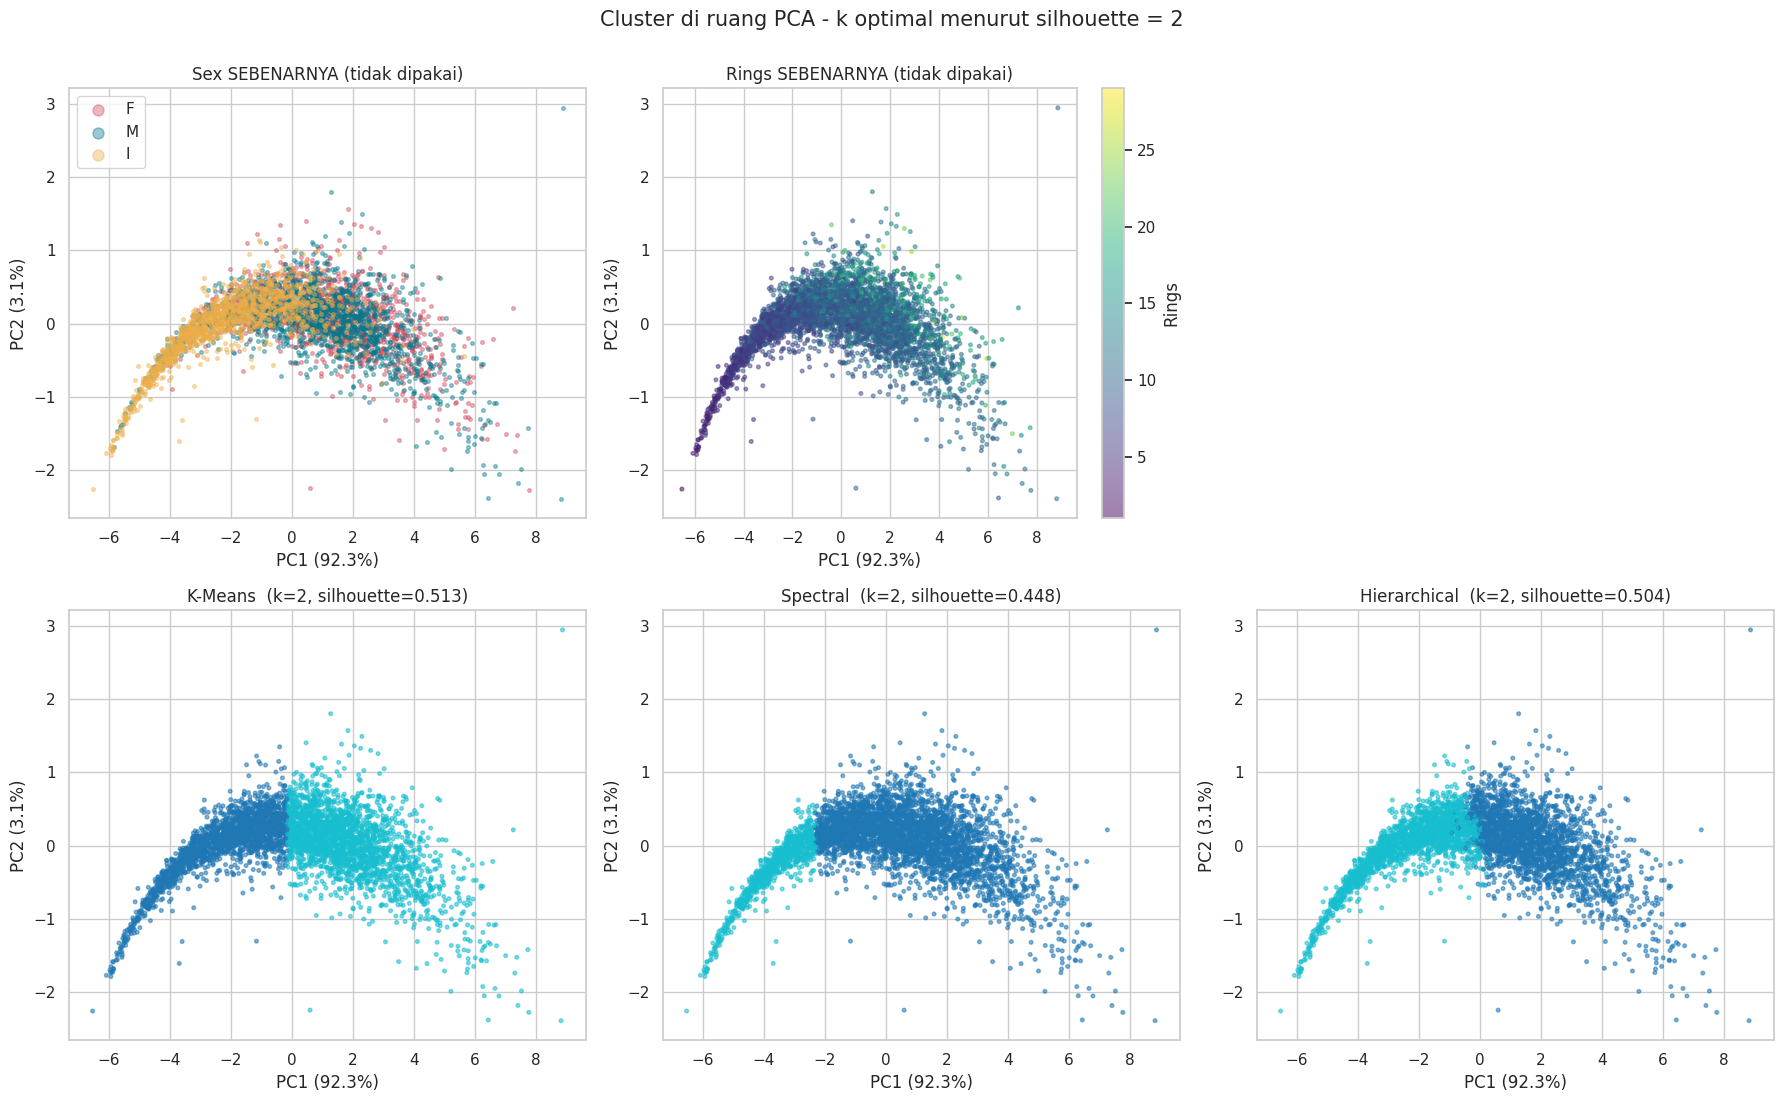

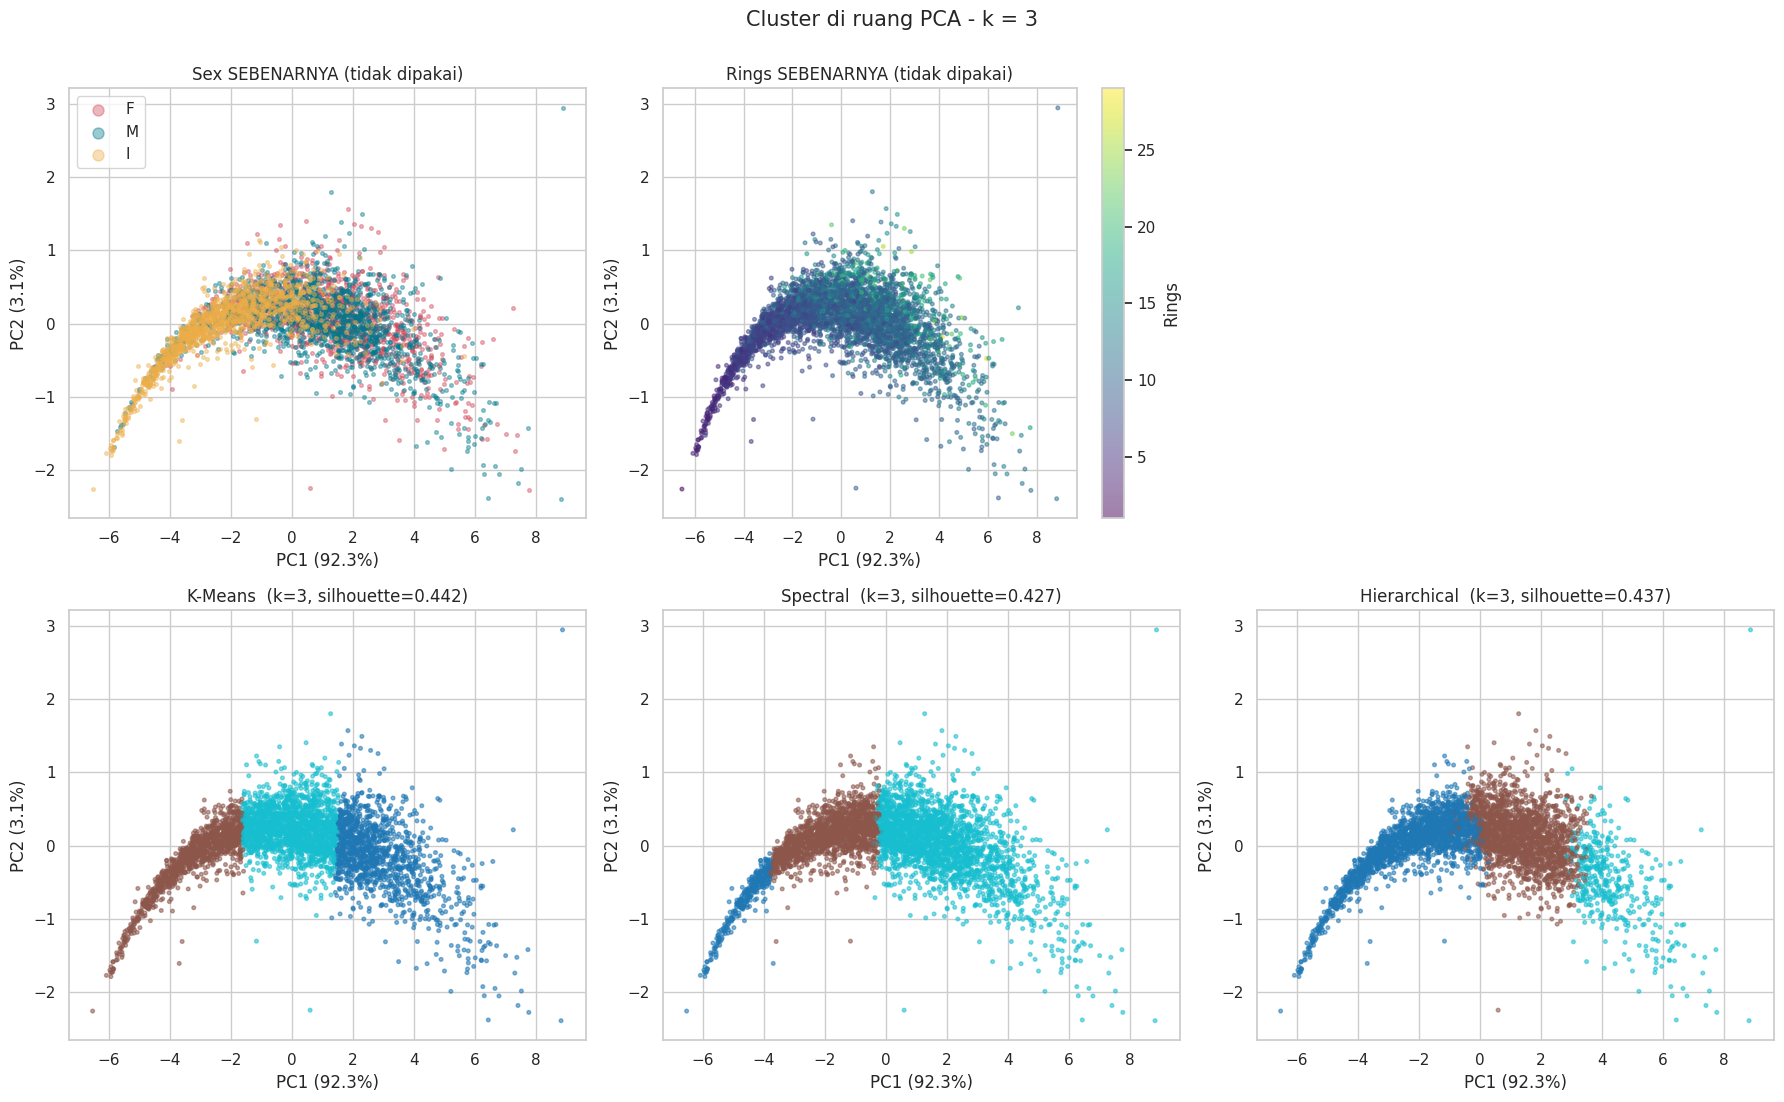

In [ ]:
# clu_pca_opt, clu_pca_k3
def plot_clusters(labels, k, title):
    fig, axes = plt.subplots(2, 3, figsize=(18, 11))
    ax = axes[0, 0]
    for s in ["F", "M", "I"]:
        m = sex_true == s; ax.scatter(Z2[m, 0], Z2[m, 1], s=7, alpha=0.4, c=SEX_COLORS[s], label=s)
    ax.set_title("Sex SEBENARNYA (tidak dipakai)"); ax.legend(markerscale=3)
    ax = axes[0, 1]
    sc = ax.scatter(Z2[:, 0], Z2[:, 1], s=7, alpha=0.5, c=df["Rings"], cmap="viridis"); plt.colorbar(sc, ax=ax, label="Rings")
    ax.set_title("Rings SEBENARNYA (tidak dipakai)")
    axes[0, 2].axis("off")
    for ax, (name, lab) in zip(axes[1], labels.items()):
        sc = ax.scatter(Z2[:, 0], Z2[:, 1], s=7, alpha=0.55, c=lab, cmap="tab10")
        ax.set_title(f"{name}  (k={k}, silhouette={silhouette_score(Xc, lab):.3f})")
    for ax in axes.ravel():
        if ax.axison: ax.set_xlabel(f"PC1 ({pca2.explained_variance_ratio_[0]*100:.1f}%)"); ax.set_ylabel(f"PC2 ({pca2.explained_variance_ratio_[1]*100:.1f}%)")
    plt.suptitle(title, y=1.0, fontsize=15); plt.tight_layout(); plt.show()
plot_clusters(labels_opt, K_OPT, f"Cluster di ruang PCA - k optimal menurut silhouette = {K_OPT}")
plot_clusters(labels_k3, 3, "Cluster di ruang PCA - k = 3")

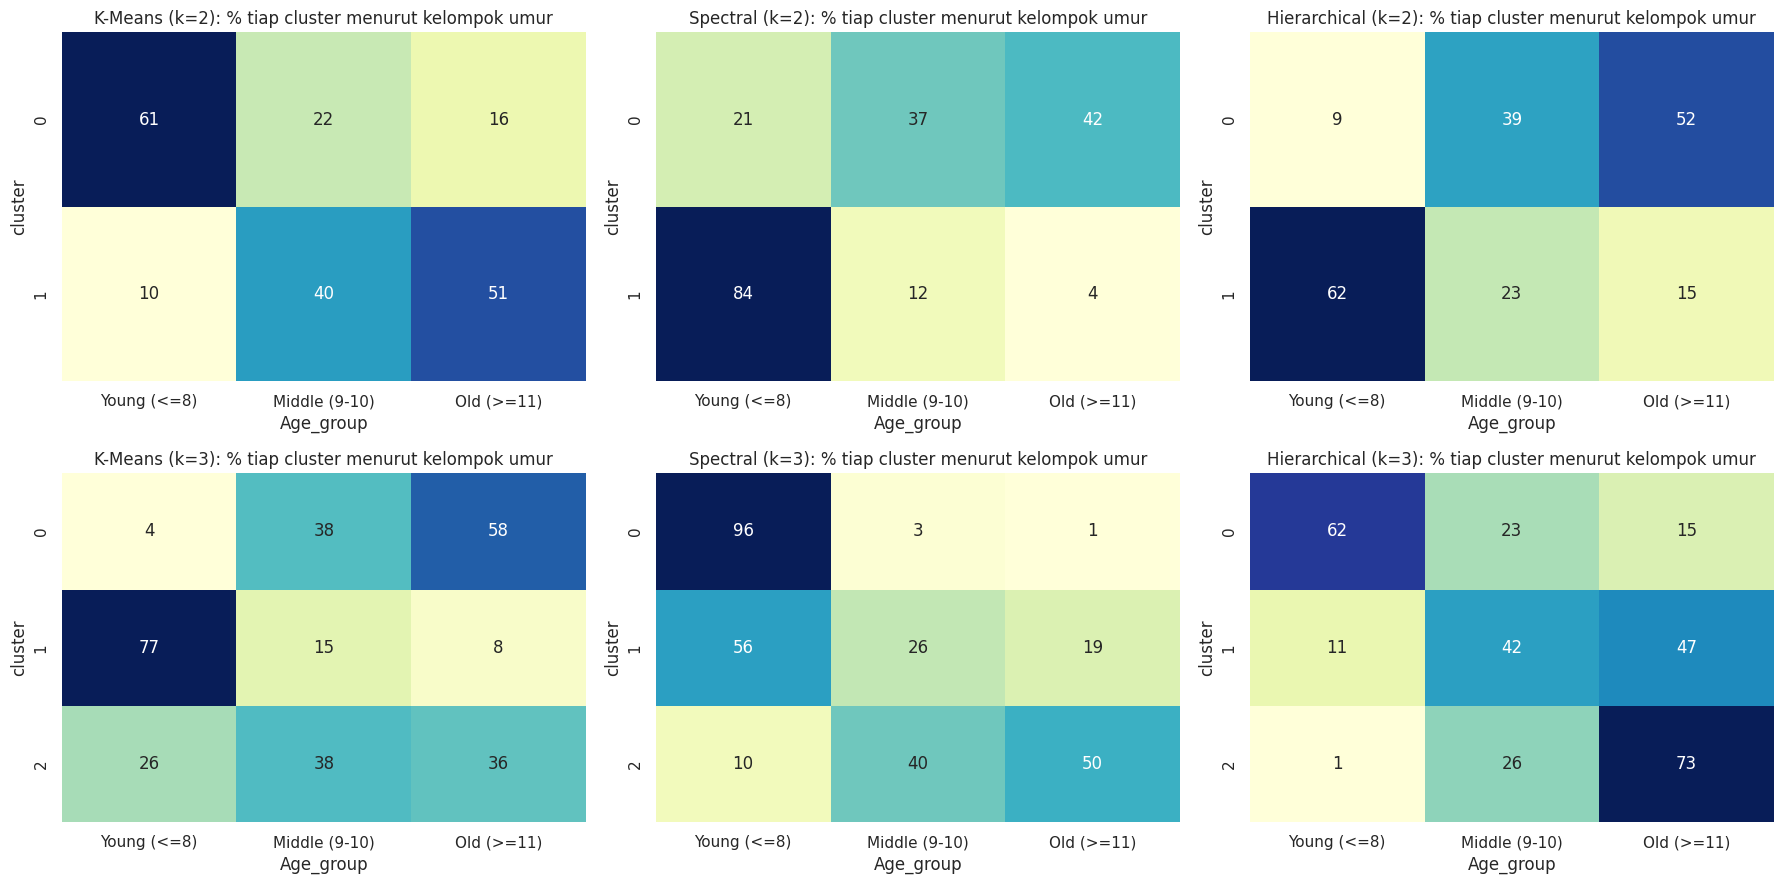

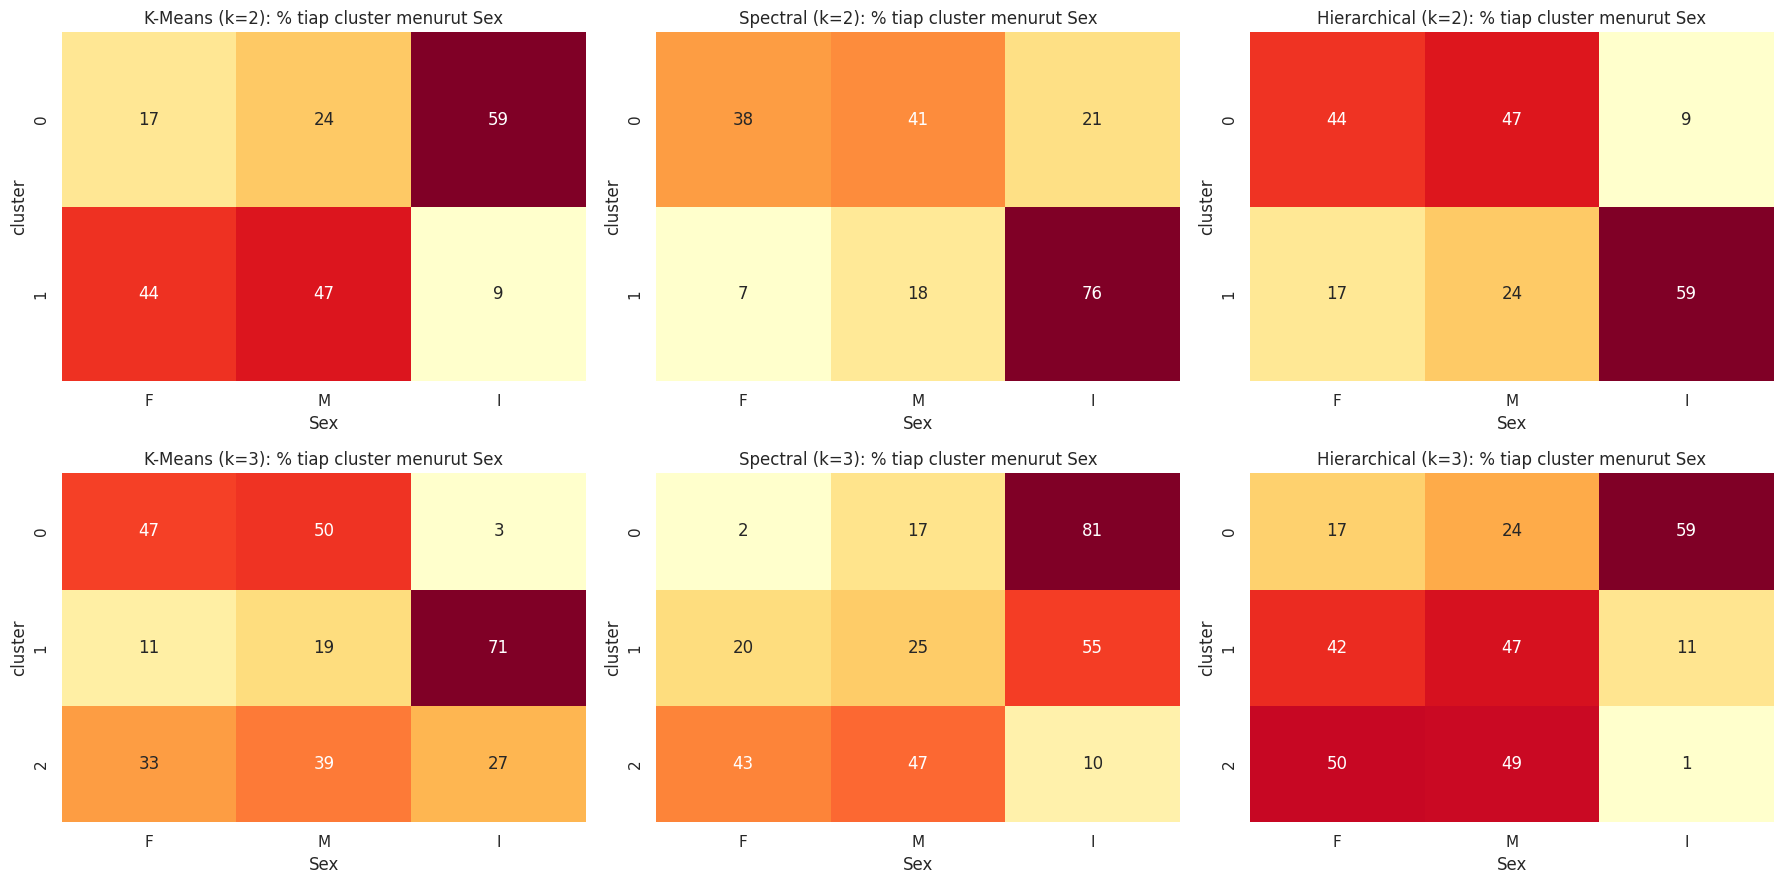

In [ ]:
# clu_crosstabs_age, clu_crosstabs_sex
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for r, (labs, k) in enumerate([(labels_opt, K_OPT), (labels_k3, 3)]):
    for ax, (name, lab) in zip(axes[r], labs.items()):
        ct = pd.crosstab(lab, df["Age_group"], normalize="index") * 100
        sns.heatmap(ct, annot=True, fmt=".0f", cmap="YlGnBu", ax=ax, cbar=False)
        ax.set_title(f"{name} (k={k}): % tiap cluster menurut kelompok umur"); ax.set_ylabel("cluster")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for r, (labs, k) in enumerate([(labels_opt, K_OPT), (labels_k3, 3)]):
    for ax, (name, lab) in zip(axes[r], labs.items()):
        ct = pd.crosstab(lab, df["Sex"], normalize="index")[["F", "M", "I"]] * 100
        sns.heatmap(ct, annot=True, fmt=".0f", cmap="YlOrRd", ax=ax, cbar=False)
        ax.set_title(f"{name} (k={k}): % tiap cluster menurut Sex"); ax.set_ylabel("cluster")
plt.tight_layout(); plt.show()

In [ ]:
# Profil Karakteristik Klaster (Satuan Asli) pada k = 3
# Menampilkan distribusi ukuran populasi klaster, komposisi jenis kelamin, serta rata-rata jumlah cincin untuk ketiga algoritma
for name, lab in labels_k3.items():
    prof = df[num_features + ["Rings"]].groupby(lab).mean()
    prof.insert(0, "n", pd.Series(lab).value_counts().sort_index())
    for s in ["F", "M", "I"]:
        prof[f"%{s}"] = pd.crosstab(lab, df["Sex"], normalize="index")[s] * 100
    print(f"----- {name} (k = 3) -----"); display(prof.round(3))
print(f"----- K-Means (k = {K_OPT}) -----")
prof = df[num_features + ["Rings"]].groupby(labels_opt["K-Means"]).mean()
prof.insert(0, "n", pd.Series(labels_opt["K-Means"]).value_counts().sort_index())
for s in ["F", "M", "I"]:
    prof[f"%{s}"] = pd.crosstab(labels_opt["K-Means"], df["Sex"], normalize="index")[s] * 100
display(prof.round(3))

----- K-Means (k = 3) -----


,n,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings,%F,%M,%I
0,1251,0.648,0.511,0.179,1.422,0.621,0.311,0.399,11.687,47.482,49.560,2.958
1,1165,0.369,0.280,0.093,0.267,0.116,0.057,0.081,7.330,10.815,18.541,70.644
2,1758,0.539,0.420,0.142,0.780,0.335,0.170,0.229,10.416,33.333,39.363,27.304


----- Spectral (k = 3) -----


,n,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings,%F,%M,%I
0,312,0.265,0.195,0.065,0.100,0.043,0.023,0.030,5.583,1.923,16.667,81.410
1,1579,0.449,0.345,0.115,0.454,0.196,0.099,0.136,8.788,20.013,25.016,54.972
2,2283,0.611,0.480,0.166,1.188,0.516,0.259,0.339,11.324,43.101,47.350,9.549


----- Hierarchical (k = 3) -----


,n,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings,%F,%M,%I
0,1924,0.422,0.323,0.107,0.405,0.177,0.088,0.120,8.216,16.996,24.064,58.940
1,1835,0.594,0.467,0.160,1.063,0.458,0.231,0.308,11.204,42.071,46.921,11.008
2,415,0.689,0.543,0.196,1.759,0.771,0.386,0.488,12.301,49.880,49.157,0.964


----- K-Means (k = 2) -----


,n,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings,%F,%M,%I
0,1939,0.422,0.323,0.108,0.405,0.174,0.088,0.121,8.318,17.122,24.136,58.742
1,2235,0.613,0.482,0.167,1.197,0.520,0.261,0.341,11.339,43.579,47.427,8.993


K-Means (k=3) stabilitas seed: ARI terhadap acuan = 0.923 (min 0.888)


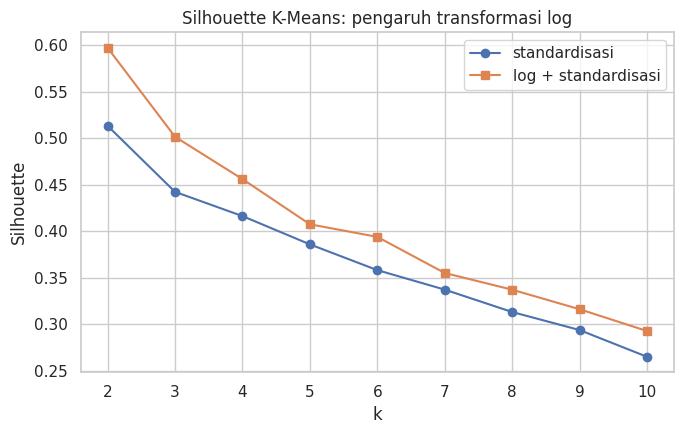

In [ ]:
# clu_stability
# Uji Kekokohan Struktur Klaster (Robustness Analysis)
# (a) Evaluasi stabilitas K-Means menggunakan 20 variasi random seed berbeda
# (b) Pengujian menggunakan fitur hasil transformasi logaritmik.
seeds_ari = [adjusted_rand_score(labels_k3["K-Means"], KMeans(3, n_init=1, random_state=s).fit_predict(Xc)) for s in range(20)]
print(f"K-Means (k=3) stabilitas seed: ARI terhadap acuan = {np.mean(seeds_ari):.3f} (min {np.min(seeds_ari):.3f})")

Xlog = StandardScaler().fit_transform(np.log1p(df[num_features] * 200))   # log dari nilai pada skala asli
sil_log = {k: silhouette_score(Xlog, KMeans(k, n_init=20, random_state=RANDOM_STATE).fit_predict(Xlog)) for k in ks}
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(ks, km_tbl["Silhouette"], "o-", label="standardisasi"); ax.plot(ks, list(sil_log.values()), "s-", label="log + standardisasi")
ax.set_xlabel("k"); ax.set_ylabel("Silhouette"); ax.set_title("Silhouette K-Means: pengaruh transformasi log"); ax.legend()
plt.tight_layout(); plt.show()

#### **Penjelasan**

##### **1. Performa Metrik Kualitas Internal dan Eksternal ($k = 2$ dan $k = 3$)**

| Algoritma | Silhouette ($k=2$, $k=3$) | Davies-Bouldin ($k=2$, $k=3$) | ARI terhadap Sex ($k=2$, $k=3$) | ARI terhadap Kelompok Usia ($k=2$, $k=3$) | NMI terhadap Kelompok Usia ($k=2$, $k=3$) |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **K-Means** | 0,513 \| 0,442 | 0,669 \| 0,725 | 0,185 \| 0,132 | 0,203 \| 0,165 | 0,182 \| 0,188 |
| **Spectral** | 0,448 \| 0,427 | 0,594 \| 0,632 | 0,090 \| 0,154 | 0,112 \| 0,167 | 0,180 \| 0,194 |
| **Hierarchical (Ward)** | 0,504 \| 0,437 | 0,677 \| 0,739 | 0,185 \| 0,156 | 0,221 \| 0,190 | 0,199 \| 0,187 |

---

##### **2. Tingkat Kesesuaian Klaster dengan Variabel Sex dan Kelompok Umur Faktual**
* **Kesesuaian dengan Variabel Sex:**
  Pemisahan klaster hanya terjadi pada dimensi kelompok infant dan kelompok dewasa, tanpa pernah berhasil memisahkan kategori jantan dan betina. Pada skenario $k = 2$, klaster kecil K-Means ($n = 1.939$) berisi 58,7% infant, sementara klaster besar ($n = 2.235$) hanya mencakup 9,0% infant. Di dalam klaster besar tersebut, proporsi betina dan jantan masing-masing tercatat sebesar 43,6% dan 47,4% yang menunjukkan bahwa atribut jenis kelamin sama sekali tidak terisolasi. Begitu pula pada skenario $k = 3$, klaster terbesar K-Means ($n = 1.251$) terdiri atas 47,5% betina, 49,6% jantan, dan 3,0% infant. Seluruh nilai *Adjusted Rand Index* (ARI) terhadap variabel jenis kelamin tercatat sangat rendah (pada kisaran 0,09 hingga 0,19).
* **Kesesuaian dengan Kelompok Umur:**
Struktur klaster menunjukkan keselarasan parsial terhadap tingkat kedewasaan biologis abalone. Hal ini terlihat dari rata-rata jumlah cincin yang tersusun secara berjenjang pada masing-masing kelompok:
  * **K-Means ($k = 2$):** Rata-rata 8,3 dan 11,3 cincin.
  * **K-Means ($k = 3$):** Rata-rata 7,3; 10,4; dan 11,7 cincin.
  * **Hierarchical Ward ($k = 3$):** Rata-rata 8,2; 11,2; dan 12,3 cincin.
Meskipun demikian, nilai *Adjusted Rand Index* (ARI) terhadap kelompok usia tetap tergolong lemah (berkisar antara 0,11 hingga 0,22). Kondisi ini terjadi karena variabel jumlah cincin dan ukuran fisik memiliki tingkat tumpang tindih yang tinggi (koefisien korelasi $r \approx 0,6$) sehingga batas klaster terbentuk sekadar sebagai irisan melintang pada gradien ukuran fisik yang kontinu. Tingkat kecocokan terbaik tercatat pada metode *Hierarchical Ward* pada $k = 2$ dengan nilai ARI sebesar 0,22.
* **Konklusi Hubungan:**
  Secara keseluruhan, algoritma *clustering* berhasil memetakan ukuran tubuh serta tahapan kedewasaan fisik, namun tidak mampu membedakan jenis kelamin secara akurat dan hanya merekonstruksi kelompok umur sekalipun terbatas.

##### **3. Analisis Struktur Data di Balik Hasil Clustering**
Hasil proyeksi PCA memperlihatkan sebaran data yang memanjang, sedikit melengkung, dan menyempit:
* Komponen utama pertama (PC1) yang merepresentasikan ukuran fisik menyumbang 92% dari total variansi.
* Tidak ditemukan adanya celah pemisah (*density gap*) yang membagi kelompok data secara alami dan tegas.

Akibat karakteristik tersebut, setiap algoritma *clustering* hanya bertindak sebagai pemotong gradien menjadi beberapa bagian. Letak garis pemotongan ini lebih ditentukan oleh sifat dasar dari perhitungan matematid di setiap algoritma, bukan karena mencerminkan batas kelompok biologis yang sesuai dengan kenyatannya.

##### **4. Karakteristik Algoritma dan Rekomendasi Penggunaan**
* **K-Means:** Mencatatkan metode ini mempunyai nilai *silhouette* tertinggi (0,513) dengan waktu komputasi tercepat ($\approx 0,03$ detik). Dimana algoritma ini mengasumsikan bahwa klaster berbentuk kompak dan memiliki keragaman yang setara. Pada sebaran data yang memanjang, K-Means menghasilkan irisan kelompok berukuran seragam yang mudah diringkas melalui titik pusat (*centroid*) sehingga sangat ideal untuk keperluan pengelompokan ukuran fisik.
* **Hierarchical Clustering (Ward):** Menghasilkan pembagian kelompok yang hampir mirip dengan K-Means (nilai ARI mencapai 0,88 pada $k = 2$) karena sama-sama meminimalkan keragaman di dalam kelompok. Keunggulannya terletak pada diagram pohon (*dendrogram*) yang memperlihatkan bahwa pembelahan menjadi dua kelompok adalah struktur yang paling dominan. Sementara itu, metode *average* dan *single linkage* gagal karena hanya berujung pada pengisolasian data ekstrem (*outlier*).
* **Spectral Clustering:** Dirancang untuk mengikuti bentuk sebaran data yang melengkung atau memanjang. Namun, karena data abalone membentuk satu rentang yang kontinu dan tidak terputus, struktur graf yang terbentuk berubah menjadi satu rantai panjang. Akibatnya, pemotongan kelompok jatuh pada area yang kepadatannya rendah sehingga mengisolasi sebagian kecil spesimen terkecil dan menggabungkan sisanya menjadi satu kelompok raksasa. Metode ini mencatatkan skor *silhouette* paling rendah dan kecocokan paling lemah terhadap jenis kelamin.
Dengan temuan tersebut dapat disimpulkan bahwa **K-Means** atau **Hierarchical Ward** dapat digunakan pada fitur yang sudah distandardisasi. Metode *Spectral clustering* tidak cocok digunakan di sini karena data tidak memiliki kelompok terpisah dengan celah yang jelas.

##### **5. Keterbatasan**
Nilai *silhouette* di kisaran 0,4 hingga 0,5 pada analisis ini muncul karena sebaran data memanjang secara linear, bukan karena ada kelompok biologis yang benar-benar terpisah secara alami. Tingkat kemiripan antar fitur yang sangat tinggi membuat seluruh variabel fisik pada dasarnya hanya mengukur hal yang sama (ukuran tubuh). Oleh sebab itu, hasil dari bagian ini wajib diinterpretasikan sebagai **pengelompokan berdasarkan ukuran fisik** bukan penemuan kelompok biologis yang baru.

## **6. Kesimpulan**

1. **EDA:** Data telah bersih setelah membuang 3 baris anomali. Ketujuh ukuran fisik pada dasarnya merepresentasikan satu dimensi utama ukuran tubuh (PC1 menyumbang 92% variansi). Kategori *infant* menunjukkan perbedaan yang sangat jelas dibandingkan abalone dewasa sedangkan kategori jantan dan betina tidak dapat dibedakan dengan mudah.
2. **Klasifikasi Tiga Kelas (SVM vs. RF):** Akurasi pada data uji tercatat sebesar 56,5% (SVM) dan 56,2% (RF) tanpa perbedaan yang signifikan secara statistik ($p = 0,35$). Random Forest memberikan hasil yang sedikit lebih seimbang (makro F1 0,55 dan 0,52; *recall* betina 0,36 dan 0,16), sementara SVM sedikit lebih unggul dalam ketepatan (*precision*). Kelompok *infant* berhasil dikenali dengan baik, namun pembedaan antara jantan dan betina mendekati tebakan acak sehingga kisaran akurasi 56%. Dimana ini merupakan batas maksimal informasi yang dapat diekstrak dari fitur fisik yang ada pada data.
3. **Klasifikasi Biner (*Infant* dan *Adult*):** Akurasi pada data uji mencapai 85,8% (SVM) dan 84,8% (RF) dengan *cross-validation* 82%–83%. Klasifikasi inilah yang terbukti andal dan dapat dilakukan secara efektif menggunakan fitur ukuran fisik.
4. **Analisis Regresi (*Rings*):** *Multiple Linear Regression* (MSE uji 5,26) menunjukkan performa yang lebih baik daripada *Simple Linear Regression* (6,51) dan regresi polinomial (6,34). Model *Random Forest* mencapai MSE terbaik (4,71), namun mengalami *overfitting*. Secara umum, sekitar setengah dari total variansi jumlah cincin (*rings*) dapat dijelaskan melalui ukuran tubuh, di mana spesimen berusia lanjut cenderung mengalami estimasi yang terlalu rendah (*underestimated*).
5. **Analisis Klaster (*Clustering*):** Ketiga algoritma dan seluruh metrik internal sepakat memilih $k = 2$ (mengelompokkan abalone menjadi kategori *"kecil/belum matang"* dan *"besar/matang"*). Struktur klaster terbentuk berdasarkan ukuran tubuh dan tahap kedewasaan, bukan berdasarkan jenis kelamin. *K-Means* dan *Hierarchical Ward* terbukti paling sesuai untuk menangani struktur data yang kontinu ini, sementara *Spectral Clustering* tidak memberikan keunggulan tambahan.
6. **Konklusi: ** Ukuran fisik abalone secara efektif merefleksikan **ukuran dan tingkat kematangan** spesimen sehingga sangat berguna untuk memprediksi umur (*rings*) serta status kedewasaan (*infant* vs. *adult*). Meskipun demikian, ukuran fisik tersebut hampir tidak membawa informasi apa pun mengenai jenis kelamin abalone.